In [1]:
import numpy as np
import time
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator


import os
from Algoritmo_Gaussiano.cpd import CPD
from Algoritmo_Empiricas.Empirical_CPD import EmpiricalCPD
from Algoritmos_Benchmark.Window_RBF import detectar_window_rbf
from Algoritmos_Benchmark.Roerich_KL import detectar_cambios_roerich
from Utils.detection import detect
from Utils.metrics_sup import metrics
from Utils.tools import best_params_sh, grafica_comparativa_wasserstein_serie, generar_tabla_desde_diccionarios, plot_boxplots
from Series_Prueba.experimentos import generar_experimento_ar1, generar_experimento_ar2, generar_experimento_senoidal, ar2_noise

# Funciones Auxiliares

## Suavizamiento Prueba

In [44]:
def triangular_smooth(distancias, window):
    y = np.asarray(distancias, dtype=np.float64)


    offsets = np.arange(
        -window,
        window + 1
    )

    kernel = np.maximum(
        1.0 - np.abs(offsets) / window,
        0.0
    )

    kernel = kernel / kernel.sum()

    padded = np.pad(
        y,
        pad_width=window,
        mode="reflect"
    )

    smoothed = np.convolve(
        padded,
        kernel,
        mode="valid"
    )

    return smoothed

# 1. Suavizamiento

## 1.1. Múltiples puntos de cambio

In [3]:
ar1_1, cps_ar1_1, segmentos_ar1_1 = generar_experimento_ar1(
            N=1500,
            n_segmentos=15,
            min_sep=50,
            max_sep=150,
            seed=1234
        )

ar1_2, cps_ar1_2, segmentos_ar1_2 = generar_experimento_ar1(
            N=1500,
            n_segmentos=15,
            min_sep=50,
            max_sep=150,
            seed=1235
        )


ar2_1, cps_ar2_1, segmentos_ar2_1 = generar_experimento_ar2(
            N=1500,
            n_segmentos=15,
            min_sep=50,
            max_sep=150,
            seed=1234
        )

ar2_2, cps_ar2_2, segmentos_ar2_2 = generar_experimento_ar2(
            N=1500,
            n_segmentos=15,
            min_sep=50,
            max_sep=150,
            seed=1235
        )

In [4]:
cpd_ar1_1 = CPD(ar1_1, window=50, t=1, smooth=True, temporal_comp=True)
cpd_ar1_2 = CPD(ar1_2, window=50, t=1, smooth=True, temporal_comp=True)
cpd_ar2_1 = CPD(ar2_1, window=50, t=1, smooth=True, temporal_comp=True)
cpd_ar2_2 = CPD(ar2_2, window=50, t=1, smooth=True, temporal_comp=True)

distancias_ar1_1_bspline = cpd_ar1_1.distancias()
distancias_ar1_2_bspline = cpd_ar1_2.distancias()
distancias_ar2_1_bspline = cpd_ar2_1.distancias()
distancias_ar2_2_bspline = cpd_ar2_2.distancias()

distancias_ar1_1 = cpd_ar1_1.distancias_raw_
distancias_ar1_2 = cpd_ar1_2.distancias_raw_
distancias_ar2_1 = cpd_ar2_1.distancias_raw_
distancias_ar2_2 = cpd_ar2_2.distancias_raw_

distancias_ar_1_1_filter_25 = triangular_smooth(distancias_ar1_1, 25)
distancias_ar_1_2_filter_25 = triangular_smooth(distancias_ar1_2, 25)
distancias_ar_2_1_filter_25 = triangular_smooth(distancias_ar2_1, 25)
distancias_ar_2_2_filter_25 = triangular_smooth(distancias_ar2_2, 25)

distancias_ar_1_1_filter_50 = triangular_smooth(distancias_ar1_1, 50)
distancias_ar_1_2_filter_50 = triangular_smooth(distancias_ar1_2, 50)
distancias_ar_2_1_filter_50 = triangular_smooth(distancias_ar2_1, 50)
distancias_ar_2_2_filter_50 = triangular_smooth(distancias_ar2_2, 50)


In [5]:
np.array_equal(distancias_ar1_2_bspline, distancias_ar_1_2_filter_25)

True

In [6]:
def grafica_comparativa_wasserstein(comparaciones, title):
    fig, axes = plt.subplots(
        2,
        2,
        figsize=(16, 10)
    )

    axes = axes.flatten()

    for ax, (original, suavizada, window, titulo, cps) in zip(
        axes,
        comparaciones
    ):
        original = np.asarray(original)
        suavizada = np.asarray(suavizada)
        cps = np.atleast_1d(cps)

        # Posiciones correspondientes en la serie original
        x = np.arange(len(original)) + window

        ax.plot(
            x,
            original,
            color="#2878B5",
            linewidth=1.3,
            alpha=0.65,
            label="Distancia original"
        )

        ax.plot(
            x,
            suavizada,
            color="#E87500",
            linewidth=2.4,
            label="Suavizamiento triangular"
        )

        for i, cp in enumerate(cps):
            ax.axvline(
                x=cp,
                color="#C62828",
                linestyle="--",
                linewidth=1.8,
                alpha=0.85,
                label="Punto de cambio real" if i == 0 else None
            )

        ax.set_title(
            titulo,
            fontsize=13,
            fontweight="bold"
        )

        ax.set_xlabel("Índice temporal")
        ax.set_ylabel("Distancia de Wasserstein")

        ax.grid(
            alpha=0.25,
            linestyle="--"
        )

        ax.legend(
            frameon=True,
            fontsize=10
        )


    fig.suptitle(
        title,
        fontsize=17,
        fontweight="bold",
        y=1.01
    )

    plt.tight_layout()
    plt.show()

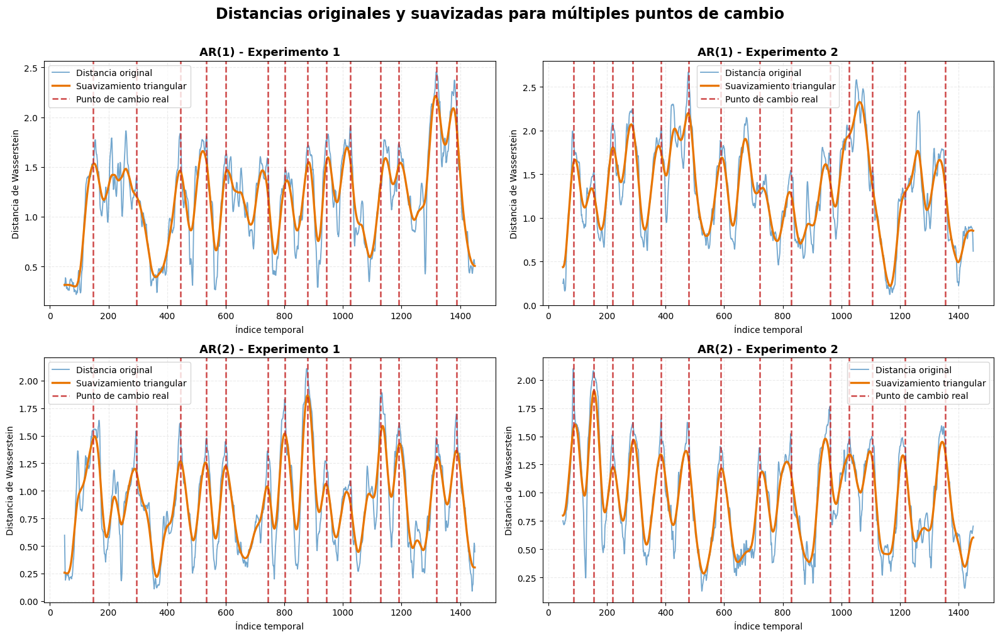

In [7]:
comparaciones = [
    (
        distancias_ar1_1,
        distancias_ar_1_1_filter_25,
        cpd_ar1_1.window,
        "AR(1) - Experimento 1",
        cps_ar1_1
    ),
    (
        distancias_ar1_2,
        distancias_ar_1_2_filter_25,
        cpd_ar1_2.window,
        "AR(1) - Experimento 2",
        cps_ar1_2
    ),
    (
        distancias_ar2_1,
        distancias_ar_2_1_filter_25,
        cpd_ar2_1.window,
        "AR(2) - Experimento 1",
        cps_ar2_1
    ),
    (
        distancias_ar2_2,
        distancias_ar_2_2_filter_25,
        cpd_ar2_2.window,
        "AR(2) - Experimento 2",
        cps_ar2_2
    )
]


grafica_comparativa_wasserstein(comparaciones, "Distancias originales y suavizadas para múltiples puntos de cambio")

## 1.2. Un punto de cambio

In [8]:
ar1_1_1cp, cps_ar1_1_1cp, segmentos_ar1_1_1cp = generar_experimento_ar1(
            N=500,
            n_segmentos=2,
            min_sep=100,
            max_sep=100,
            punto_cambio=250,
            seed=1234
        )

ar1_2_1cp, cps_ar1_2_1cp, segmentos_ar1_2_1cp = generar_experimento_ar1(
            N=500,
            n_segmentos=2,
            min_sep=100,
            max_sep=100,
            punto_cambio=250,
            seed=1235
        )


ar2_1_1cp, cps_ar2_1_1cp, segmentos_ar2_1_1cp = generar_experimento_ar2(
            N=500,
            n_segmentos=2,
            min_sep=100,
            max_sep=100,
            punto_cambio=250,
            seed=1234
        )

ar2_2_1cp, cps_ar2_2_1cp, segmentos_ar2_2_1cp = generar_experimento_ar2(
            N=500,
            n_segmentos=2,
            min_sep=100,
            max_sep=100,
            punto_cambio=250,
            seed=1235
        )

In [9]:
cpd_ar1_1_1cp = CPD(ar1_1_1cp, window=100, t=1, smooth=True, temporal_comp=True)
cpd_ar1_2_1cp = CPD(ar1_2_1cp, window=100, t=1, smooth=True, temporal_comp=True)
cpd_ar2_1_1cp = CPD(ar2_1_1cp, window=100, t=1, smooth=True, temporal_comp=True)
cpd_ar2_2_1cp = CPD(ar2_2_1cp, window=100, t=1, smooth=True, temporal_comp=True)

distancias_ar1_1_bspline_1cp = cpd_ar1_1_1cp.distancias()
distancias_ar1_2_bspline_1cp = cpd_ar1_2_1cp.distancias()
distancias_ar2_1_bspline_1cp = cpd_ar2_1_1cp.distancias()
distancias_ar2_2_bspline_1cp = cpd_ar2_2_1cp.distancias()

distancias_ar1_1_1cp = cpd_ar1_1_1cp.distancias_raw_
distancias_ar1_2_1cp = cpd_ar1_2_1cp.distancias_raw_
distancias_ar2_1_1cp = cpd_ar2_1_1cp.distancias_raw_
distancias_ar2_2_1cp = cpd_ar2_2_1cp.distancias_raw_



distancias_ar_1_1_filter_50_1cp = triangular_smooth(distancias_ar1_1_1cp, 50)
distancias_ar_1_2_filter_50_1cp = triangular_smooth(distancias_ar1_2_1cp, 50)
distancias_ar_2_1_filter_50_1cp = triangular_smooth(distancias_ar2_1_1cp, 50)
distancias_ar_2_2_filter_50_1cp = triangular_smooth(distancias_ar2_2_1cp, 50)


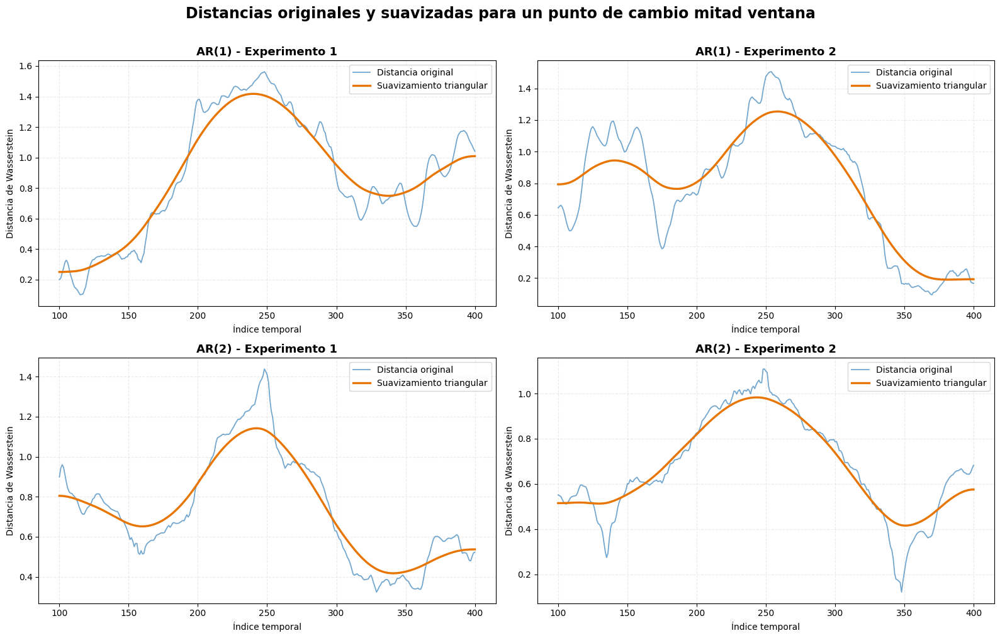

In [10]:
comparaciones = [
    (
        distancias_ar1_1_1cp,
        distancias_ar_1_1_filter_50_1cp,
        cpd_ar1_1_1cp.window,
        "AR(1) - Experimento 1"
    ),
    (
        distancias_ar1_2_1cp,
        distancias_ar_1_2_filter_50_1cp,
        cpd_ar1_2_1cp.window,
        "AR(1) - Experimento 2"
    ),
    (
        distancias_ar2_1_1cp,
        distancias_ar_2_1_filter_50_1cp,
        cpd_ar2_1_1cp.window,
        "AR(2) - Experimento 1"
    ),
    (
        distancias_ar2_2_1cp,
        distancias_ar_2_2_filter_50_1cp,
        cpd_ar2_2_1cp.window,
        "AR(2) - Experimento 2"
    )
]


fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 10)
)

axes = axes.flatten()

for ax, (original, suavizada, window, titulo) in zip(
    axes,
    comparaciones
):
    original = np.asarray(original)
    suavizada = np.asarray(suavizada)

    # Posiciones correspondientes en la serie original
    x = np.arange(len(original)) + window

    ax.plot(
        x,
        original,
        color="#2878B5",
        linewidth=1.3,
        alpha=0.65,
        label="Distancia original"
    )

    ax.plot(
        x,
        suavizada,
        color="#E87500",
        linewidth=2.4,
        label="Suavizamiento triangular"
    )

    ax.set_title(
        titulo,
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xlabel("Índice temporal")
    ax.set_ylabel("Distancia de Wasserstein")

    ax.grid(
        alpha=0.25,
        linestyle="--"
    )

    ax.legend(
        frameon=True,
        fontsize=10
    )


fig.suptitle(
    "Distancias originales y suavizadas para un punto de cambio mitad ventana",
    fontsize=17,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()

# 2. Experimentos Series de Tiempo Simuladas

## Funciones Auxiliares

In [6]:
import pandas as pd
from pathlib import Path

def exportar_excel(listas, ruta_archivo, hojas=["Hoja1", "Hoja2", "Hoja3", "Hoja4"]):

    ruta = Path(ruta_archivo)
    ruta.parent.mkdir(parents=True, exist_ok=True)

    with pd.ExcelWriter(ruta, engine="openpyxl") as writer:

        for i, lista in enumerate(listas):
            pd.DataFrame(lista).to_excel(
                writer, sheet_name=hojas[i], index=False
            )
        

## 2.1 AR(1)

### 2.1.1 Múltiples puntos de cambio

In [38]:
def experiment_ar1_temporal_dependence(w=50, delta=20):
    metricas_ar1_gauss_fw = []
    metricas_ar1_emp_fw = []
    metricas_ar1_roerich = []
    metricas_ar1_window_rbf = []

    for i in range(200):
        print(i)
        ar1, cps_ar1, segmentos_ar1 = generar_experimento_ar1(
                    N=2000,
                    n_segmentos=20,
                    min_sep=50,
                    max_sep=150,
                    seed=1234+i
                )
        
        #Gaussiano
        cpd_ar1 = CPD(ar1, window=w, t=1, medias=True, smooth=True, temporal_comp=True)
        distancias_ar1 = cpd_ar1.distancias()
        cps_detect = detect(distancias_ar1, w)
        metricas_ar1_gauss_fw.append(metrics(cps_ar1, cps_detect, delta, 2000)[0])

        #Empírico
        cpd_ar1_emp = EmpiricalCPD(ar1, window=w, smooth=True)
        distancias_ar1_emp = cpd_ar1_emp.distancias()
        cps_detect_emp = detect(distancias_ar1_emp, w)
        metricas_ar1_emp_fw.append(metrics(cps_ar1, cps_detect_emp, delta, 2000)[0])

        #Roerich KL
        puntos_cambio = detectar_cambios_roerich(
                                        ar1,
                                        window_size=w,
                                        seed=42,
                                        periods=3
                                    )
        
        metricas_ar1_roerich.append(metrics(cps_ar1, puntos_cambio, delta, len(ar1))[0])

        #Window RBF
        puntos_cambio = detectar_window_rbf(
                                        ar1,
                                        window=w
                                    )
        
        metricas_ar1_window_rbf.append(metrics(cps_ar1, puntos_cambio, delta, len(ar1))[0])
        
    return metricas_ar1_gauss_fw, metricas_ar1_emp_fw, metricas_ar1_roerich, metricas_ar1_window_rbf

In [39]:
lists_metrics_ar1 = []
windows = [25, 30, 40, 50]
for w in windows:
    print(f'WINDOW SIZE: {w}')
    lists_metrics_ar1.append(experiment_ar1_temporal_dependence(w=w, delta=20))

WINDOW SIZE: 25
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
WINDOW SIZE: 30
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95


In [40]:
for metricas, w in zip(lists_metrics_ar1, windows):
    exportar_excel(metricas, f"Resultados_Series_Simuladas/AR(1)_Temporal_Dependency/Tables/ar1_metrics_window_{w}.xlsx", ["Gauss", "Empirical", "Roerich-KL", "Window-RBF"])

WINDOW SIZE: 25


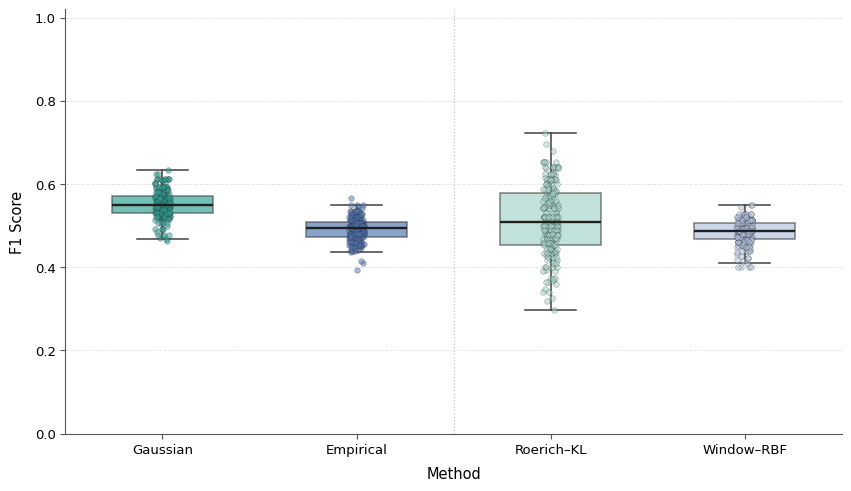

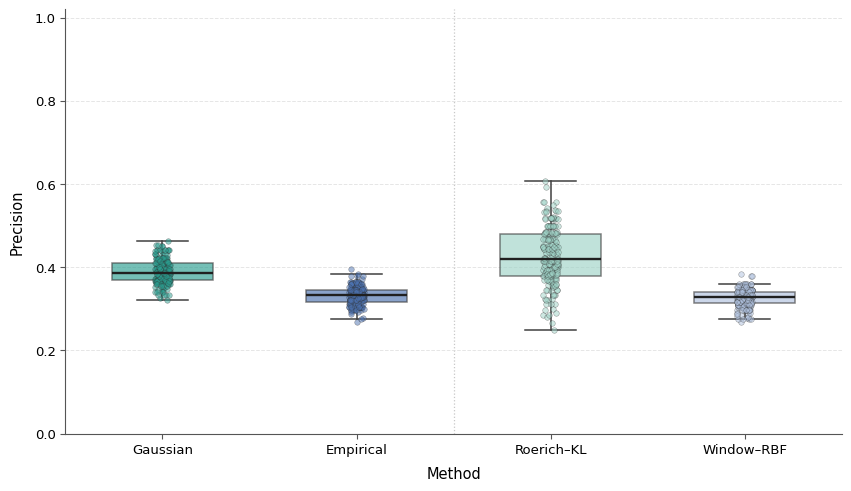

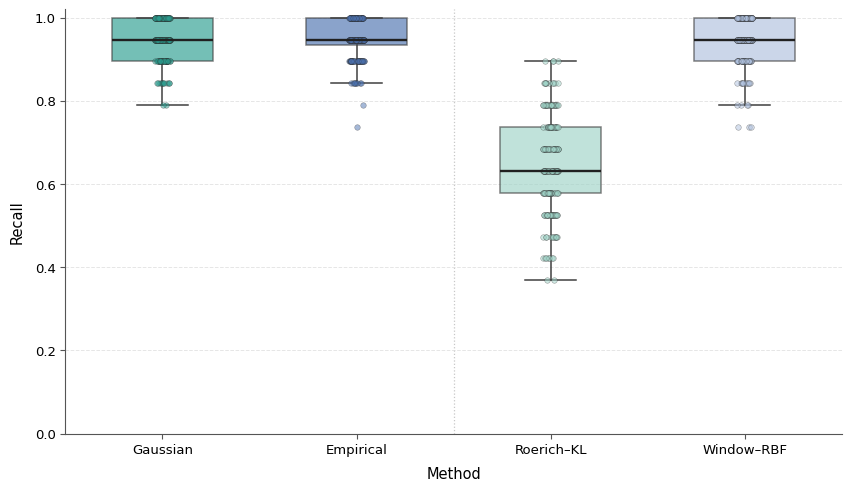

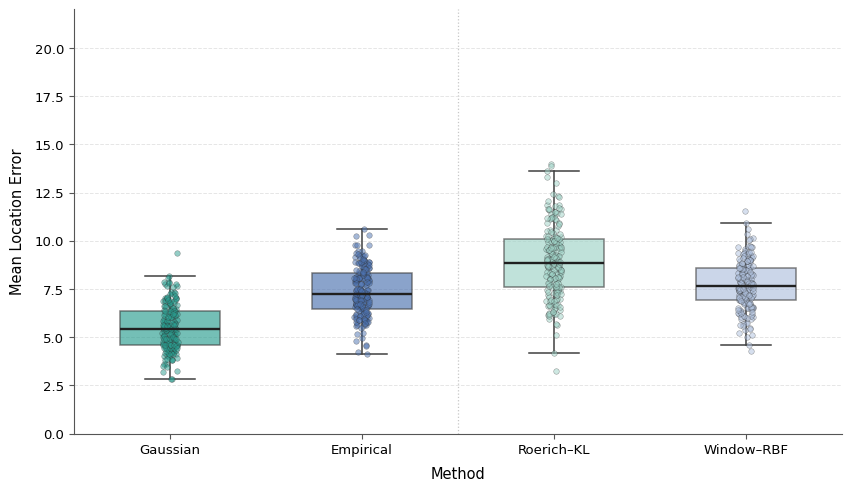

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.388860,0.948158,0.551098,5.496387
1,Empirical,0.331850,0.947895,0.491326,7.358144
2,Roerich-KL,0.425252,0.648421,0.512834,8.913747
3,Window-RBF,0.325518,0.945526,0.484134,7.707229


WINDOW SIZE: 30


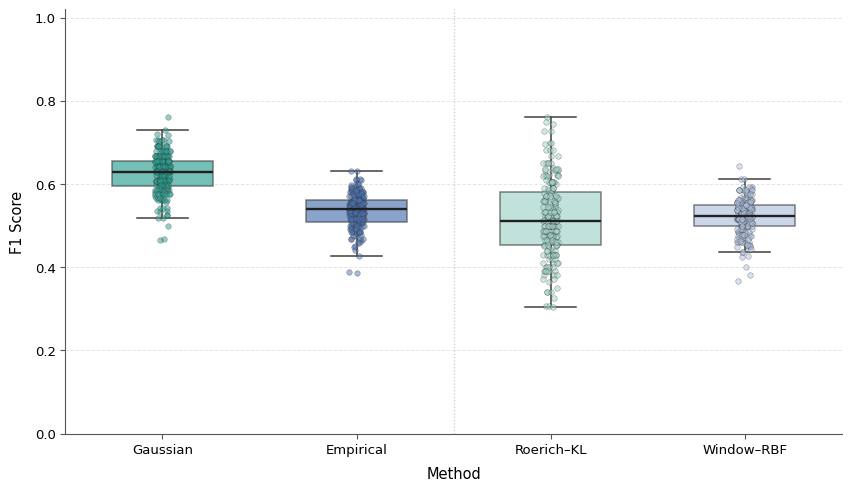

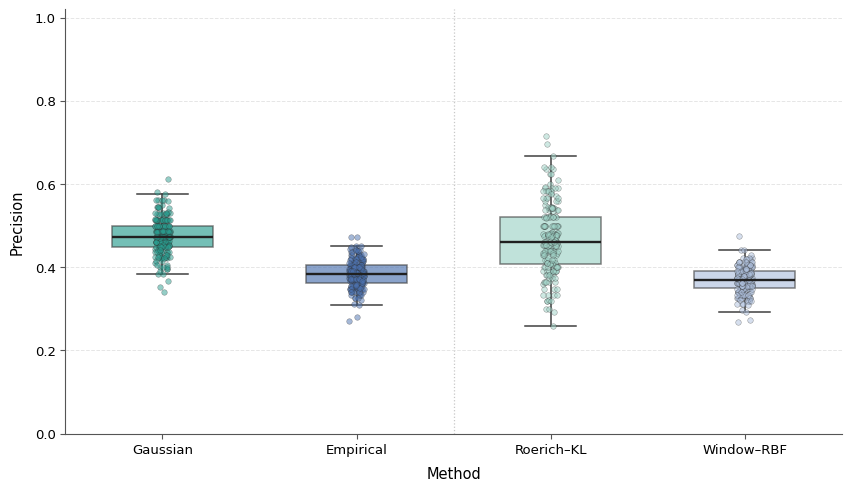

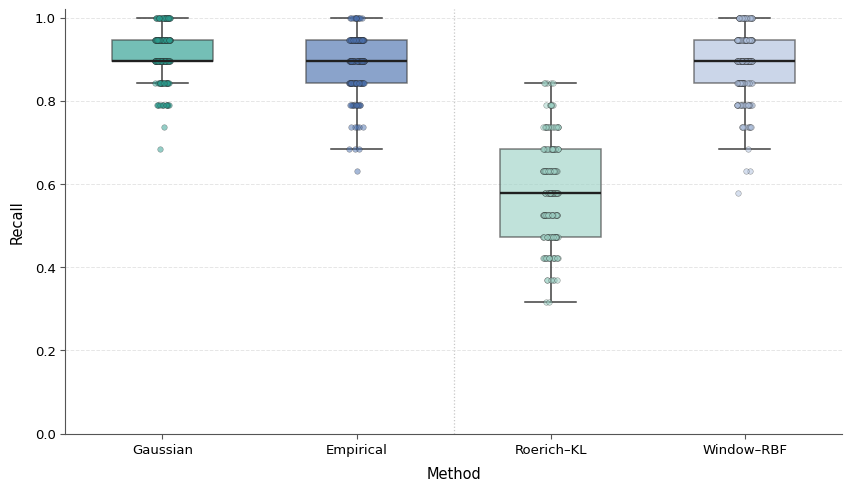

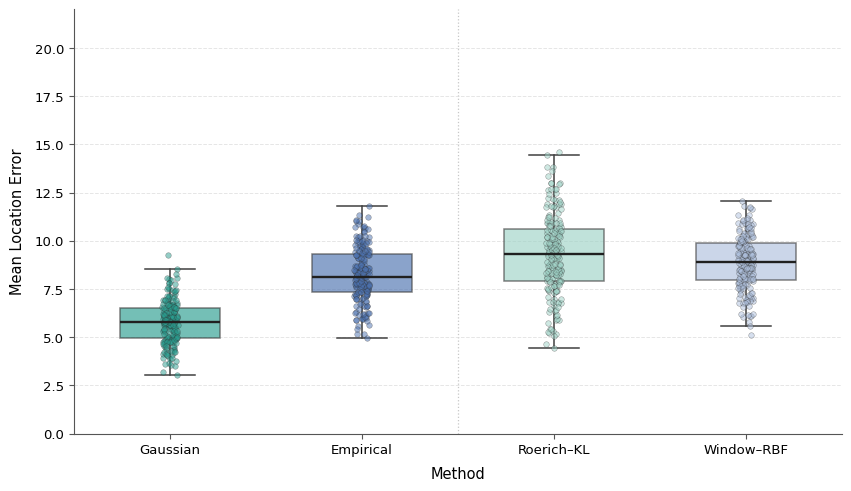

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.475406,0.914211,0.624849,5.768687
1,Empirical,0.384018,0.891316,0.536236,8.248883
2,Roerich-KL,0.468121,0.580789,0.517294,9.308375
3,Window-RBF,0.369606,0.887632,0.521645,8.865753


WINDOW SIZE: 40


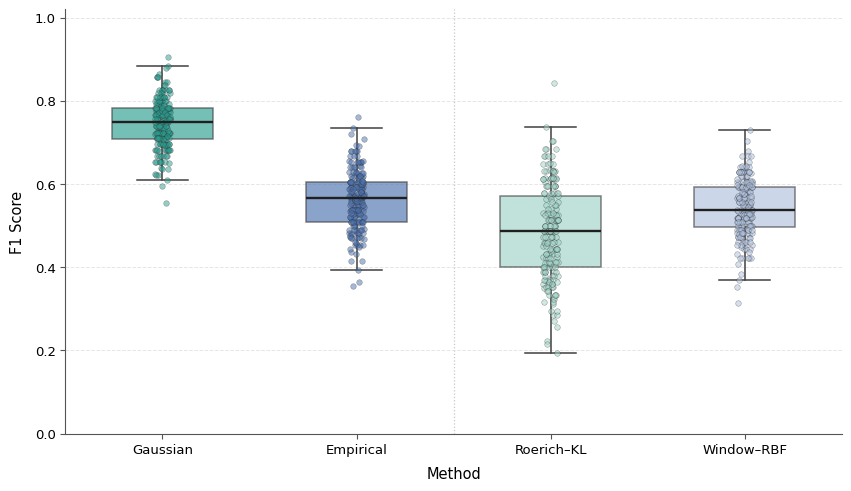

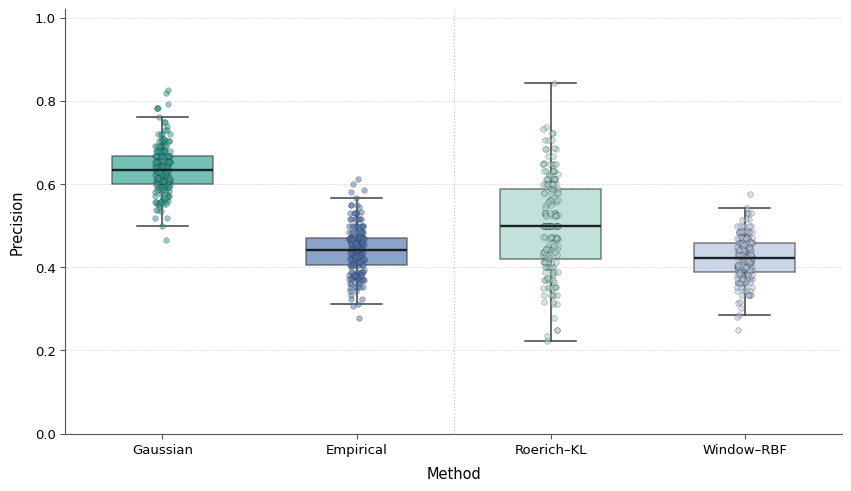

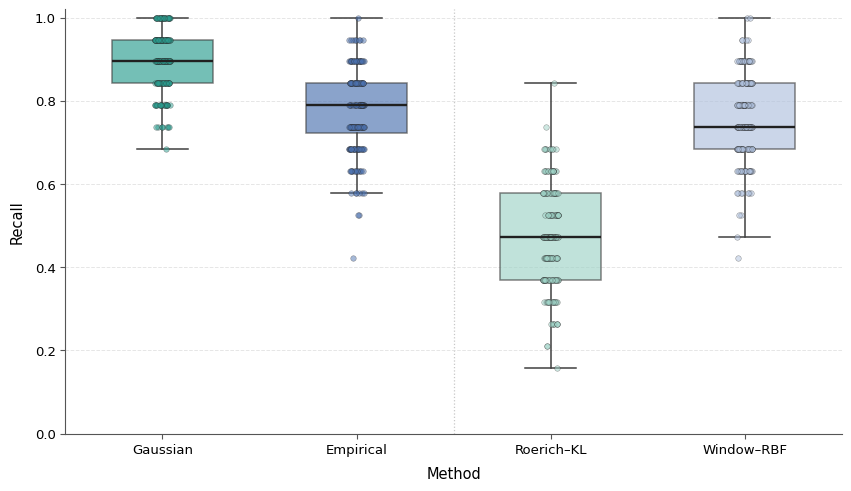

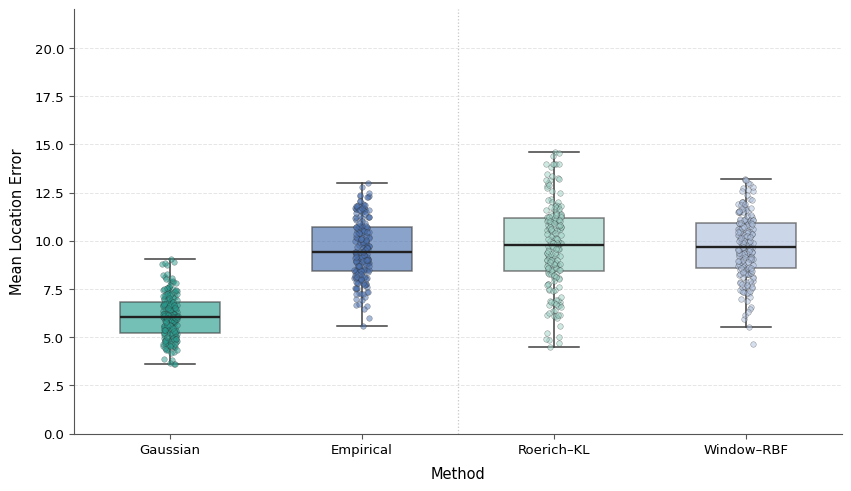

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.636859,0.900263,0.745099,6.065887
1,Empirical,0.440724,0.773684,0.560971,9.552905
2,Roerich-KL,0.499298,0.471842,0.483908,9.719585
3,Window-RBF,0.421546,0.760789,0.542163,9.712820


WINDOW SIZE: 50


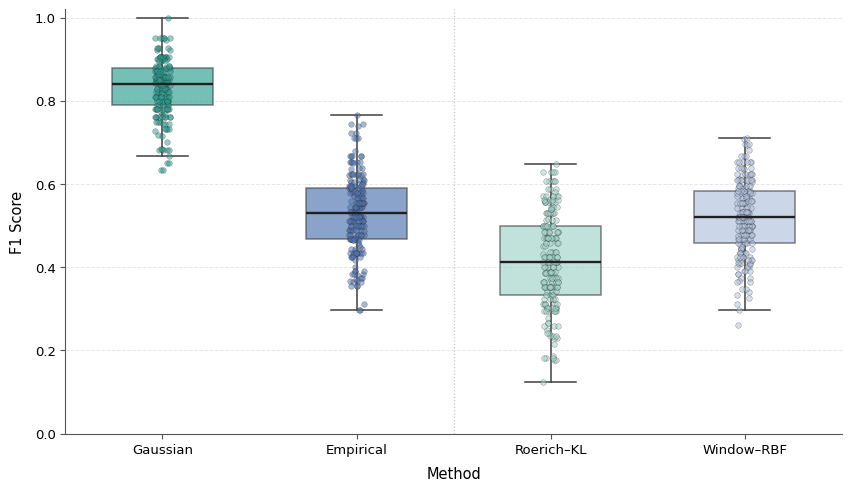

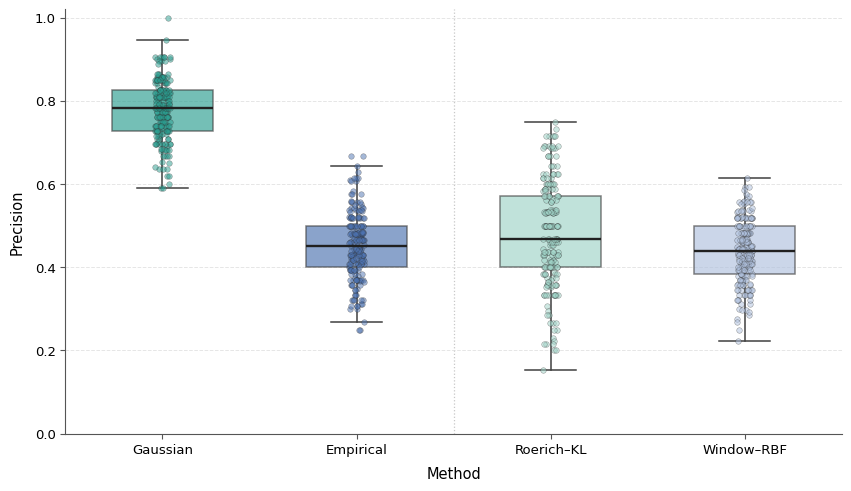

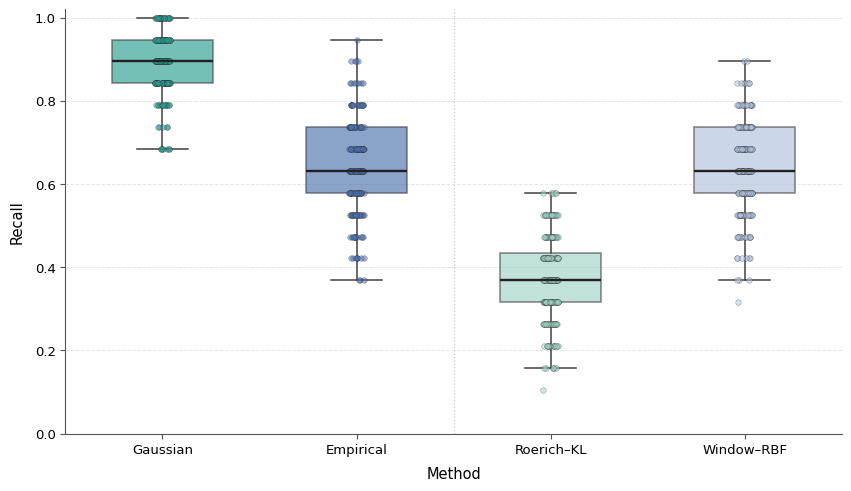

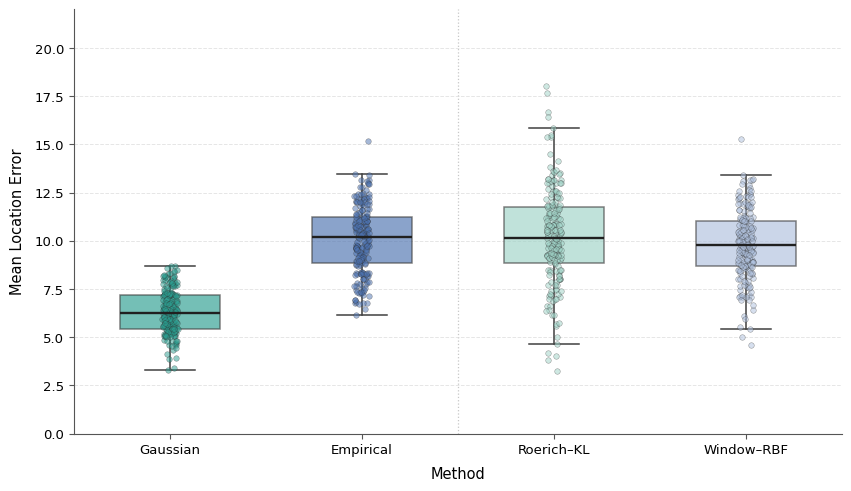

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.778205,0.890263,0.829363,6.310890
1,Empirical,0.451595,0.640263,0.528893,10.034853
2,Roerich-KL,0.479969,0.368421,0.415631,10.208170
3,Window-RBF,0.436830,0.633947,0.516827,9.798227


In [43]:
for w in [25, 30, 40, 50]:
    print("=" * 60)
    print(f"WINDOW SIZE: {w}")
    print("=" * 60)
    ruta_ar1 = f"Resultados_Series_Simuladas/AR(1)_Temporal_Dependency/Tables/ar1_metrics_window_{w}.xlsx"

    hojas = pd.read_excel(ruta_ar1, sheet_name=None)

    listas = [df.to_dict(orient="records") for df in hojas.values()]

    lista_gauss, lista_emp, lista_roerich, lista_window_rbf = listas

    nombres_boxplot = [
                        "Gaussian",
                        "Empirical",
                        "Roerich–KL",
                        "Window–RBF"
                    ]

    metrics_names = ['F1 Score', 'Precision', 'Recall', 'Mean Location Error']
    for n in metrics_names:
        ylim = (0, 1.02)
        name = n
        if n == 'Mean Location Error':
            ylim = (0, 22)
            name = 'MLE'
        path_fig = f"Resultados_Series_Simuladas/AR(1)_Temporal_Dependency/Graphics/Window {w}/{name}_AR1_TD_w{w}.png"
        fig, ax = plot_boxplots(
                                datos=[
                                    [m[n] for m in lista_gauss],
                                    [m[n] for m in lista_emp],
                                    [m[n] for m in lista_roerich],
                                    [m[n] for m in lista_window_rbf]
                                ],
                                nombres=nombres_boxplot,
                                ylabel=n,
                                xlabel="Method",
                                ylim=ylim,
                                save_path = path_fig
                            )

    ruta_avg_ar1 = f"Resultados_Series_Simuladas/AR(1)_Temporal_Dependency/Tables/ar1_metrics_avg_window_{w}.xlsx"
    average_table = generar_tabla_desde_diccionarios(
                                                        [lista_gauss, lista_emp, lista_roerich, lista_window_rbf],
                                                        ["Gauss", "Empirical", "Roerich-KL", "Window-RBF"],
                                                        ["Precision", "Recall", "F1 Score", "Mean Location Error"]
                                                        )
    display(average_table)
    average_table.to_excel(ruta_avg_ar1, index=False)

## 2.2. AR(2)

### 2.2.1. Múltiples puntos de cambio

In [86]:
def experiment_ar2_temporal_dependence(w=50, delta=20):
    metricas_ar2_gauss_fw = []
    metricas_ar2_emp_fw = []
    metricas_ar2_roerich = []
    metricas_ar2_window_rbf = []

    for i in range(200):
        print(i)
        ar2, cps_ar2, segmentos_ar2 = generar_experimento_ar2(
                    N=2000,
                    n_segmentos=20,
                    min_sep=50,
                    max_sep=150,
                    seed=1234+i
                )
        
        #Gaussiano
        cpd_ar2 = CPD(ar2, window=w, t=1, medias=True, smooth=True, temporal_comp=True)
        distancias_ar2 = cpd_ar2.distancias()
        cps_detect = detect(distancias_ar2, w)
        metricas_ar2_gauss_fw.append(metrics(cps_ar2, cps_detect, delta, 2000)[0])

        #Empírico
        cpd_ar2_emp = EmpiricalCPD(ar2, window=w, smooth=True)
        distancias_ar2_emp = cpd_ar2_emp.distancias()
        cps_detect_emp = detect(distancias_ar2_emp, w)
        metricas_ar2_emp_fw.append(metrics(cps_ar2, cps_detect_emp, delta, 2000)[0])

        #Roerich KL
        puntos_cambio = detectar_cambios_roerich(
                                        ar2,
                                        window_size=w,
                                        seed=42,
                                        periods=3
                                    )
        
        metricas_ar2_roerich.append(metrics(cps_ar2, puntos_cambio, delta, len(ar2))[0])

        #Window RBF
        puntos_cambio = detectar_window_rbf(
                                        ar2,
                                        window=w
                                    )
        
        metricas_ar2_window_rbf.append(metrics(cps_ar2, puntos_cambio, delta, len(ar2))[0])
        
    return metricas_ar2_gauss_fw, metricas_ar2_emp_fw, metricas_ar2_roerich, metricas_ar2_window_rbf

In [87]:
lists_metrics_ar2 = []
windows = [25, 30, 40, 50]
for w in windows:
    print(f'WINDOW SIZE: {w}')
    lists_metrics_ar2.append(experiment_ar2_temporal_dependence(w=w, delta=20))

WINDOW SIZE: 25
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
WINDOW SIZE: 30
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95


In [ ]:
for metricas, w in zip(lists_metrics_ar2, windows):
    exportar_excel(metricas, f"Resultados_Series_Simuladas/AR(2)_Temporal_Dependency/Tables/ar2_metrics_window_{w}.xlsx", ["Gauss", "Empirical", "Roerich-KL", "Window-RBF"])

WINDOW SIZE: 25


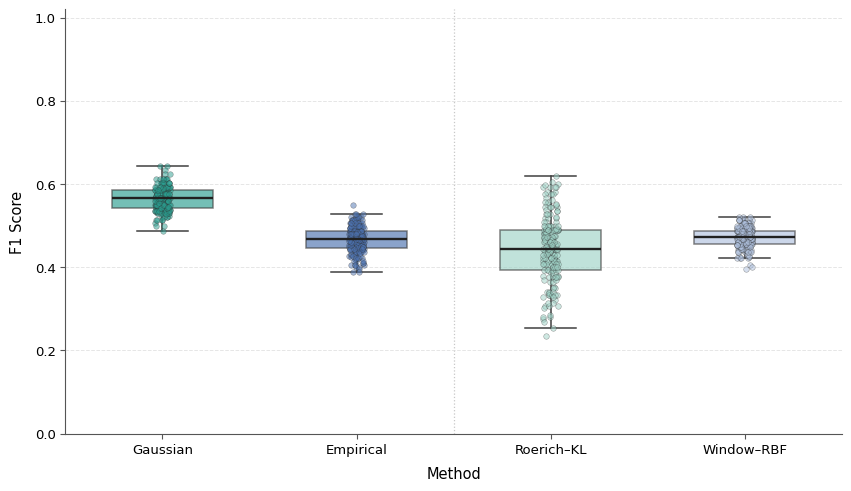

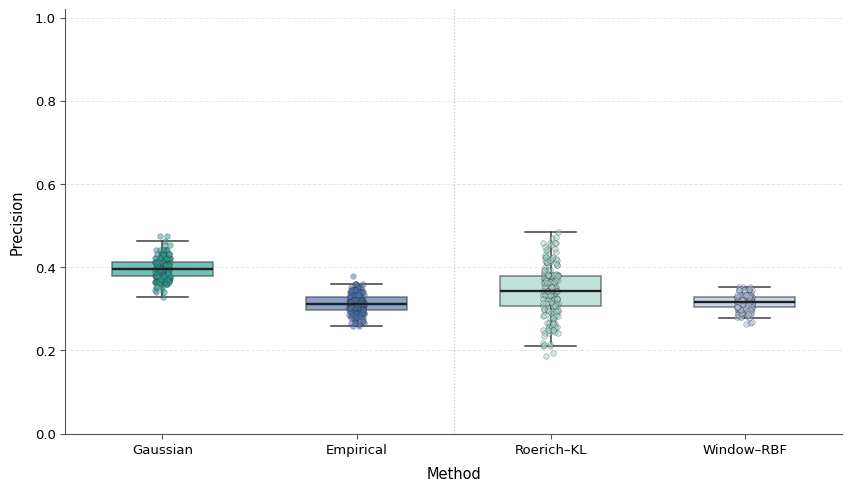

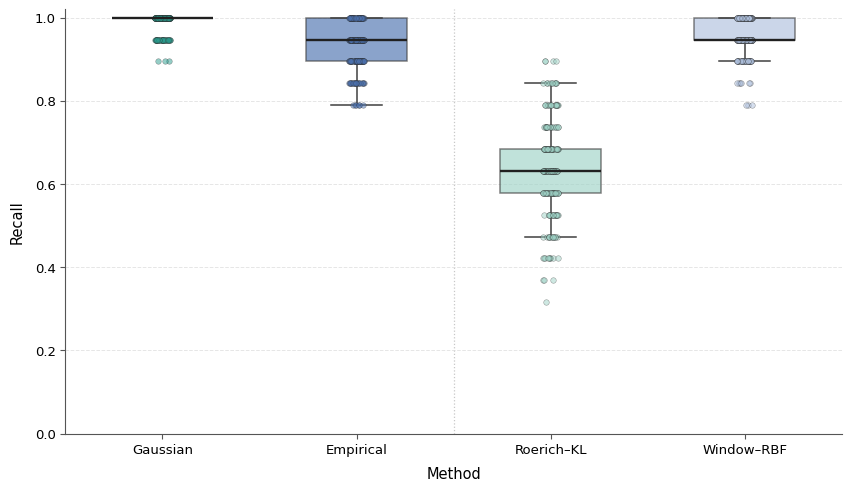

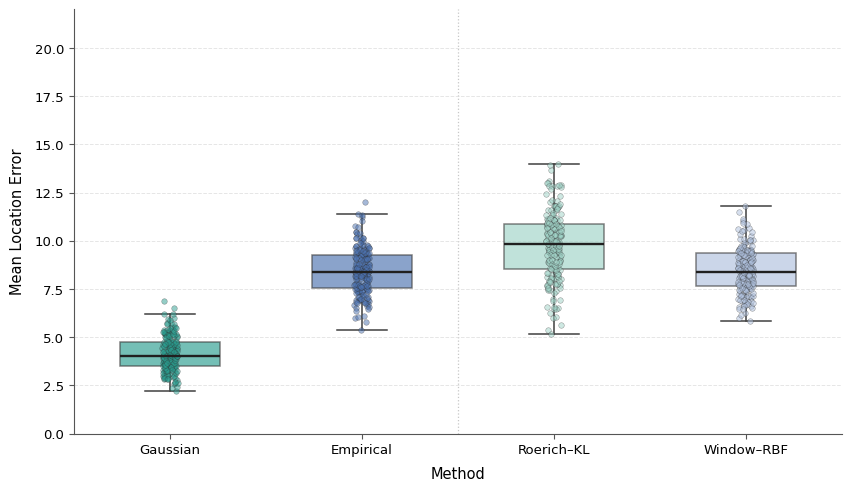

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.395411,0.988947,0.564523,4.145353
1,Empirical,0.311550,0.934211,0.467033,8.422718
2,Roerich-KL,0.341553,0.635789,0.443896,9.725414
3,Window-RBF,0.314149,0.950789,0.472137,8.462669


WINDOW SIZE: 30


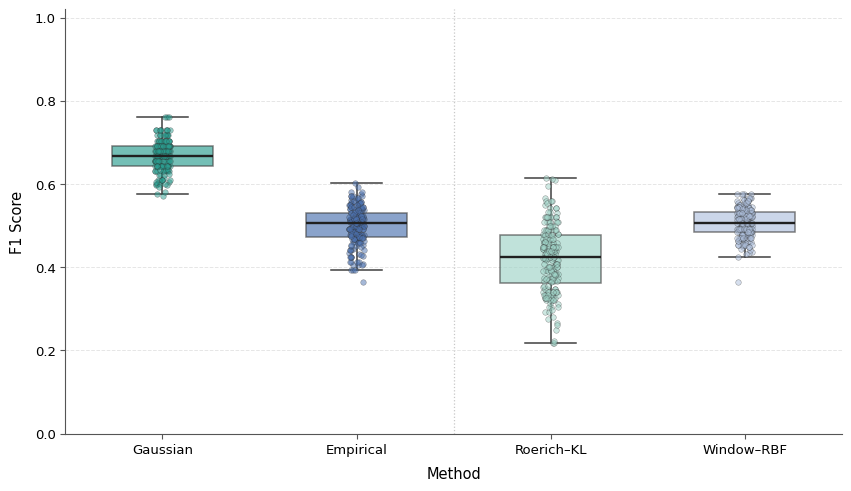

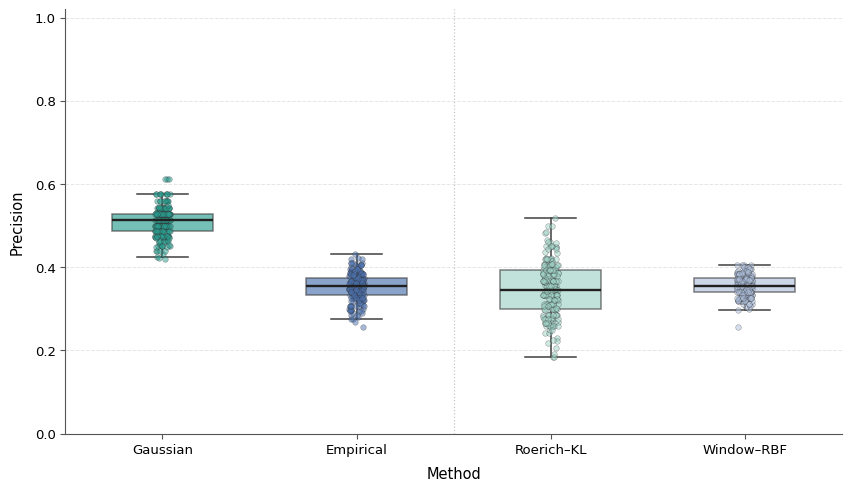

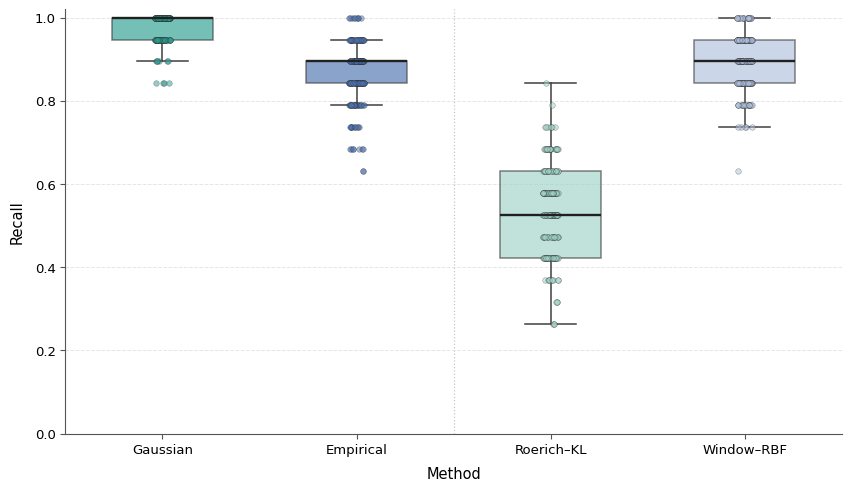

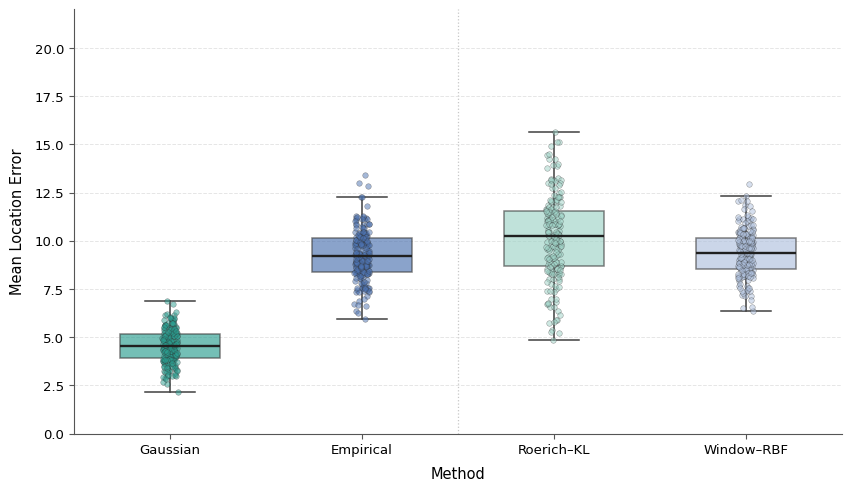

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.508253,0.980789,0.668902,4.527366
1,Empirical,0.352112,0.864211,0.500027,9.256256
2,Roerich-KL,0.346205,0.537105,0.420404,10.173458
3,Window-RBF,0.354727,0.891316,0.507318,9.381011


WINDOW SIZE: 40


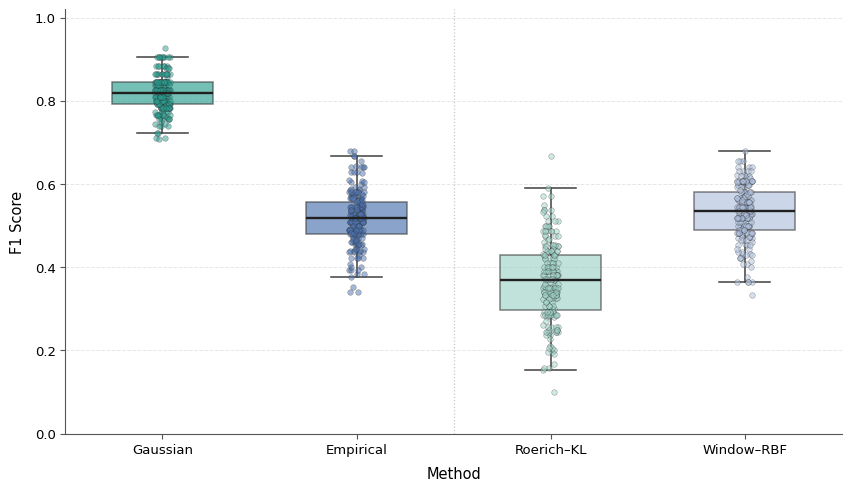

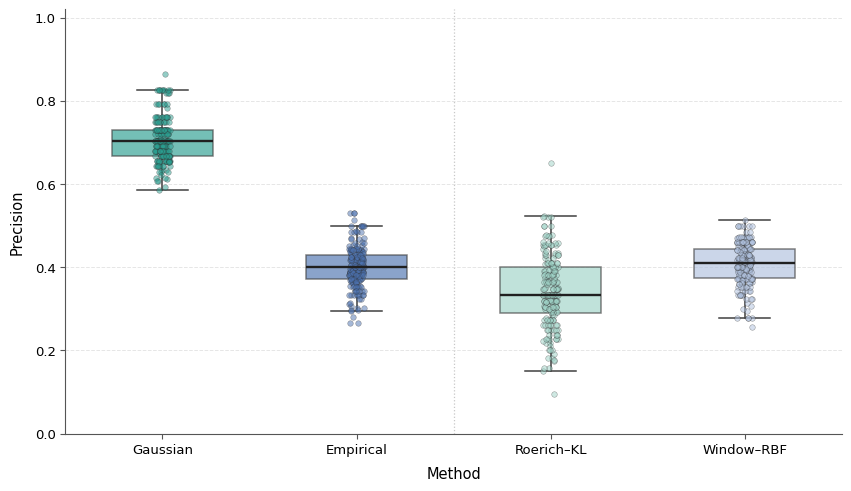

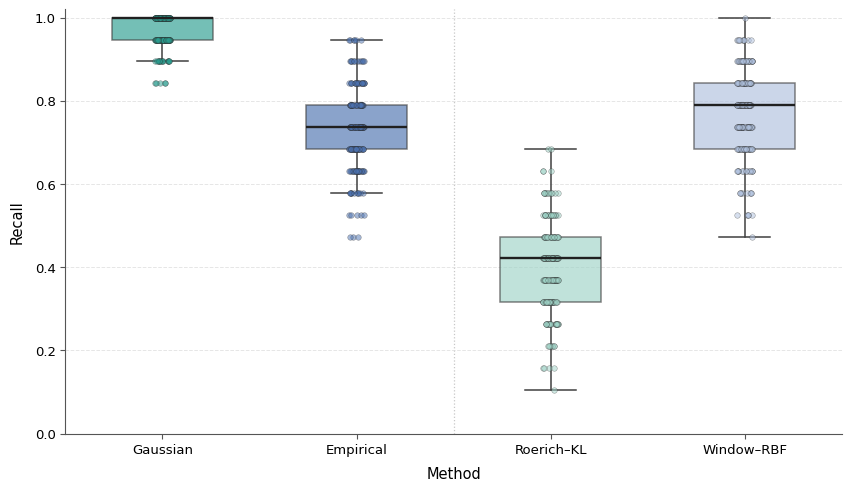

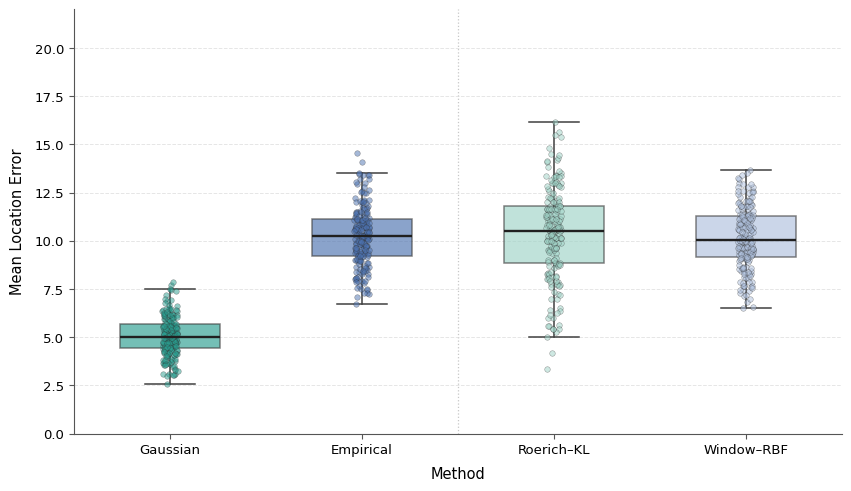

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.705463,0.971316,0.816348,5.051931
1,Empirical,0.399769,0.730000,0.516150,10.227311
2,Roerich-KL,0.341973,0.396842,0.366678,10.328993
3,Window-RBF,0.407364,0.768947,0.532324,10.122028


WINDOW SIZE: 50


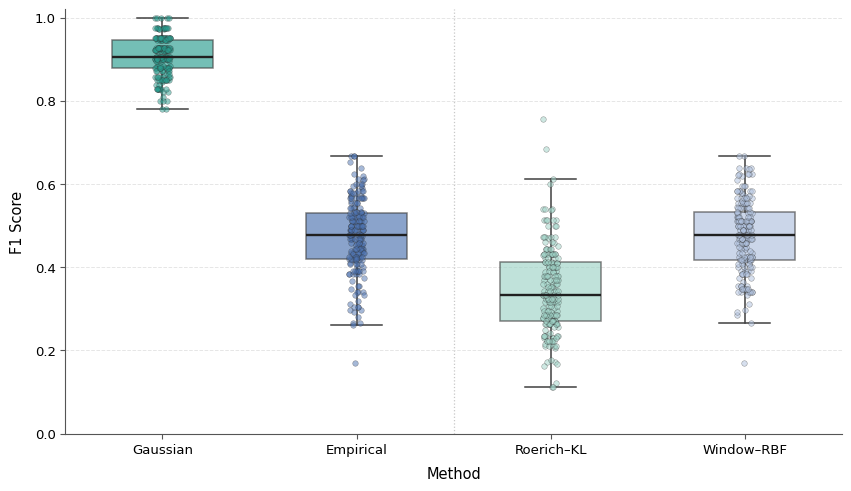

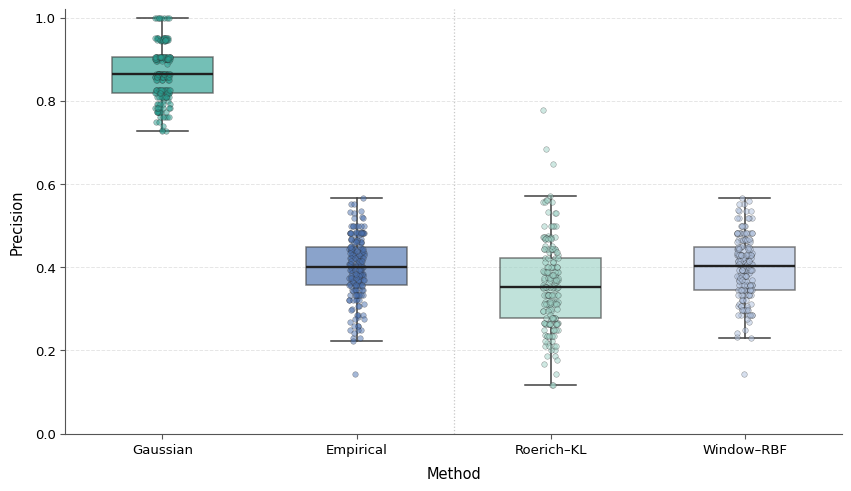

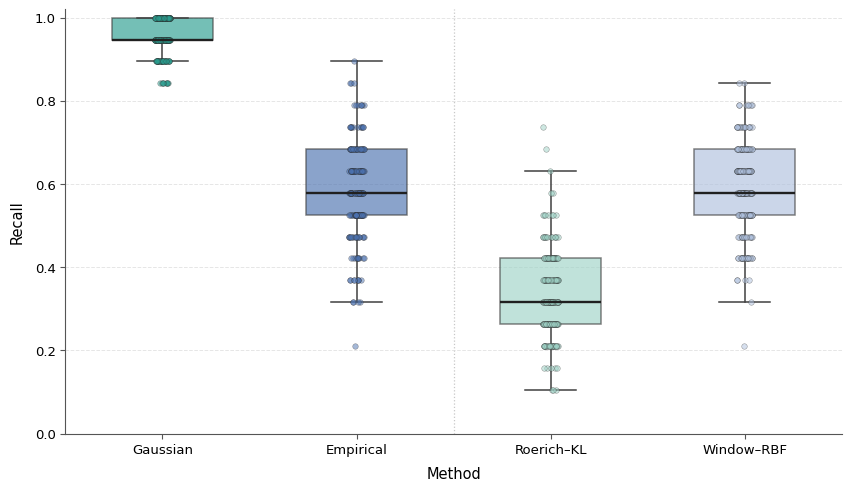

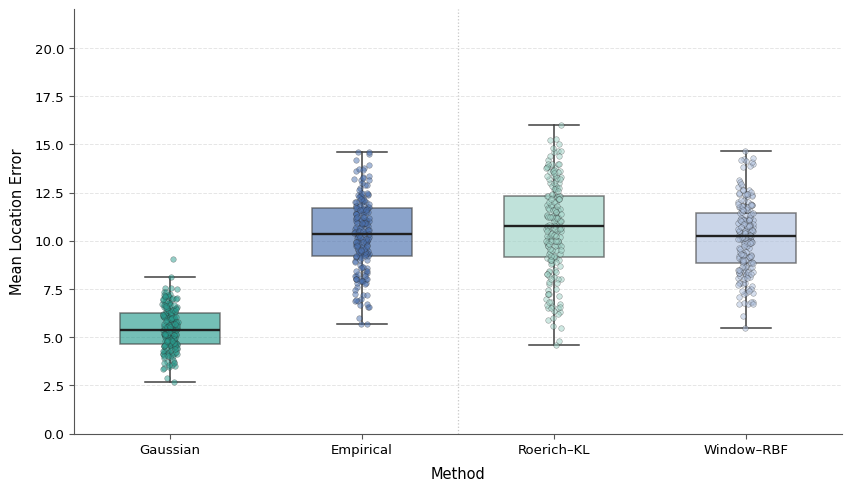

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.863768,0.956842,0.906835,5.429831
1,Empirical,0.399031,0.582632,0.473082,10.317305
2,Roerich-KL,0.356455,0.336842,0.345432,10.656683
3,Window-RBF,0.398424,0.587632,0.474572,10.179409


In [44]:
for w in [25, 30, 40, 50]:
    print("=" * 60)
    print(f"WINDOW SIZE: {w}")
    print("=" * 60)
    ruta_ar2 = f"Resultados_Series_Simuladas/AR(2)_Temporal_Dependency/Tables/ar2_metrics_window_{w}.xlsx"

    hojas = pd.read_excel(ruta_ar2, sheet_name=None)

    listas = [df.to_dict(orient="records") for df in hojas.values()]

    lista_gauss, lista_emp, lista_roerich, lista_window_rbf = listas

    nombres_boxplot = [
                        "Gaussian",
                        "Empirical",
                        "Roerich–KL",
                        "Window–RBF"
                    ]

    metrics_names = ['F1 Score', 'Precision', 'Recall', 'Mean Location Error']
    for n in metrics_names:
        ylim = (0, 1.02)
        name = n
        if n == 'Mean Location Error':
            ylim = (0, 22)
            nmae = 'MLE'
        path_fig = f"Resultados_Series_Simuladas/AR(2)_Temporal_Dependency/Graphics/Window {w}/{name}_AR2_TD_w{w}.png"
        fig, ax = plot_boxplots(
                                datos=[
                                    [m[n] for m in lista_gauss],
                                    [m[n] for m in lista_emp],
                                    [m[n] for m in lista_roerich],
                                    [m[n] for m in lista_window_rbf]
                                ],
                                nombres=nombres_boxplot,
                                ylabel=n,
                                xlabel="Method",
                                ylim=ylim,
                                save_path = path_fig
                            )
    ruta_avg_ar2 = f"Resultados_Series_Simuladas/AR(2)_Temporal_Dependency/Tables/ar2_metrics_avg_window_{w}.xlsx"
    average_table = generar_tabla_desde_diccionarios(
                                                        [lista_gauss, lista_emp, lista_roerich, lista_window_rbf],
                                                        ["Gauss", "Empirical", "Roerich-KL", "Window-RBF"],
                                                        ["Precision", "Recall", "F1 Score", "Mean Location Error"]
                                                        )
    display(average_table)
    average_table.to_excel(ruta_avg_ar2, index=False)

## 2.3. Senoidal

In [90]:
def experiment_sen_temporal_dependence(w=50, delta=20):
    metricas_sen_gauss_fw = []
    metricas_sen_emp_fw = []
    metricas_sen_roerich = []
    metricas_sen_window_rbf = []

    for i in range(200):
        print(i)
        sen, cps_sen, segmentos_sen = generar_experimento_senoidal(
                    N=2000,
                    n_segmentos=20,
                    min_sep=50,
                    max_sep=150,
                    seed=1234+i
                )
        
        #Gaussiano
        cpd_sen = CPD(sen, window=w, t=1, medias=True, smooth=True, temporal_comp=True)
        distancias_sen = cpd_sen.distancias()
        cps_detect = detect(distancias_sen, w)
        metricas_sen_gauss_fw.append(metrics(cps_sen, cps_detect, delta, 2000)[0])

        #Empírico
        cpd_sen_emp = EmpiricalCPD(sen, window=w, smooth=True)
        distancias_sen_emp = cpd_sen_emp.distancias()
        cps_detect_emp = detect(distancias_sen_emp, w)
        metricas_sen_emp_fw.append(metrics(cps_sen, cps_detect_emp, delta, 2000)[0])

        #Roerich KL
        puntos_cambio = detectar_cambios_roerich(
                                        sen,
                                        window_size=w,
                                        seed=42,
                                        periods=3
                                    )
        
        metricas_sen_roerich.append(metrics(cps_sen, puntos_cambio, delta, len(sen))[0])

        #Window RBF
        puntos_cambio = detectar_window_rbf(
                                        sen,
                                        window=w
                                    )
        
        metricas_sen_window_rbf.append(metrics(cps_sen, puntos_cambio, delta, len(sen))[0])
        
    return metricas_sen_gauss_fw, metricas_sen_emp_fw, metricas_sen_roerich, metricas_sen_window_rbf

In [91]:
lists_metrics_sen = []
windows = [25, 30, 40, 50]
for w in windows:
    print(f'WINDOW SIZE: {w}')
    lists_metrics_sen.append(experiment_sen_temporal_dependence(w=w, delta=20))

WINDOW SIZE: 25
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
WINDOW SIZE: 30
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95


In [ ]:
for metricas, w in zip(lists_metrics_sen, windows):
    exportar_excel(metricas, f"Resultados_Series_Simuladas/Sen_Temporal_Dependency/Tables/sen_metrics_window_{w}.xlsx", ["Gauss", "Empirical", "Roerich-KL", "Window-RBF"])

WINDOW SIZE: 25


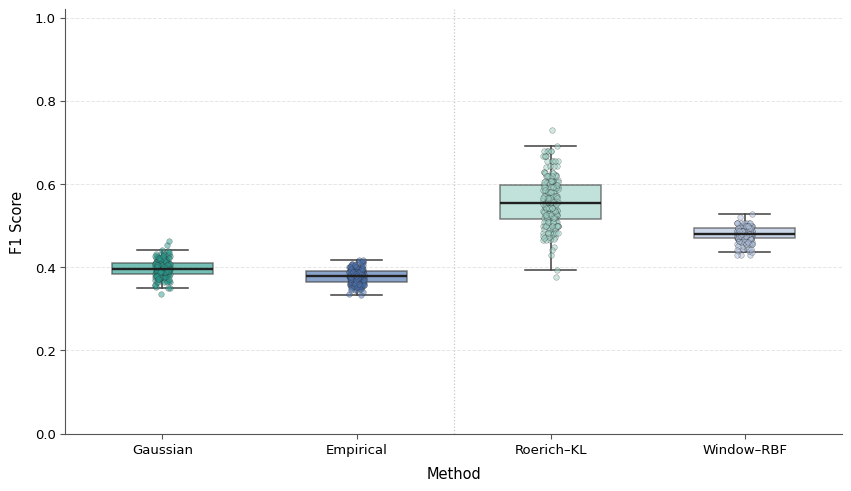

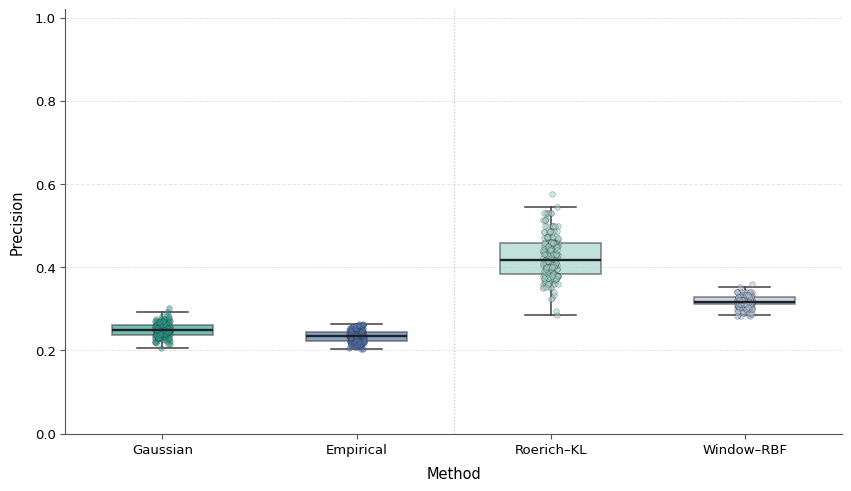

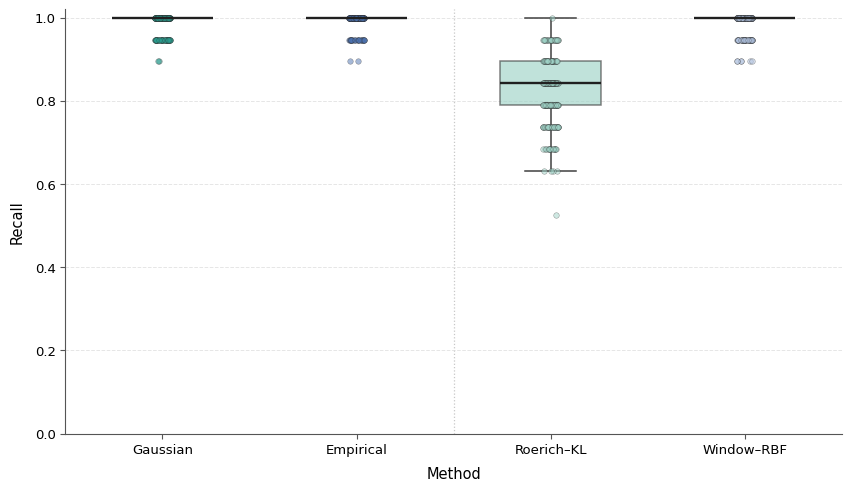

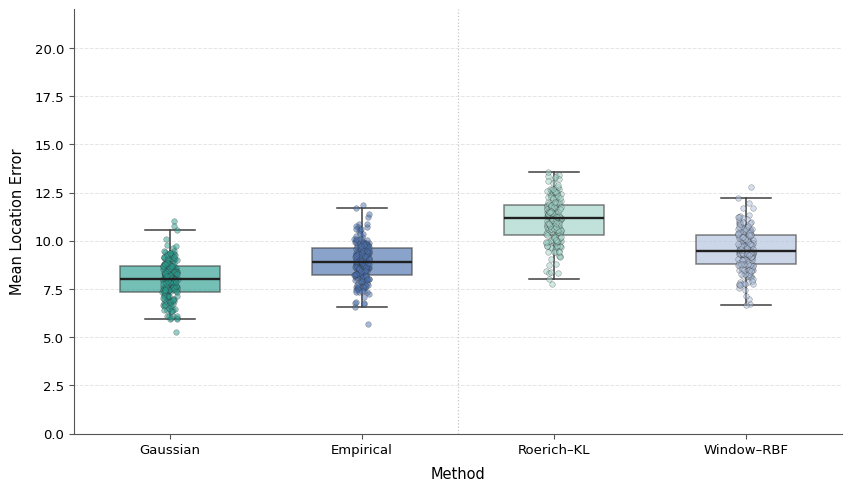

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.249122,0.987895,0.397676,7.969842
1,Empirical,0.233863,0.992895,0.378384,8.891945
2,Roerich-KL,0.423559,0.819474,0.557873,11.064550
3,Window-RBF,0.316682,0.986053,0.479300,9.507603


WINDOW SIZE: 30


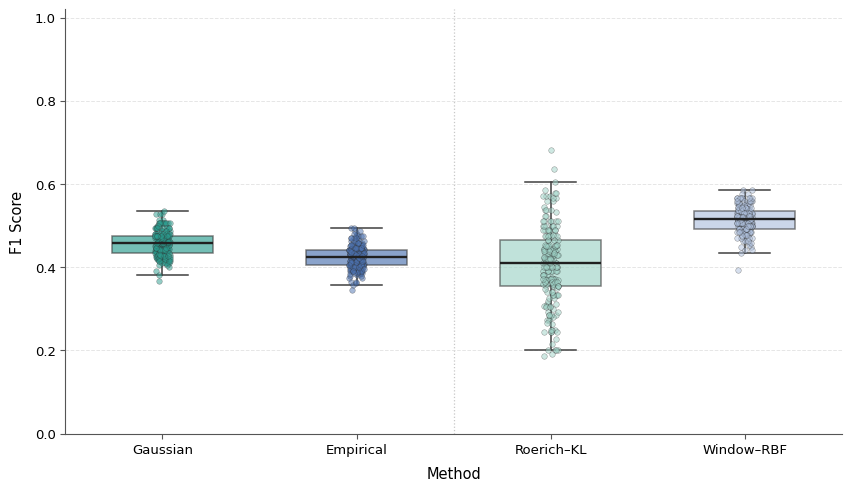

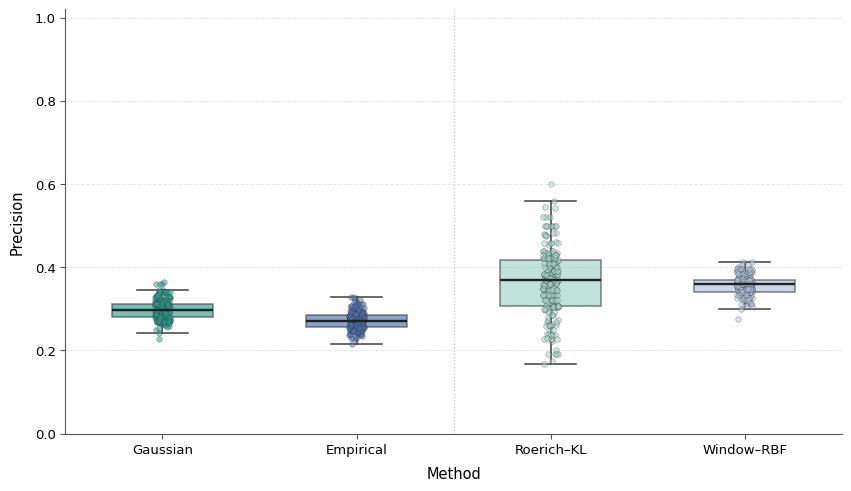

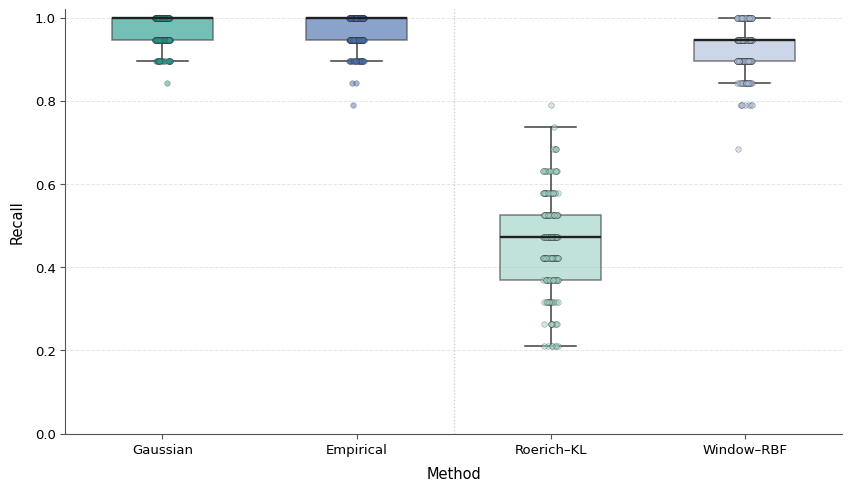

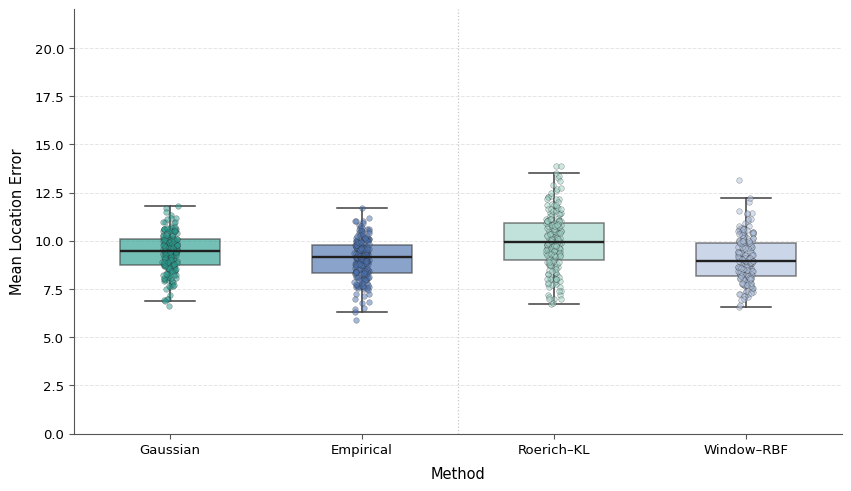

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.298412,0.970263,0.455987,9.394058
1,Empirical,0.271443,0.966316,0.423513,9.059931
2,Roerich-KL,0.364424,0.459211,0.405346,9.986490
3,Window-RBF,0.357321,0.923947,0.515181,9.058121


WINDOW SIZE: 40


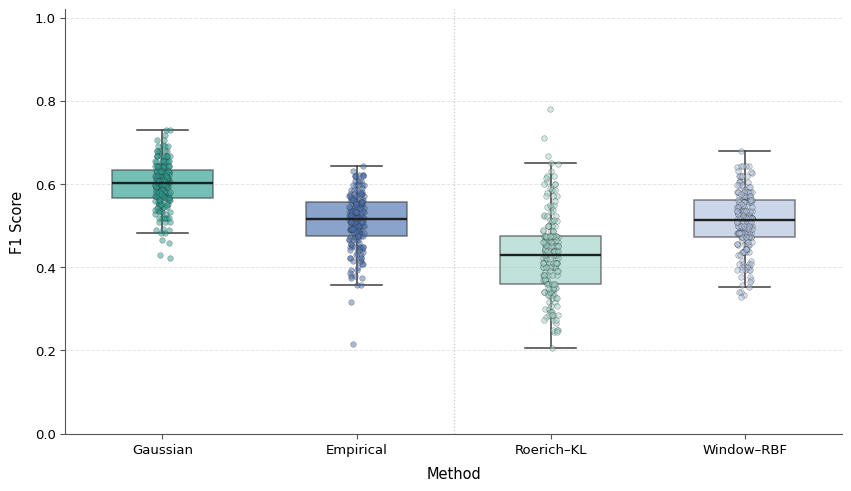

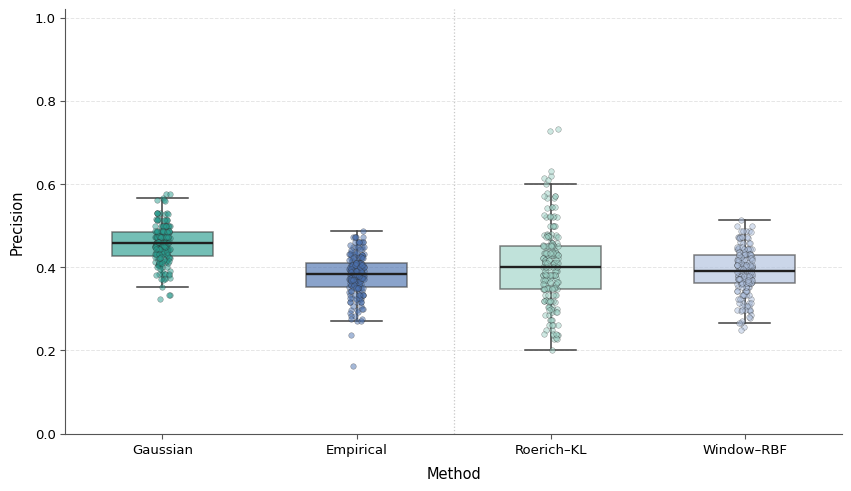

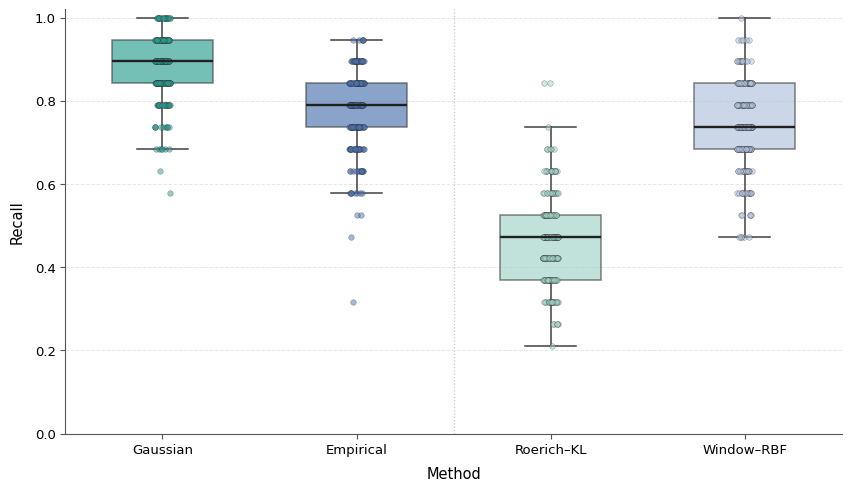

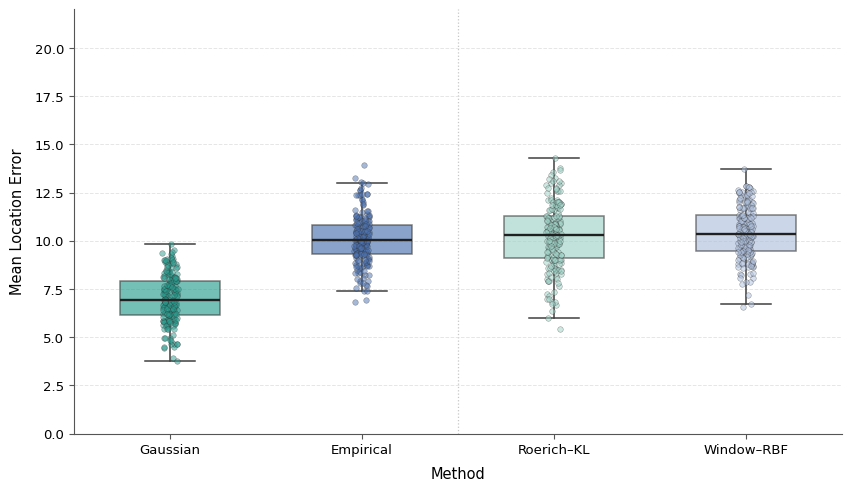

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.456013,0.874737,0.598739,6.999920
1,Empirical,0.381460,0.772368,0.510313,10.073668
2,Roerich-KL,0.402188,0.464211,0.429995,10.245420
3,Window-RBF,0.388805,0.736842,0.508827,10.405876


WINDOW SIZE: 50


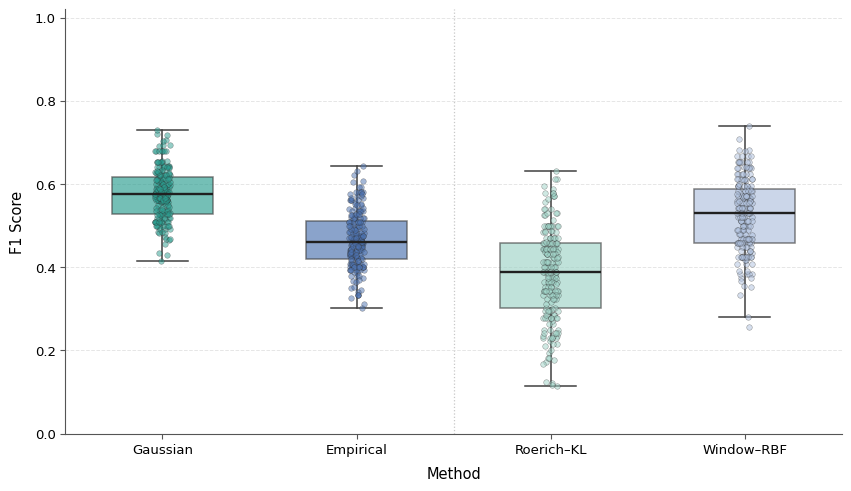

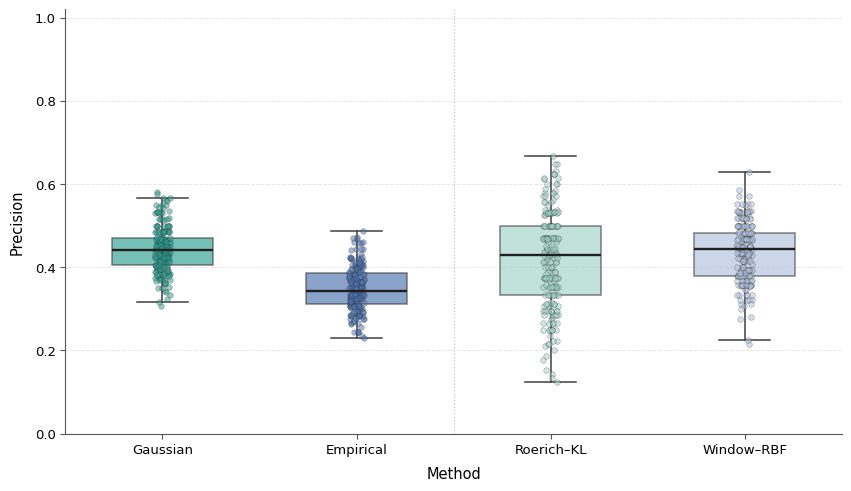

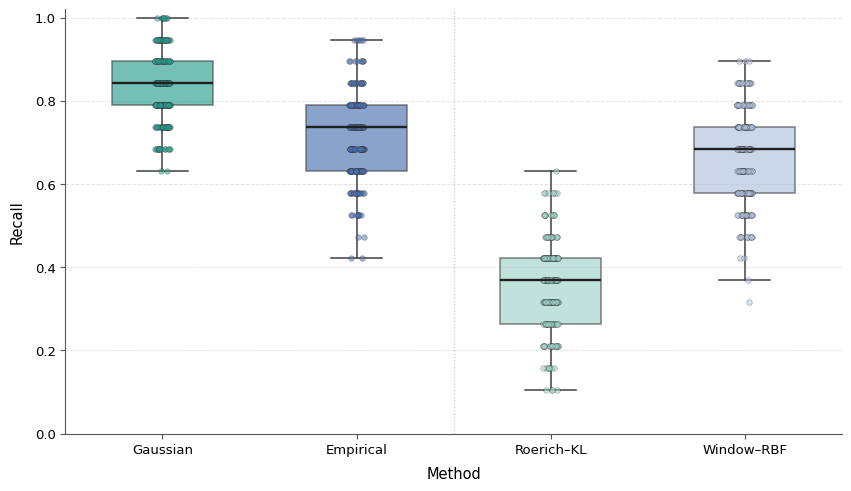

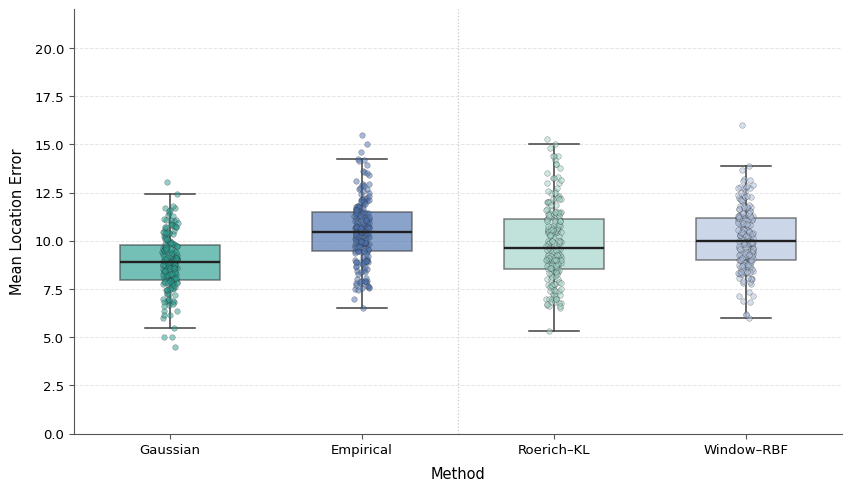

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.442247,0.832105,0.576134,8.885027
1,Empirical,0.348574,0.709474,0.466482,10.462453
2,Roerich-KL,0.417826,0.355526,0.382937,9.881035
3,Window-RBF,0.435389,0.664737,0.525897,10.109337


In [45]:
for w in [25, 30, 40, 50]:
    print("=" * 60)
    print(f"WINDOW SIZE: {w}")
    print("=" * 60)
    ruta_sen = f"Resultados_Series_Simuladas/Sen_Temporal_Dependency/Tables/sen_metrics_window_{w}.xlsx"

    hojas = pd.read_excel(ruta_sen, sheet_name=None)

    listas = [df.to_dict(orient="records") for df in hojas.values()]

    lista_gauss, lista_emp, lista_roerich, lista_window_rbf = listas

    nombres_boxplot = [
                        "Gaussian",
                        "Empirical",
                        "Roerich–KL",
                        "Window–RBF"
                    ]

    metrics_names = ['F1 Score', 'Precision', 'Recall', 'Mean Location Error']
    for n in metrics_names:
        ylim = (0, 1.02)
        name = n
        if n == 'Mean Location Error':
            ylim = (0, 22)
            name = 'MLE'
        path_fig = f"Resultados_Series_Simuladas/Sen_Temporal_Dependency/Graphics/Window {w}/{name}_Sen_w{w}.png"
        fig, ax = plot_boxplots(
                                datos=[
                                    [m[n] for m in lista_gauss],
                                    [m[n] for m in lista_emp],
                                    [m[n] for m in lista_roerich],
                                    [m[n] for m in lista_window_rbf]
                                ],
                                nombres=nombres_boxplot,
                                ylabel=n,
                                xlabel="Method",
                                ylim=ylim,
                                save_path = path_fig
                            )

    ruta_avg_sen = f"Resultados_Series_Simuladas/Sen_Temporal_Dependency/Tables/sen_metrics_avg_window_{w}.xlsx"
    average_table = generar_tabla_desde_diccionarios(
                                                        [lista_gauss, lista_emp, lista_roerich, lista_window_rbf],
                                                        ["Gauss", "Empirical", "Roerich-KL", "Window-RBF"],
                                                        ["Precision", "Recall", "F1 Score", "Mean Location Error"]
                                                        )
    display(average_table)
    average_table.to_excel(ruta_avg_sen, index=False)

## 2.4. AR(2) CON MEDIA Y DISPERSIÓN FLUCTUANTES

### 2.4.1. Simulaciones

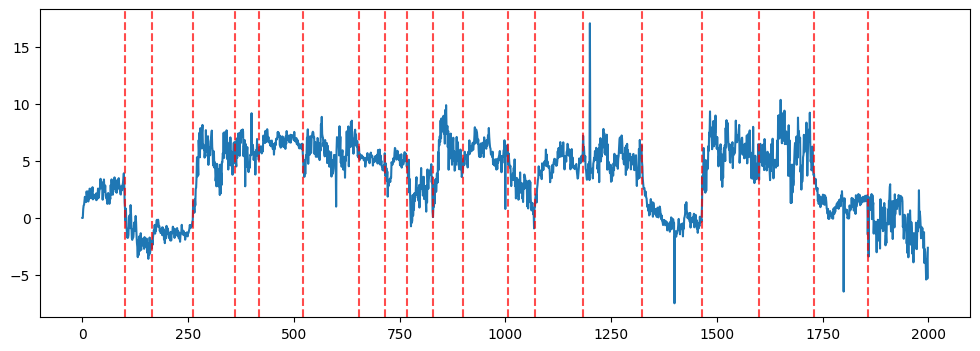

In [7]:
ar2_mdf, cps_ar2_mdf, outliers_ar2_mdf = ar2_noise(
            T = 2000,
            n_segmentos = 20,
            min_mean_diff = 0.05,
            min_seg = 50,
            max_seg = 150,
            base_mean = 0.3,
            std_range = (0.3, 1.2)
        )

plt.figure(figsize=(12, 4))
plt.plot(ar2_mdf)
for i in cps_ar2_mdf:
    plt.axvline(i, color='red', linestyle='--', alpha=0.7)

plt.show()


0

════════════════════════════════════════════════════════════════════════
                         Optimización Gaussiano                         
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 9.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 9.0000

Dispersion of Cost
──────────────────
    Execution Time              : 18.6303 s
    Best Window                 : 142

Dispersion of Cost
──────────────────
    Execution Time              : 18.6303 s
    Best Window                 : 142

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 142

Selección final
───

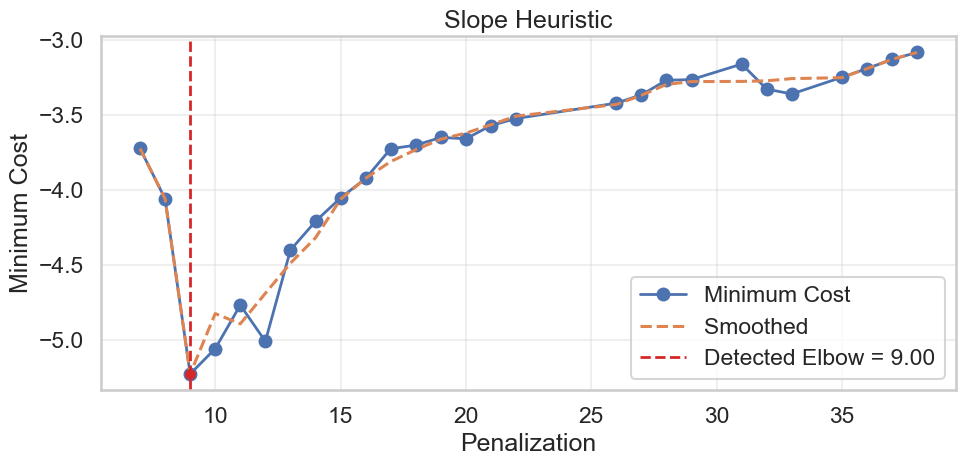

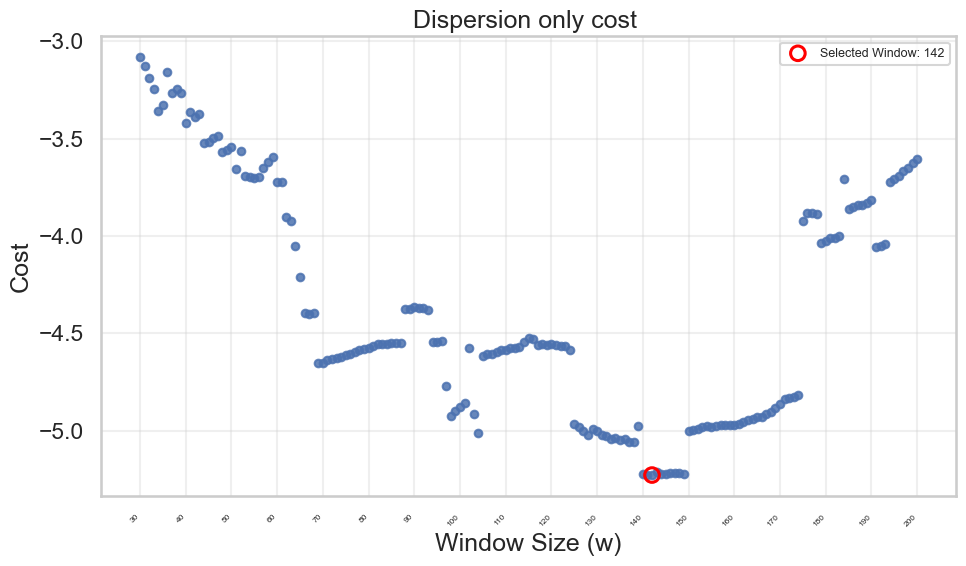

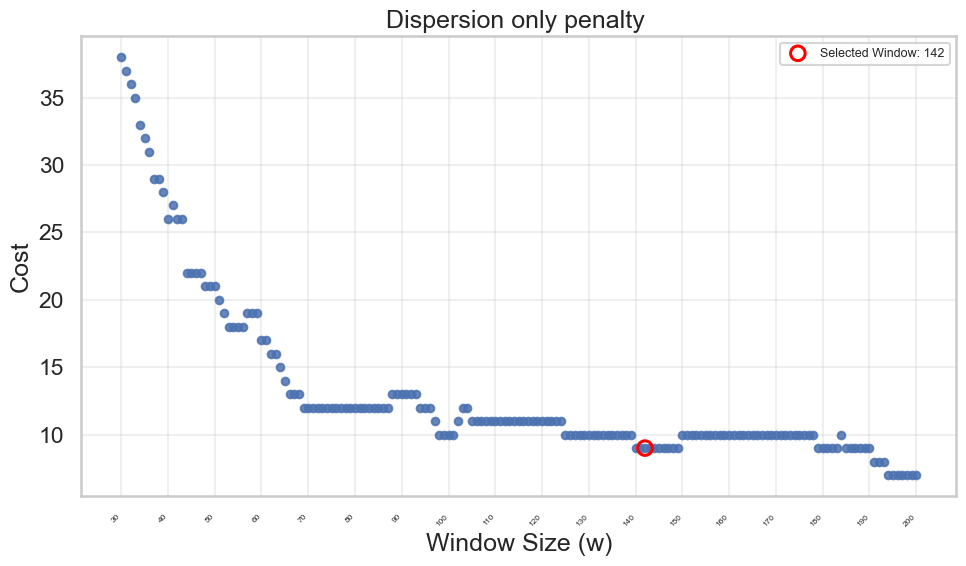

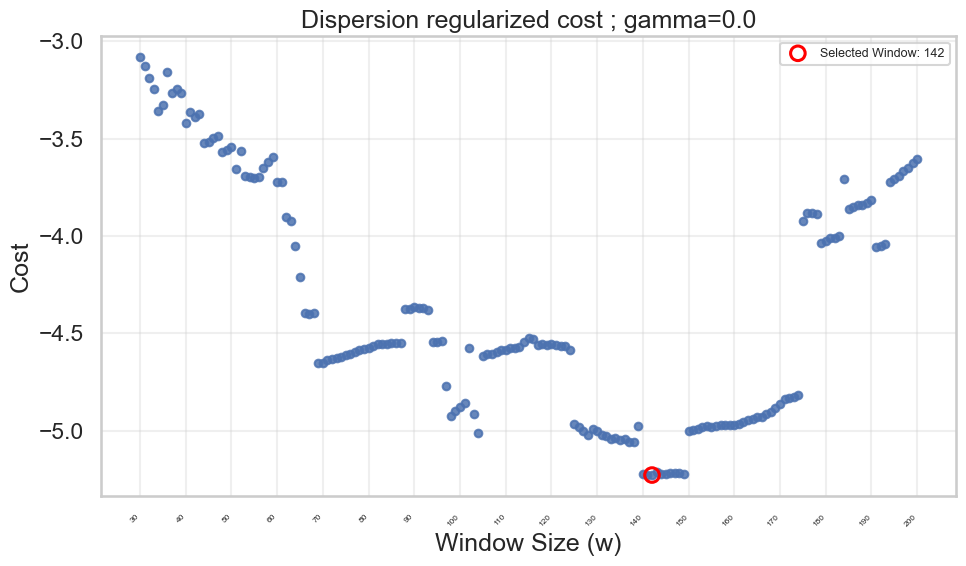

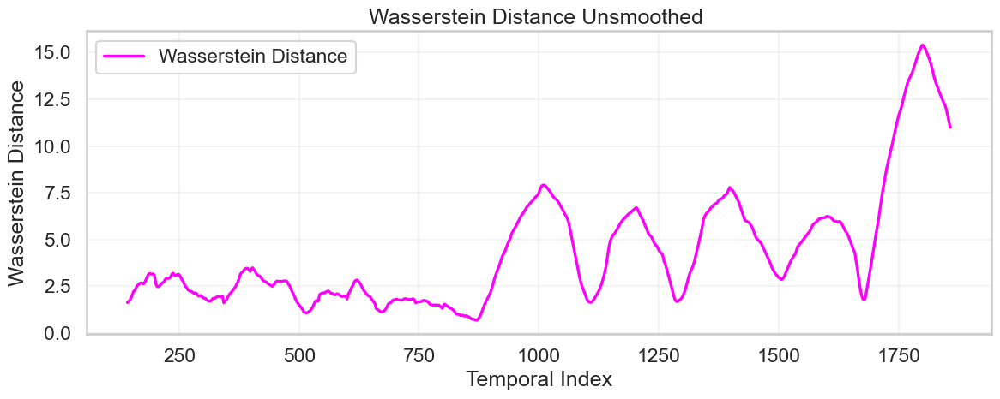

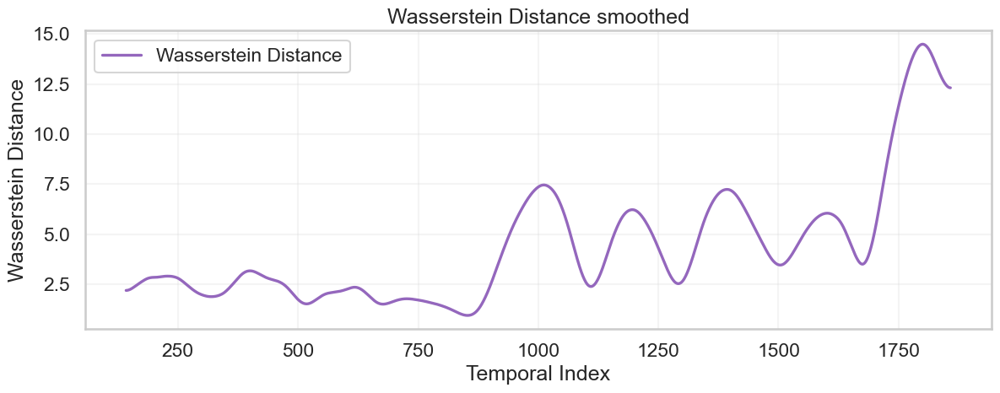

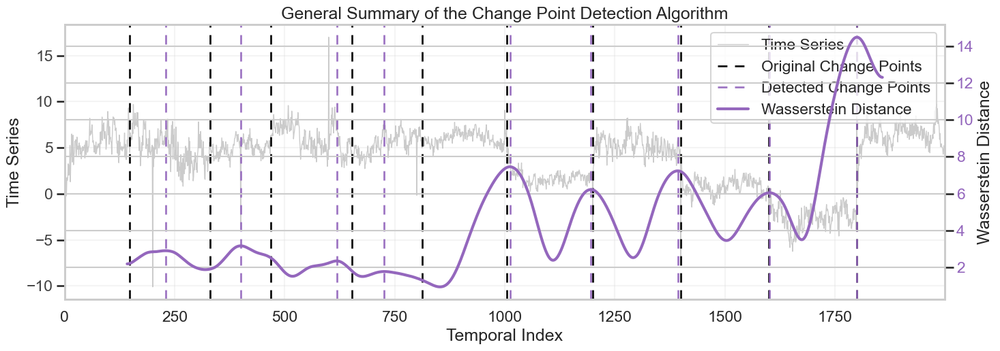


════════════════════════════════════════════════════════════════════════
                         Optimización Empírico                          
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 9.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 9.0000

Dispersion of Cost
──────────────────
    Execution Time              : 13.0171 s
    Best Window                 : 128

Dispersion of Cost
──────────────────
    Execution Time              : 13.0171 s
    Best Window                 : 128

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 128

Selección final
─────

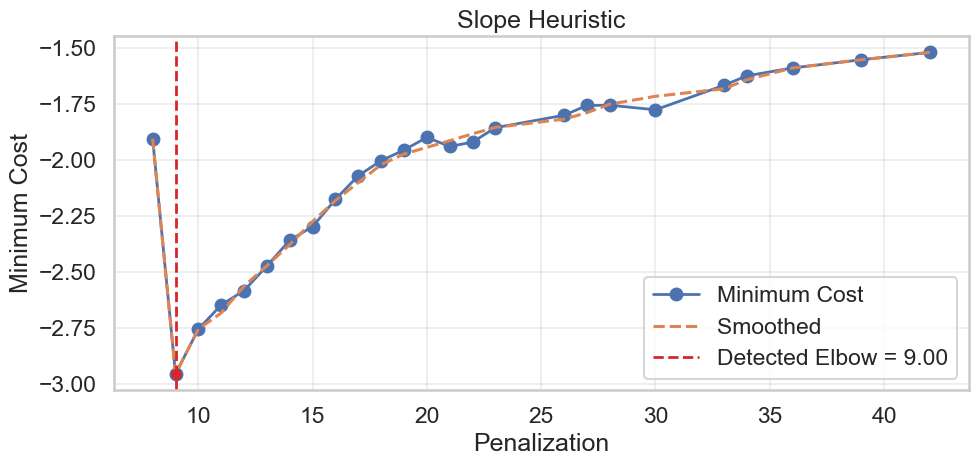

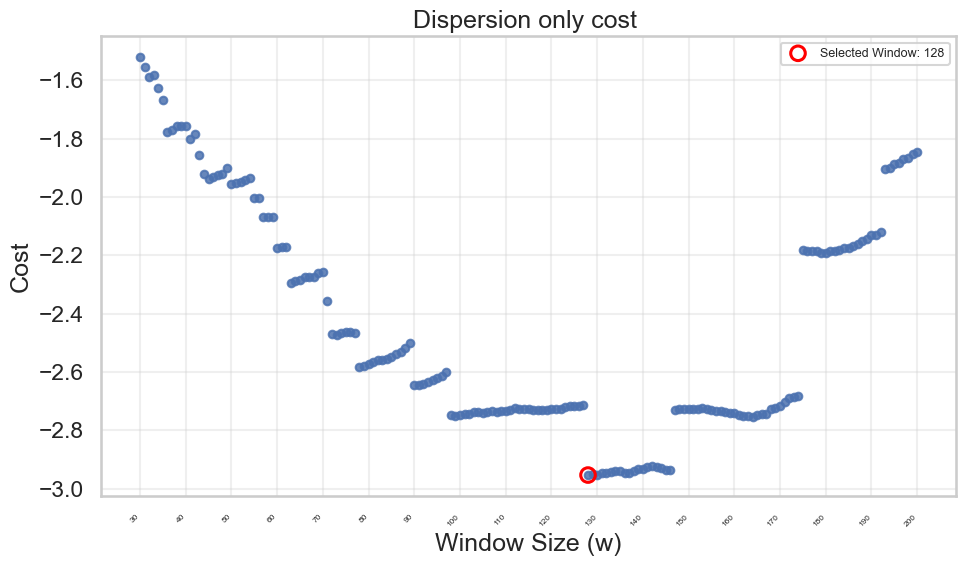

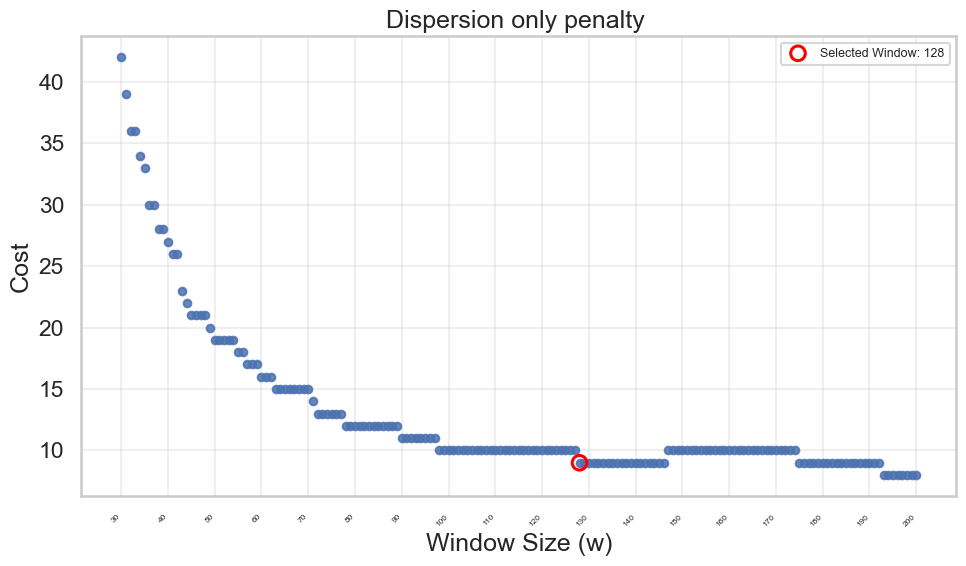

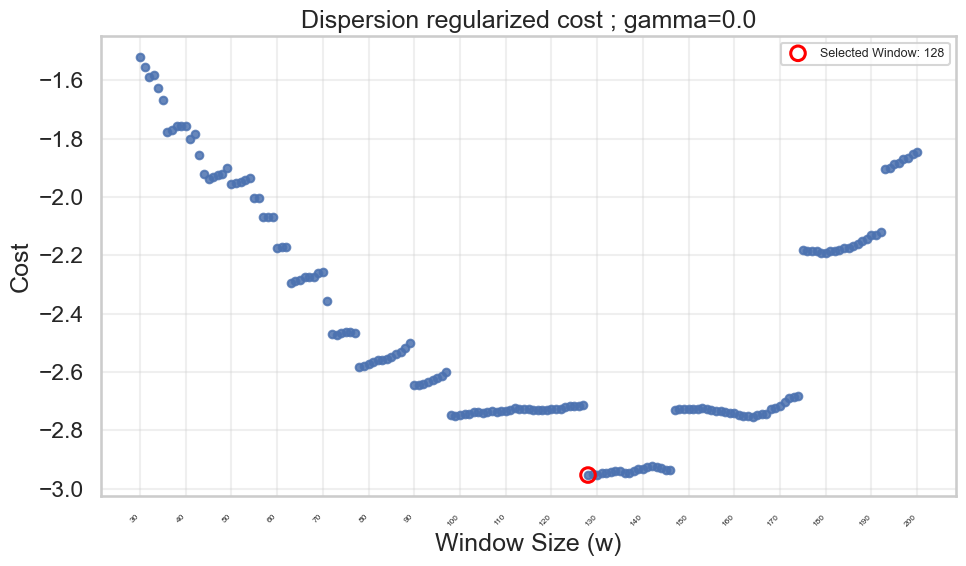

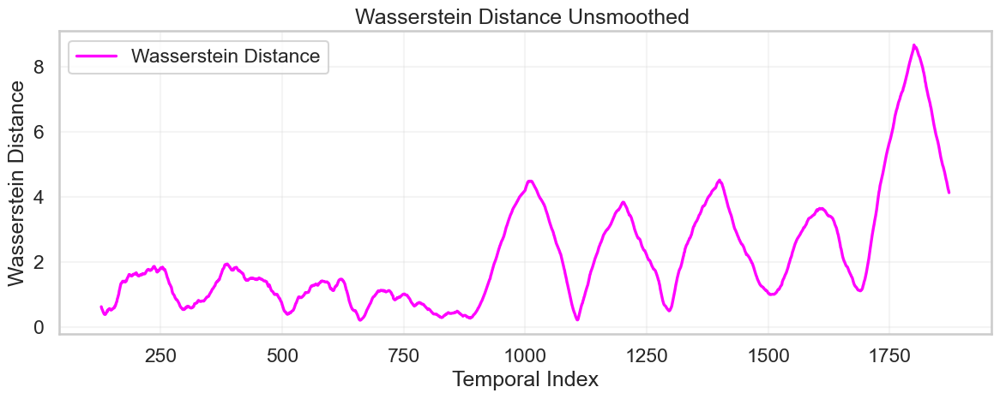

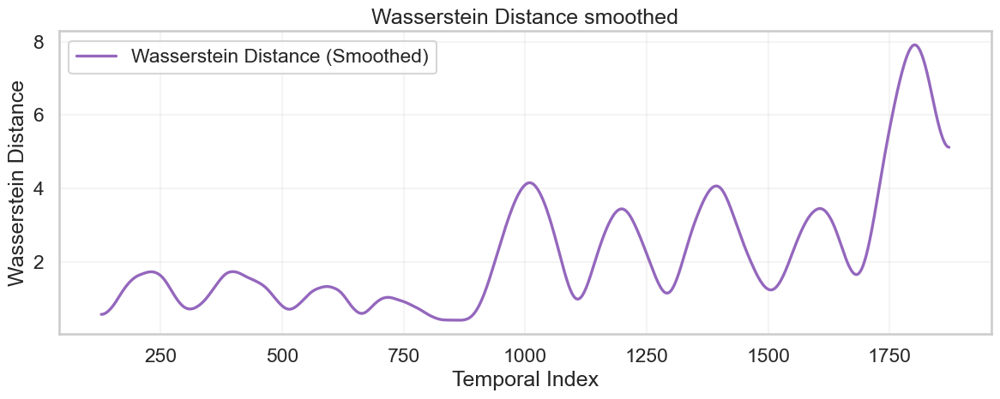

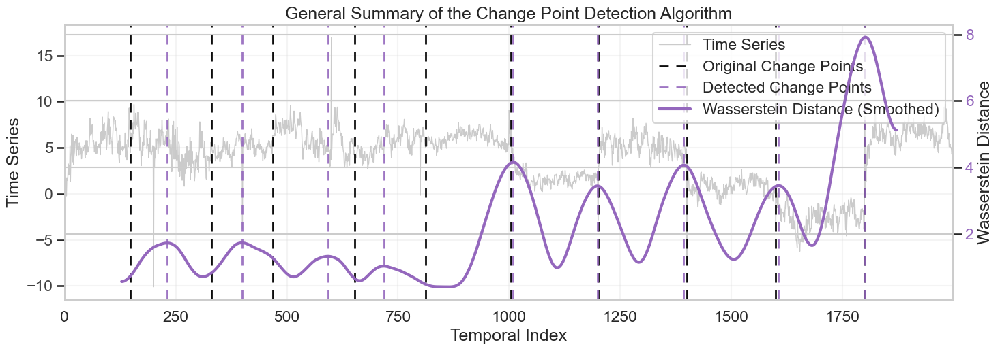

1

════════════════════════════════════════════════════════════════════════
                         Optimización Gaussiano                         
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 8.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 8.0000

Dispersion of Cost
──────────────────
    Execution Time              : 18.5506 s
    Best Window                 : 151

Dispersion of Cost
──────────────────
    Execution Time              : 18.5506 s
    Best Window                 : 151

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 151

Selección final
───

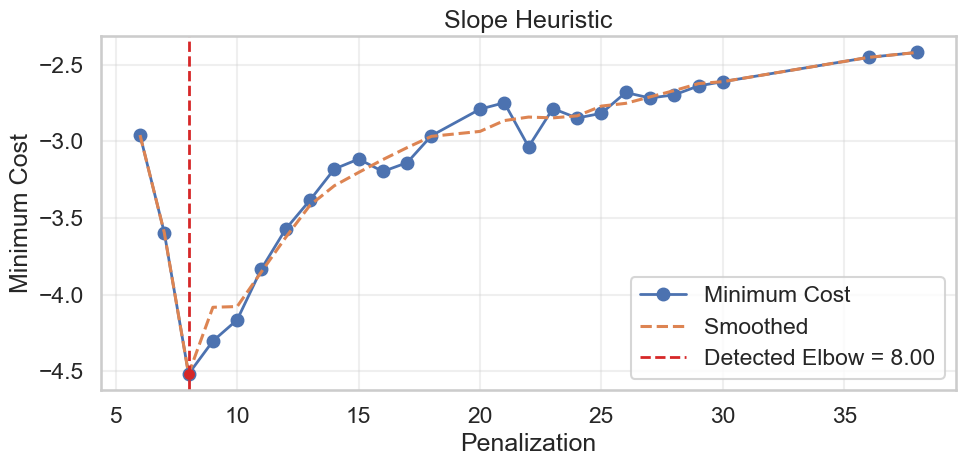

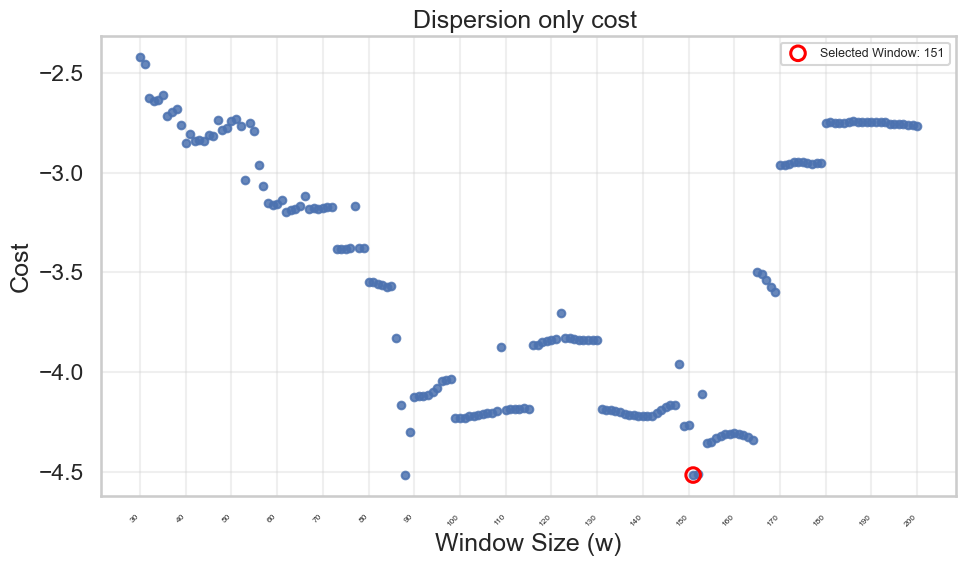

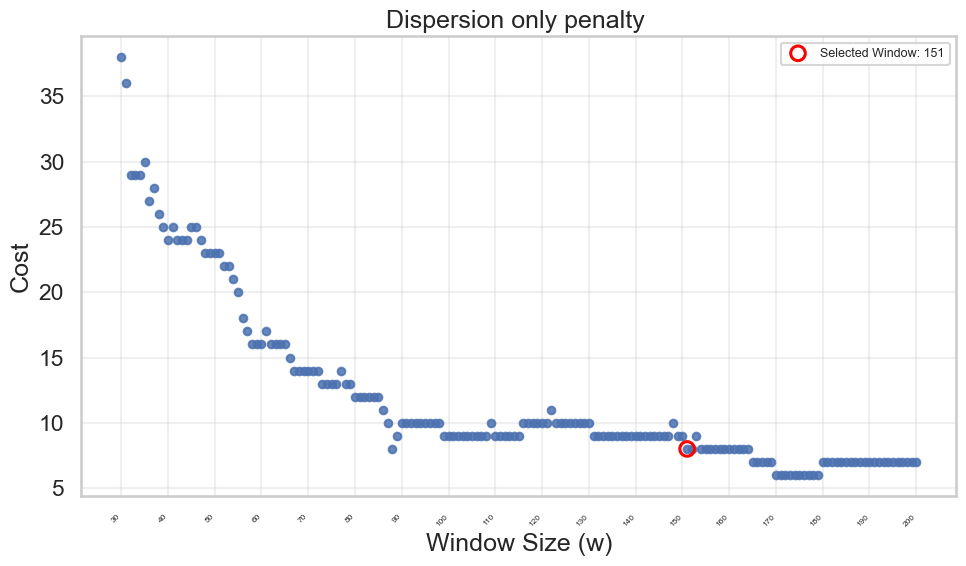

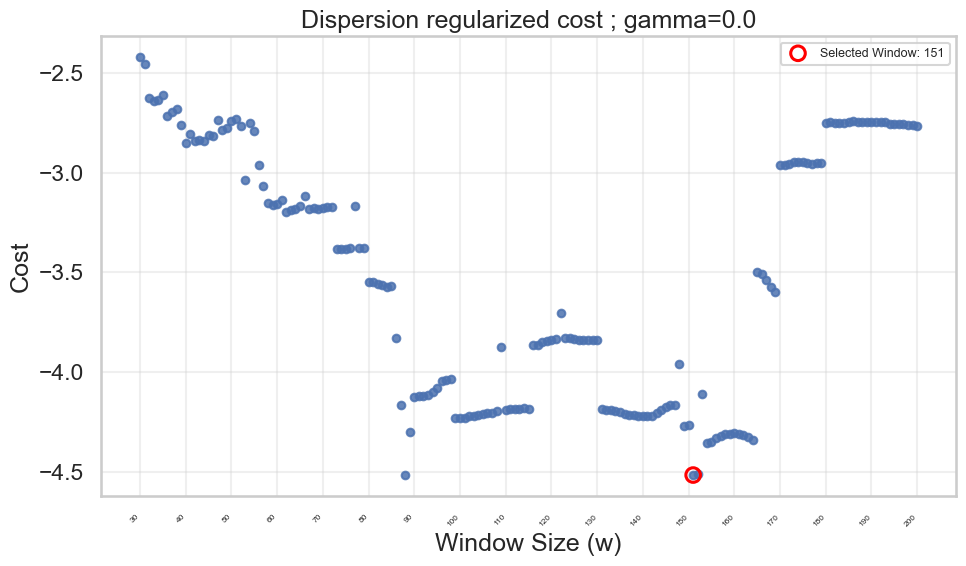

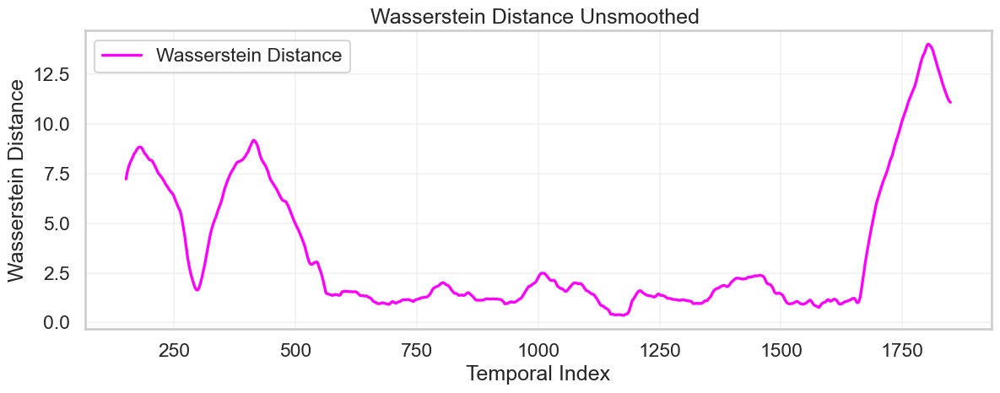

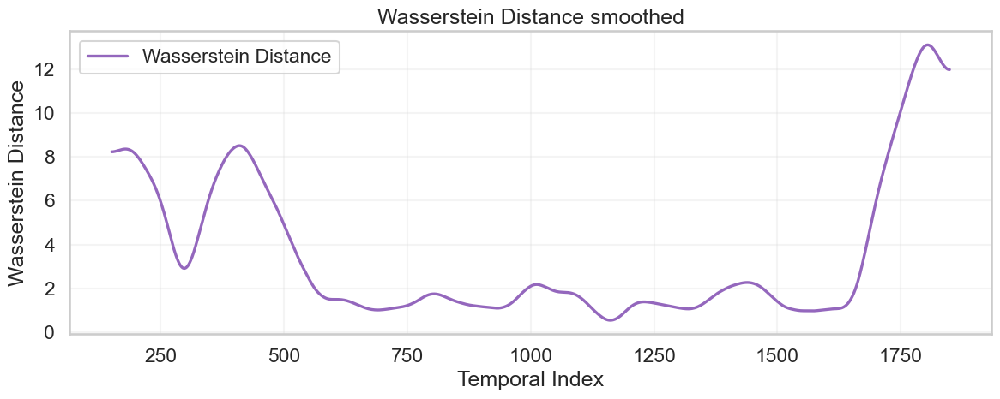

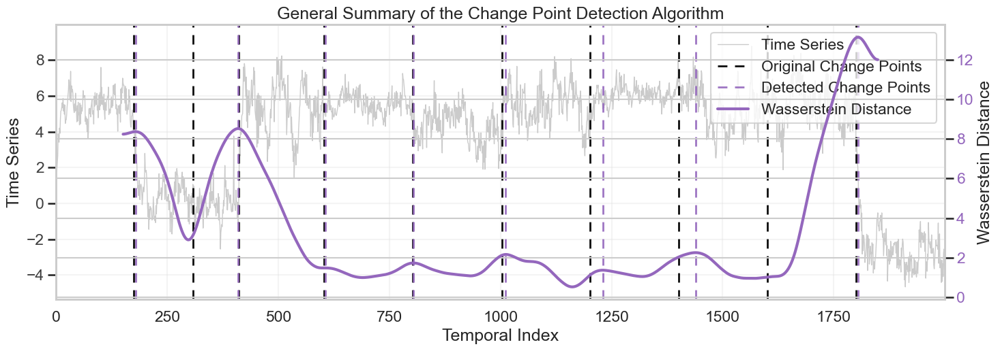


════════════════════════════════════════════════════════════════════════
                         Optimización Empírico                          
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 8.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 8.0000

Dispersion of Cost
──────────────────
    Execution Time              : 13.4583 s
    Best Window                 : 140

Dispersion of Cost
──────────────────
    Execution Time              : 13.4583 s
    Best Window                 : 140

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 140

Selección final
─────

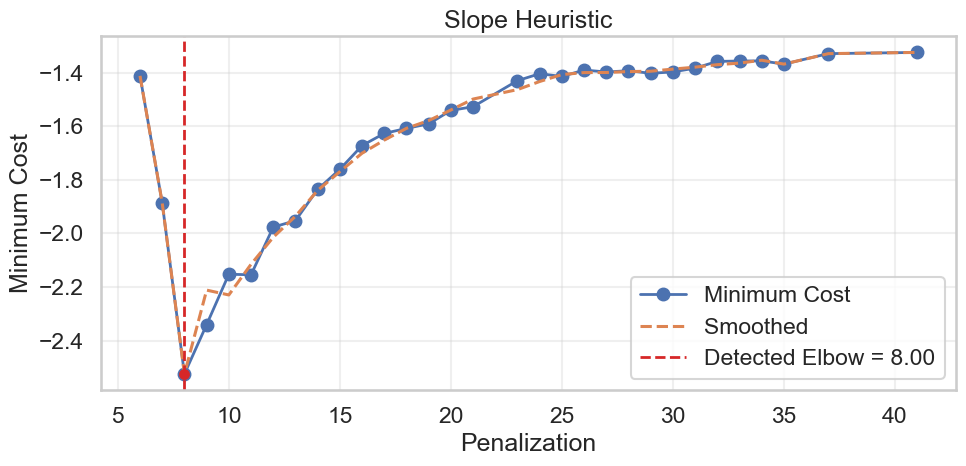

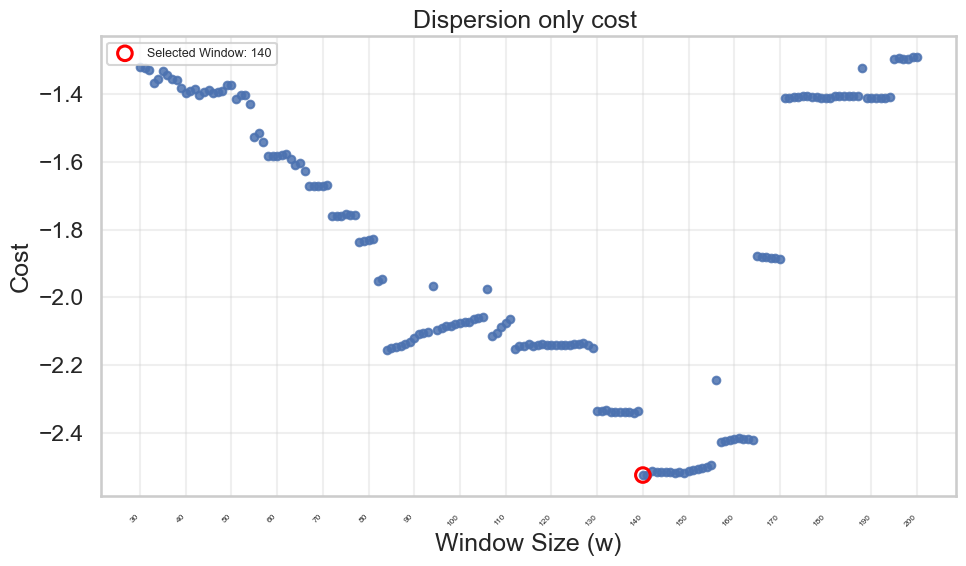

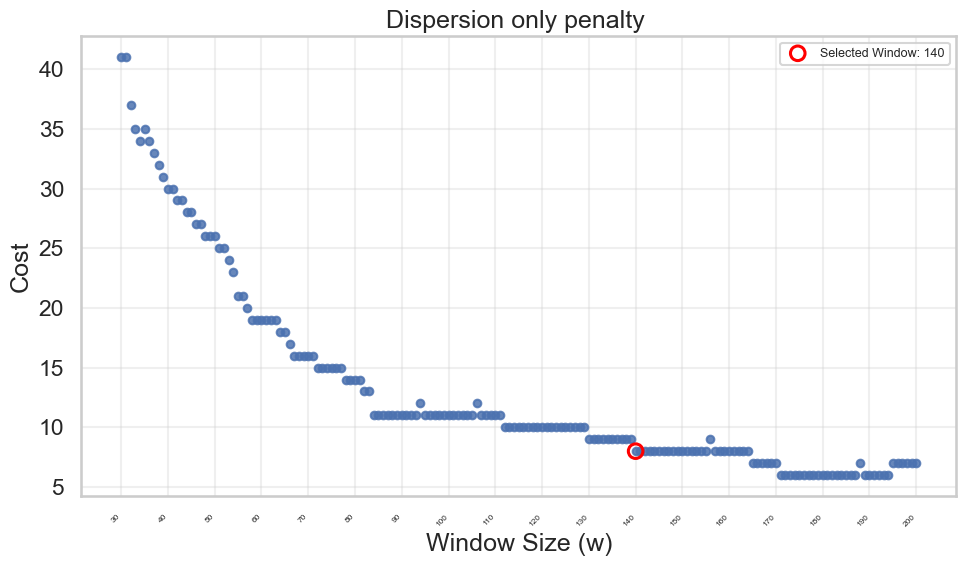

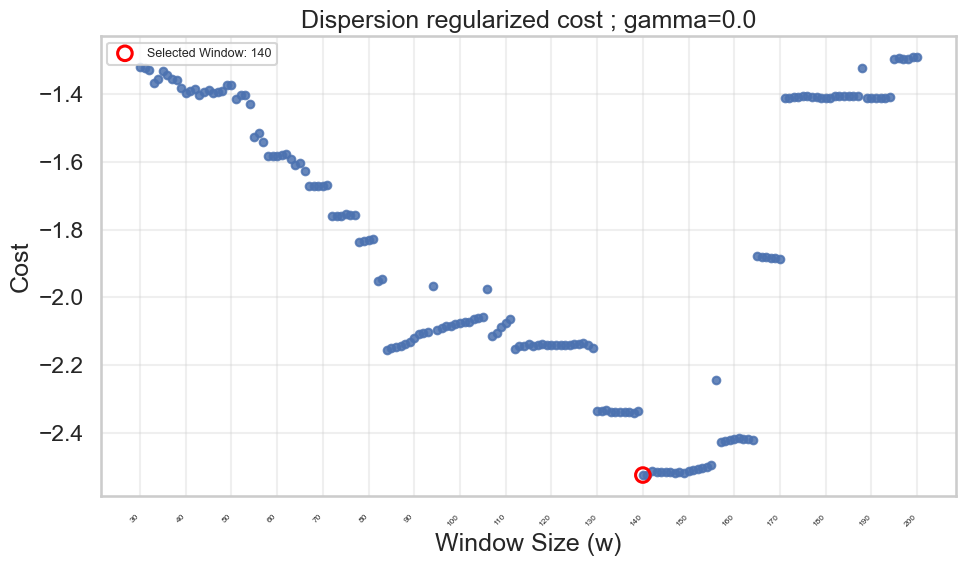

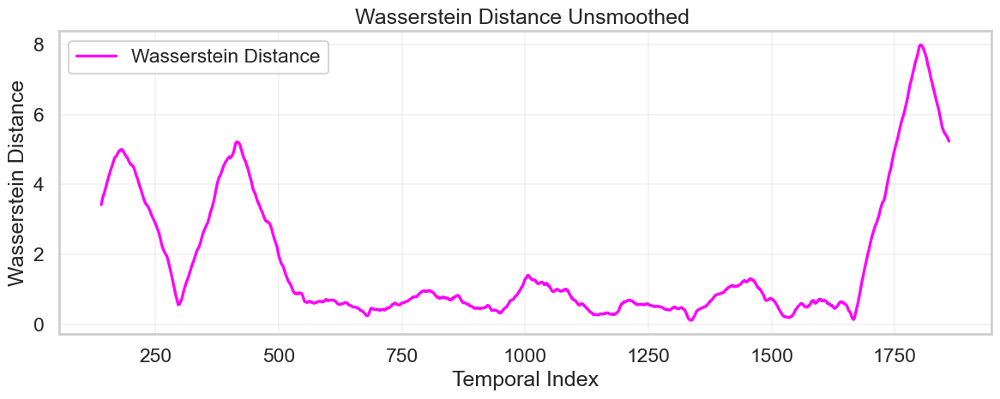

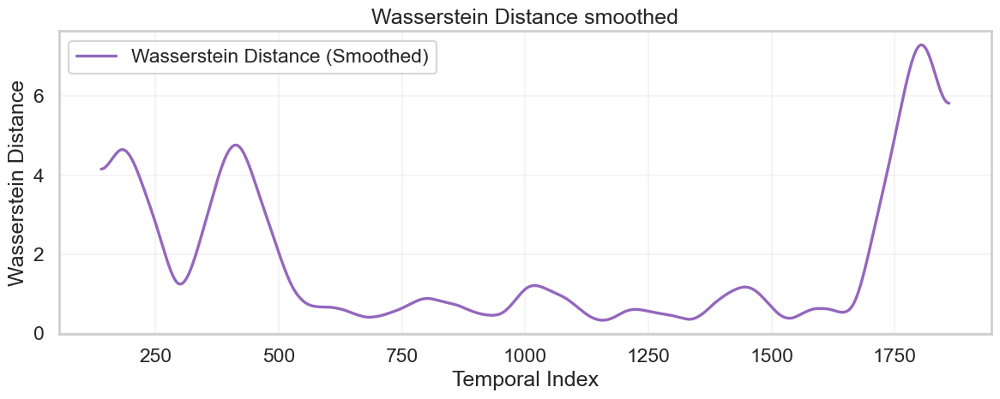

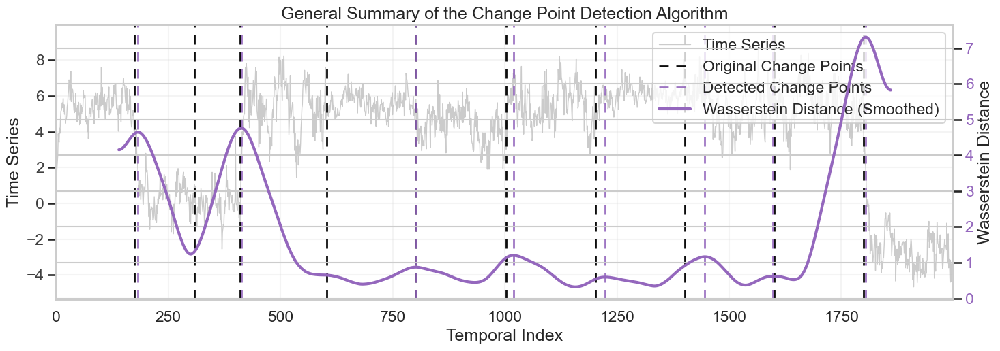

2

════════════════════════════════════════════════════════════════════════
                         Optimización Gaussiano                         
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 8.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 8.0000

Dispersion of Cost
──────────────────
    Execution Time              : 18.2469 s
    Best Window                 : 118

Dispersion of Cost
──────────────────
    Execution Time              : 18.2469 s
    Best Window                 : 118

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 118

Selección final
───

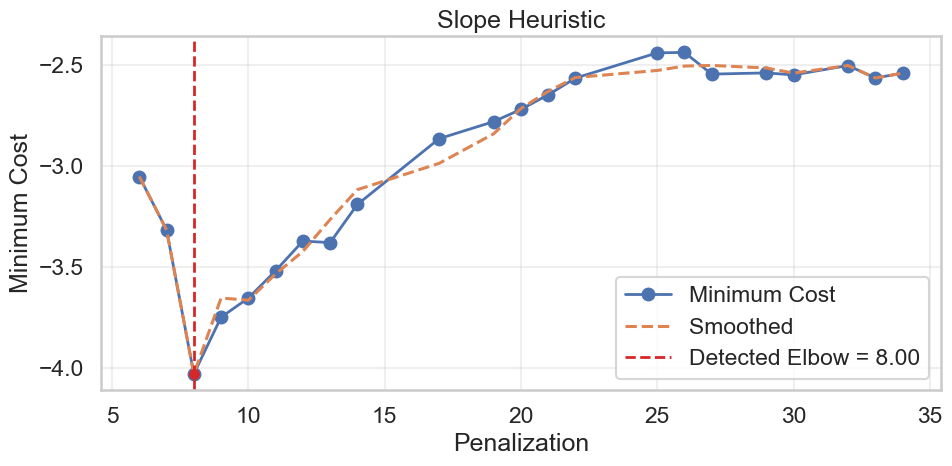

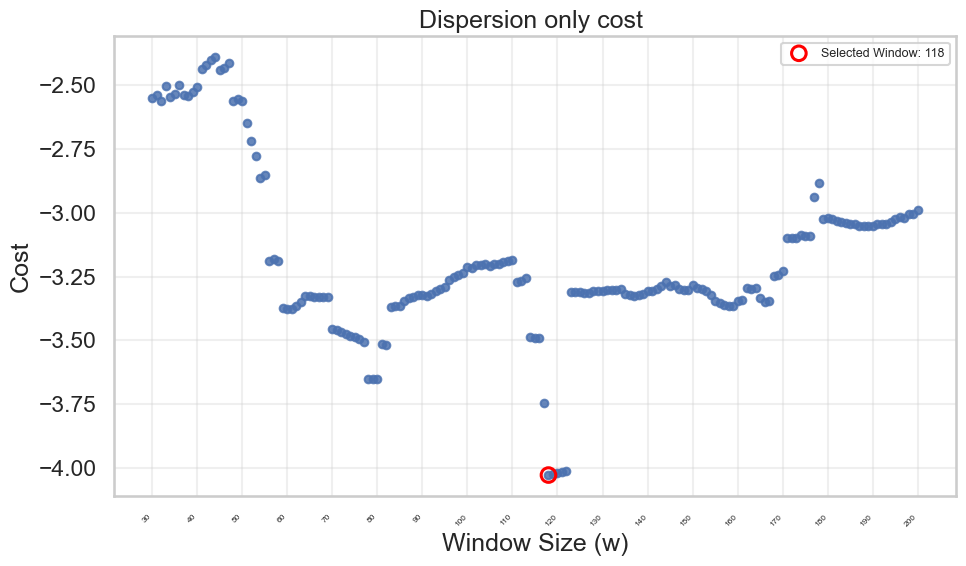

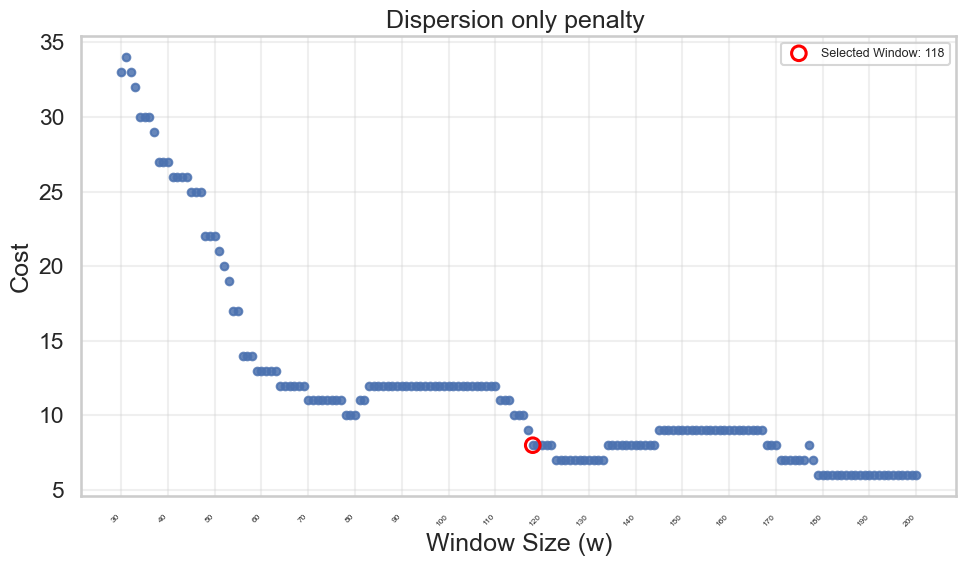

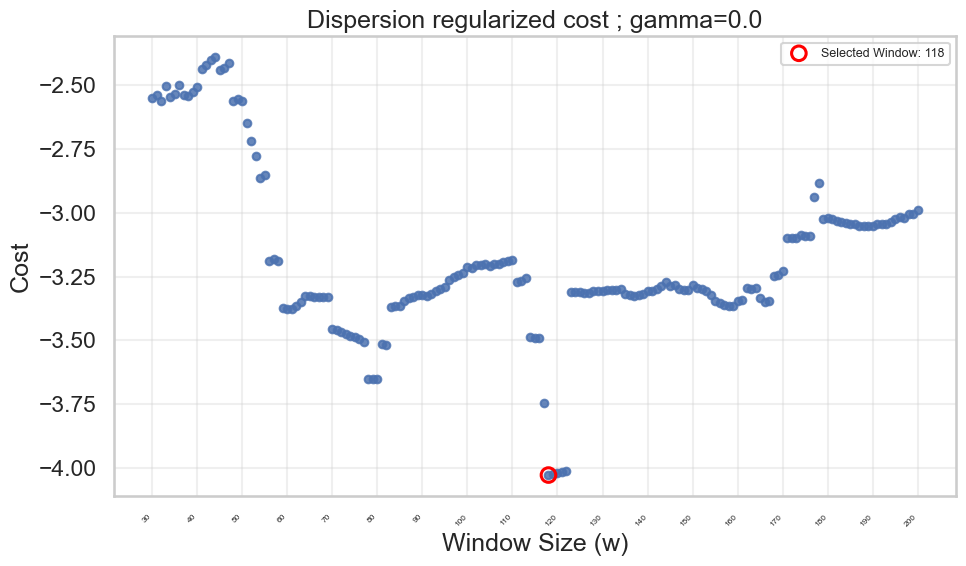

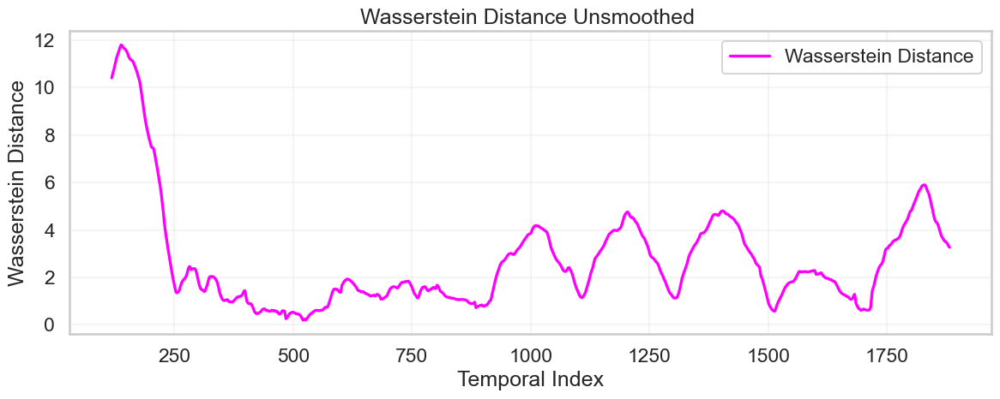

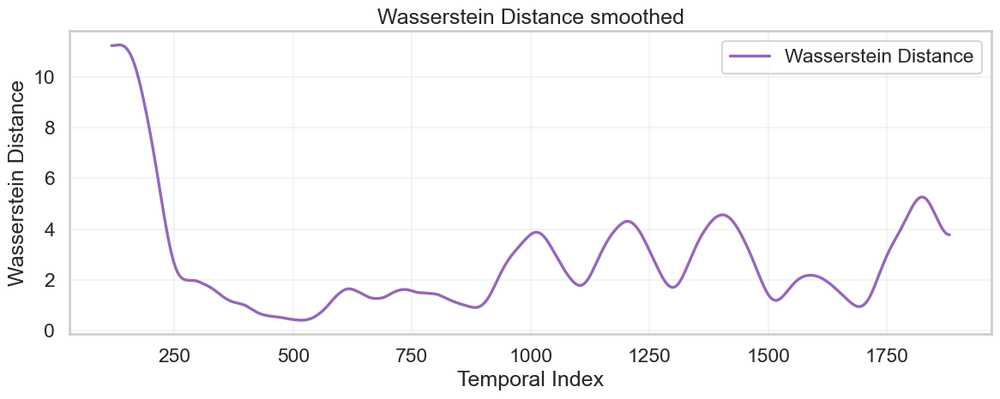

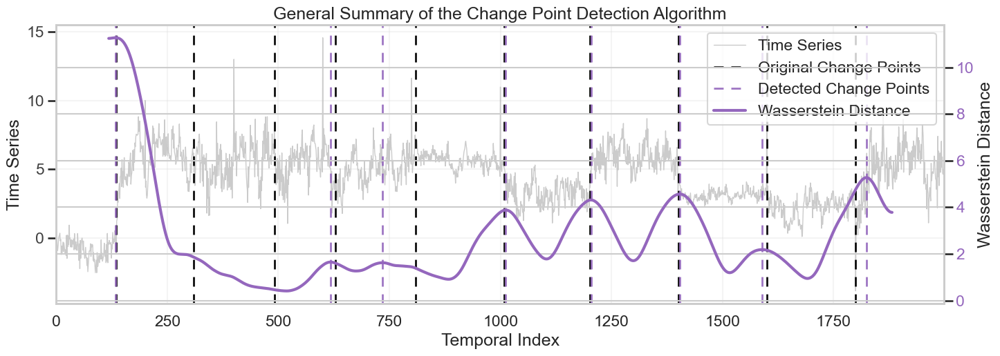


════════════════════════════════════════════════════════════════════════
                         Optimización Empírico                          
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 12.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 12.0000

Dispersion of Cost
──────────────────
    Execution Time              : 12.4878 s
    Best Window                 : 108

Dispersion of Cost
──────────────────
    Execution Time              : 12.4878 s
    Best Window                 : 108

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 108

Selección final
───

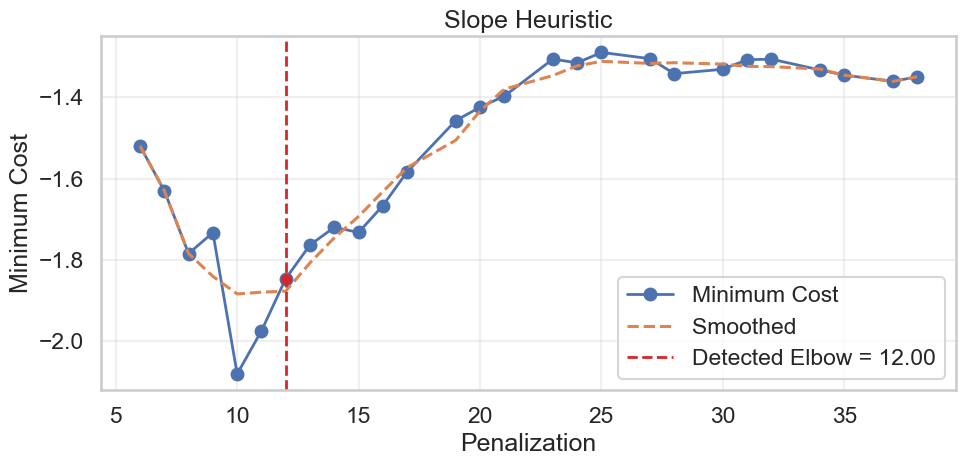

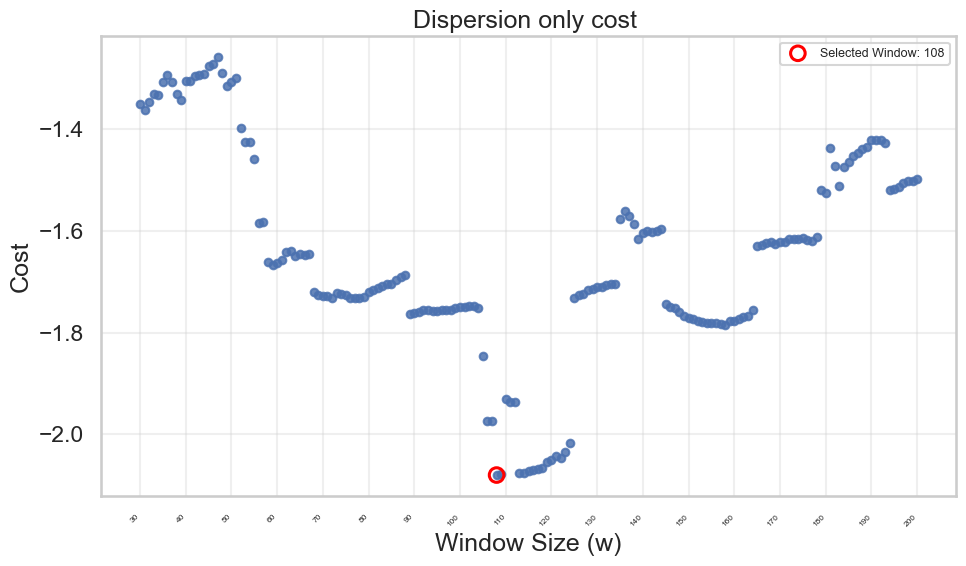

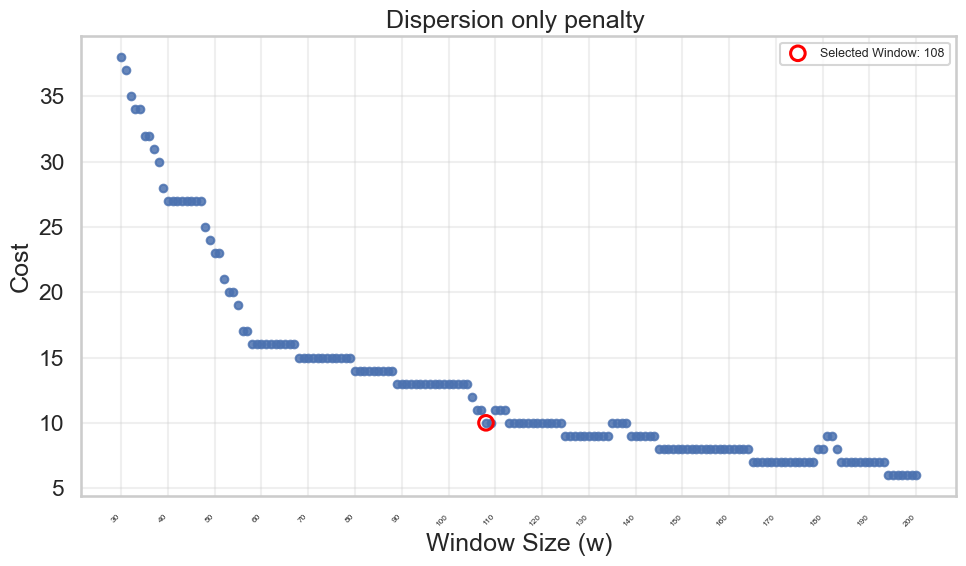

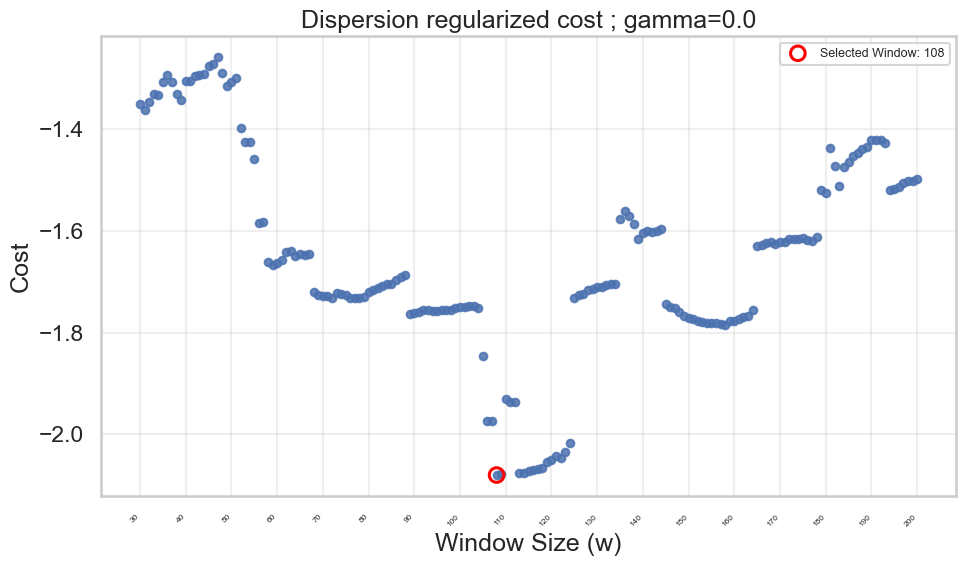

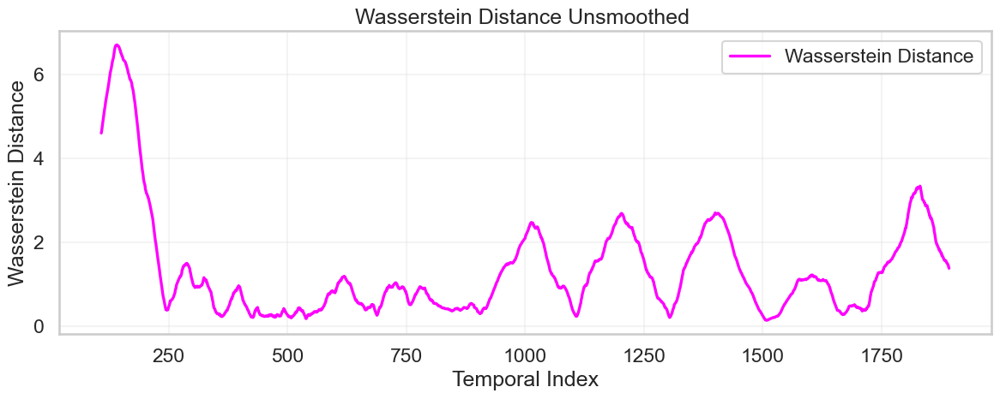

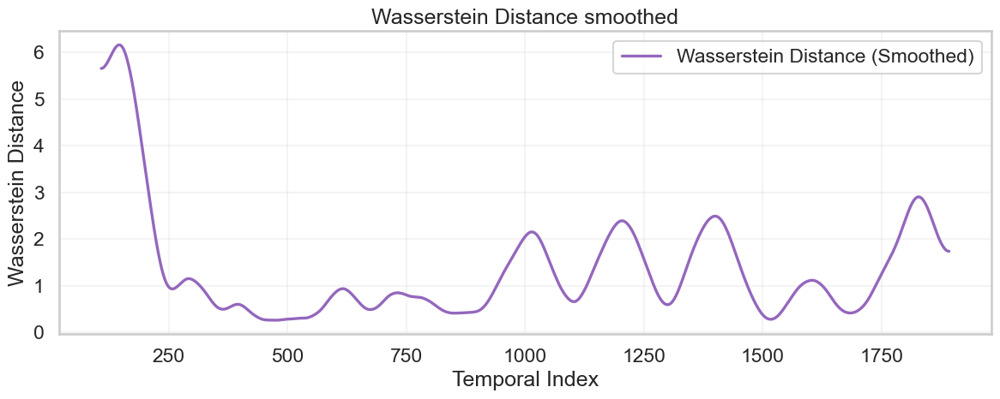

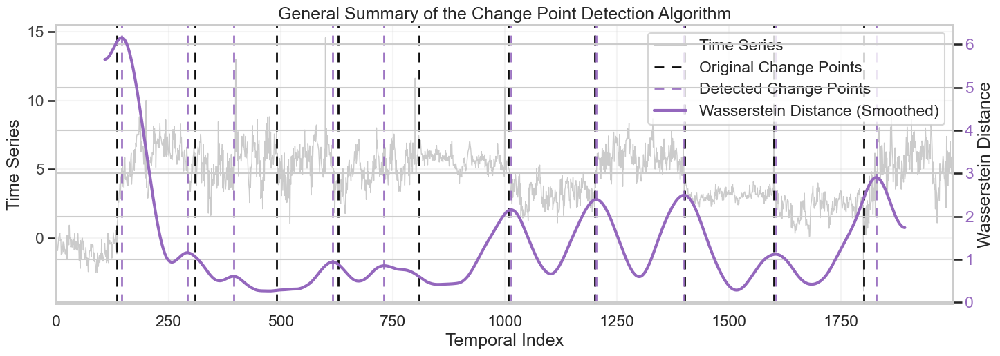

3

════════════════════════════════════════════════════════════════════════
                         Optimización Gaussiano                         
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 9.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 9.0000

Dispersion of Cost
──────────────────
    Execution Time              : 18.3711 s
    Best Window                 : 144

Dispersion of Cost
──────────────────
    Execution Time              : 18.3711 s
    Best Window                 : 144

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 144

Selección final
───

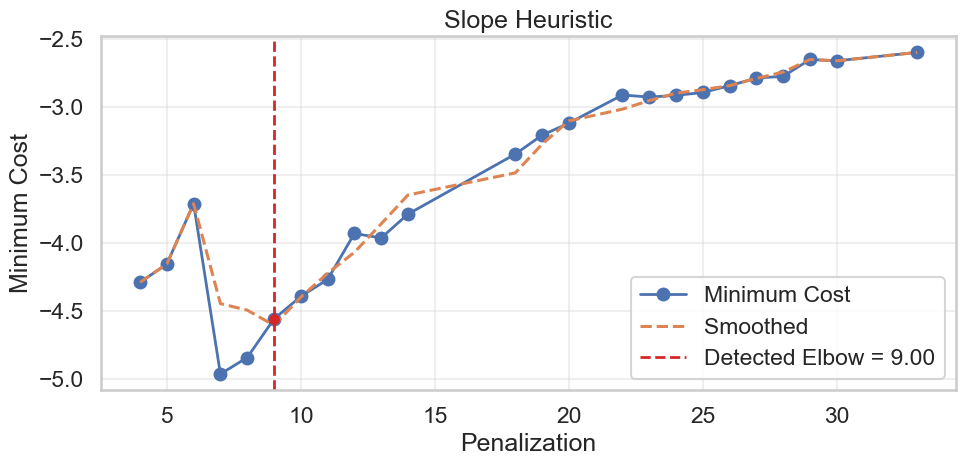

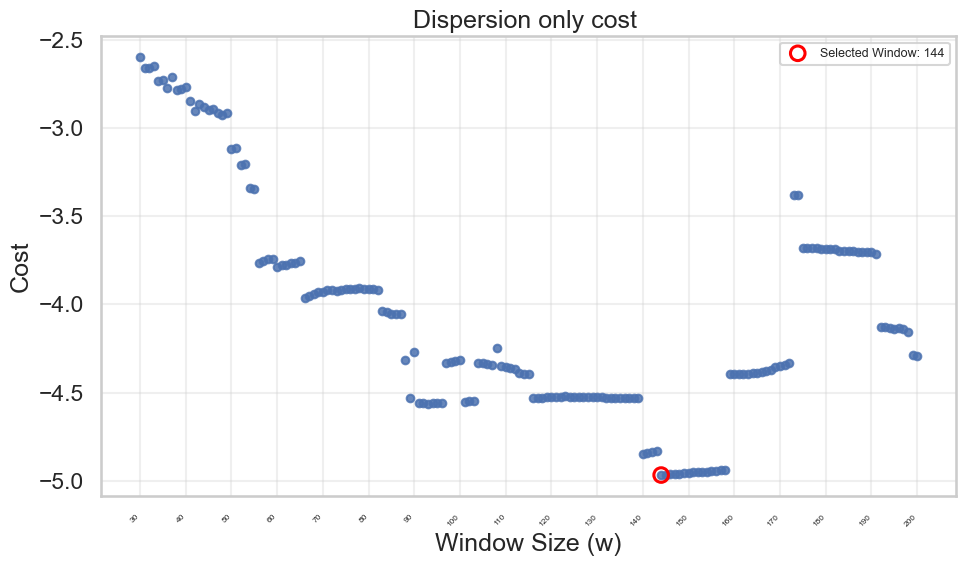

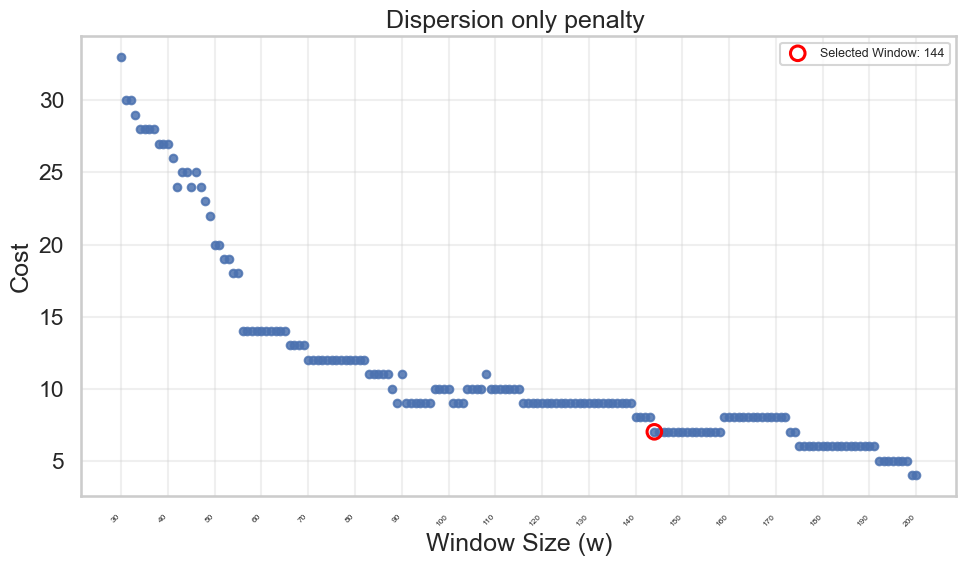

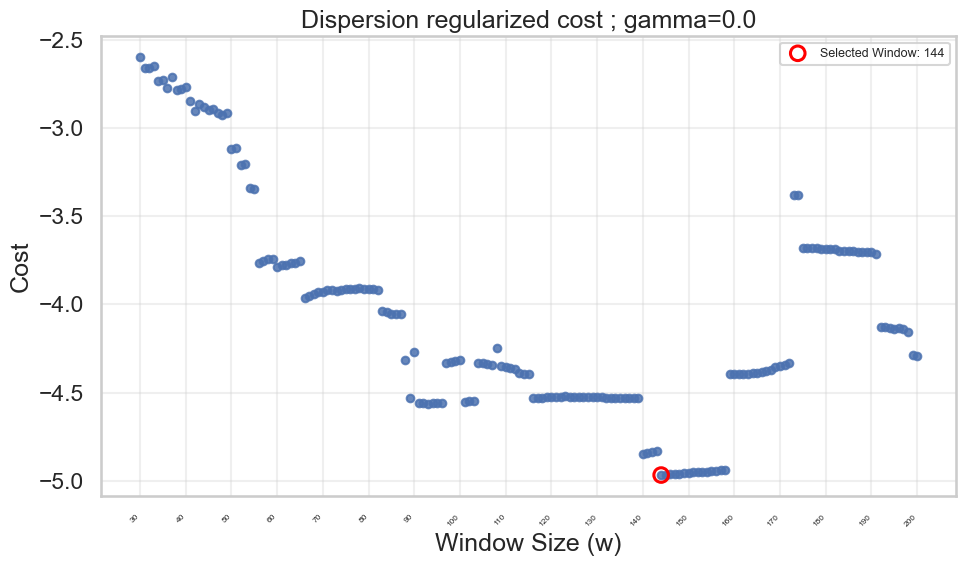

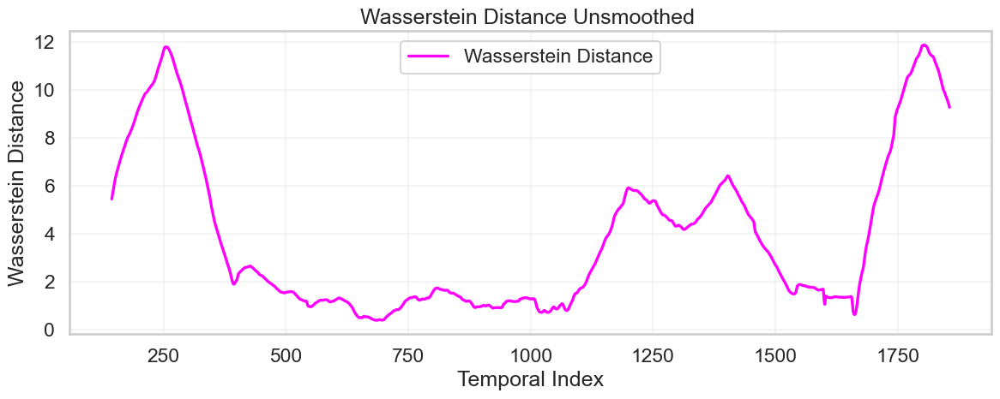

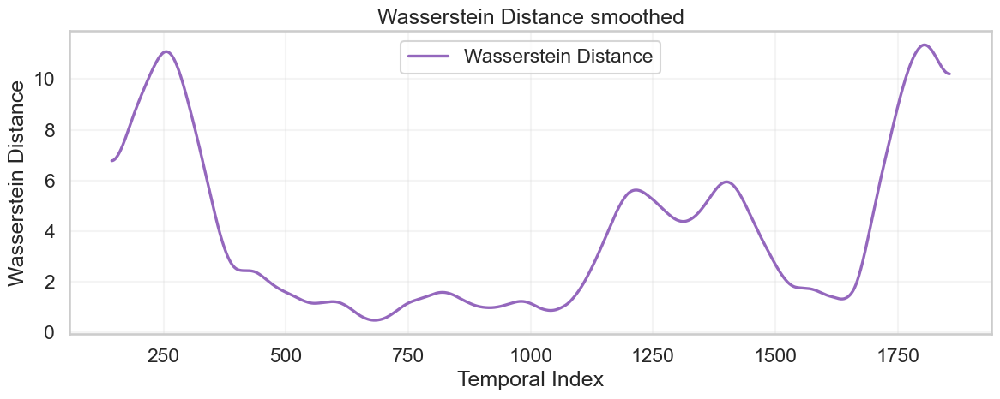

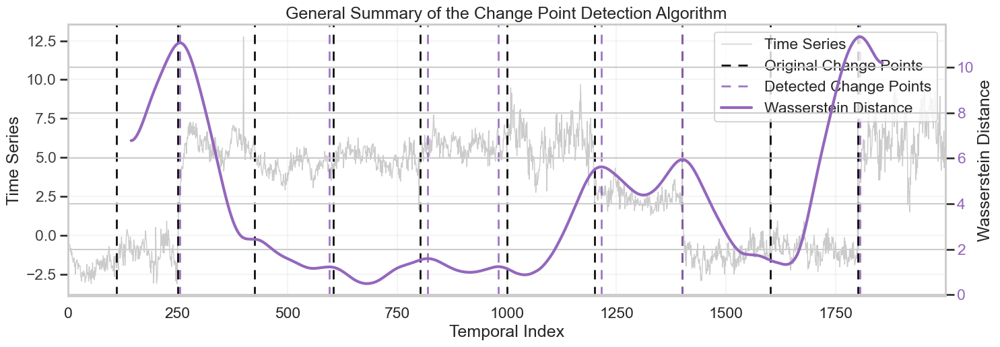


════════════════════════════════════════════════════════════════════════
                         Optimización Empírico                          
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 10.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 10.0000

Dispersion of Cost
──────────────────
    Execution Time              : 13.0198 s
    Best Window                 : 141

Dispersion of Cost
──────────────────
    Execution Time              : 13.0198 s
    Best Window                 : 141

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 141

Selección final
───

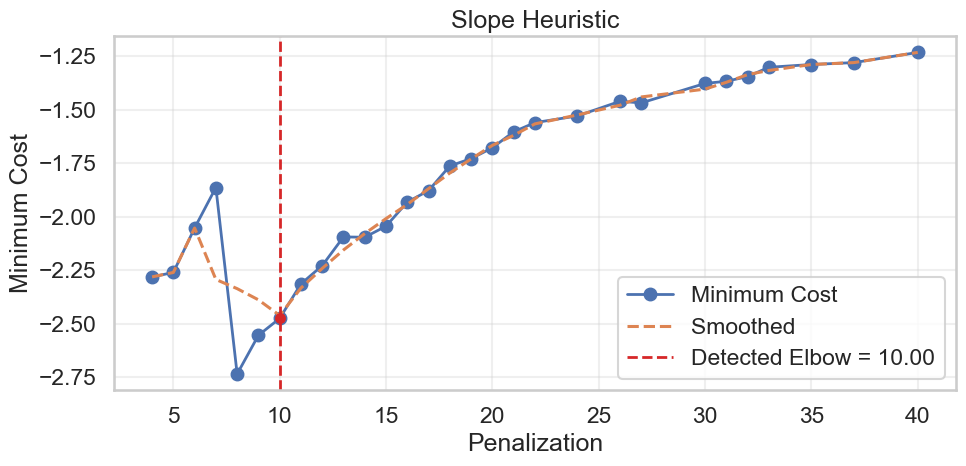

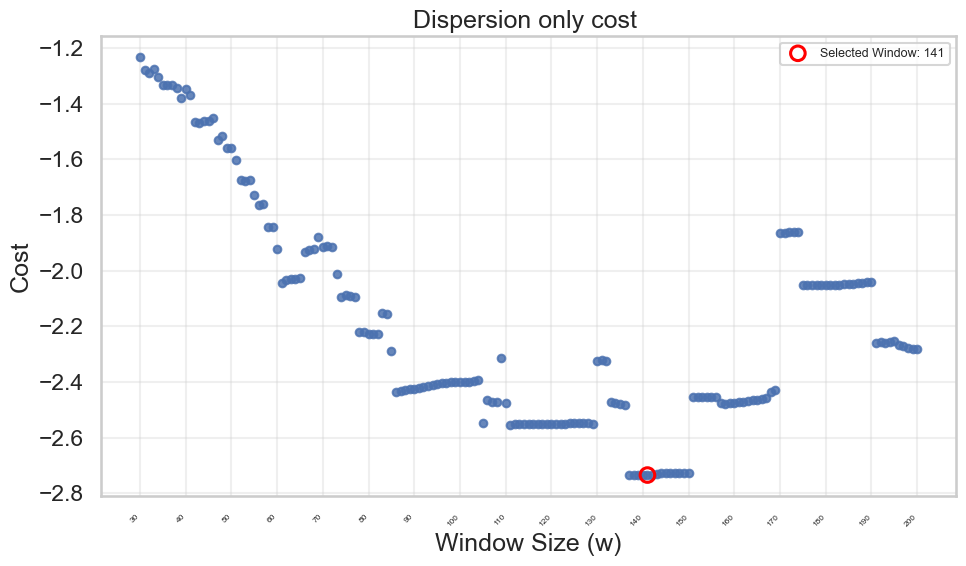

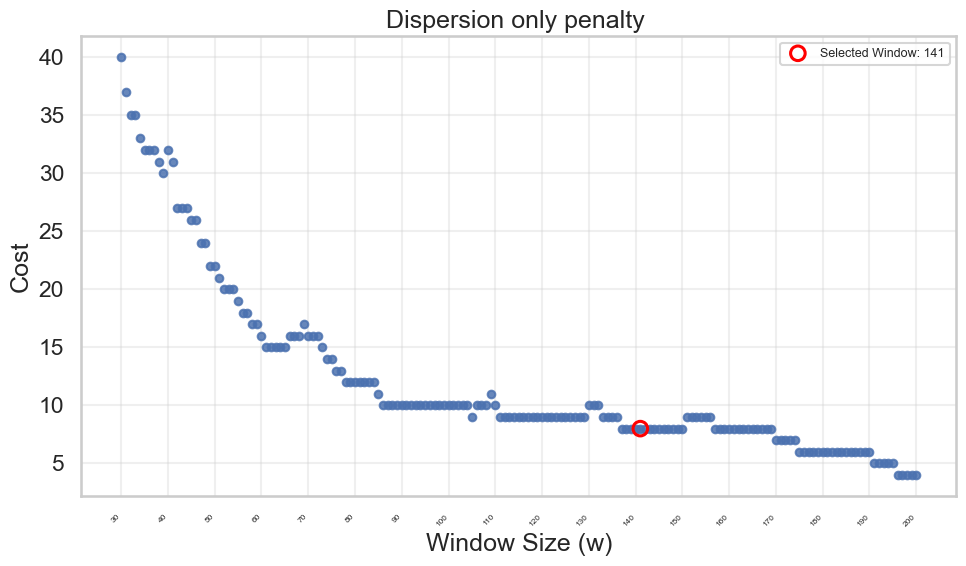

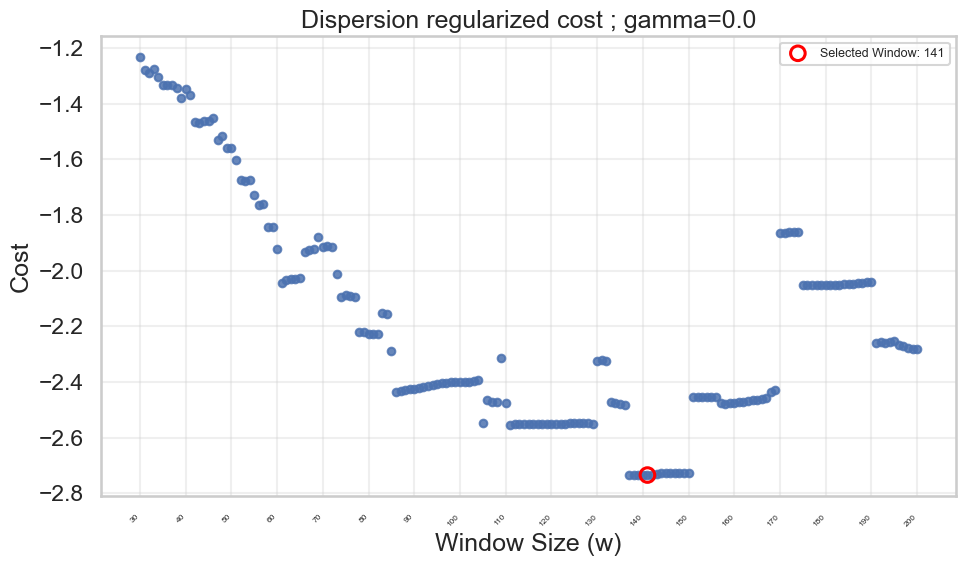

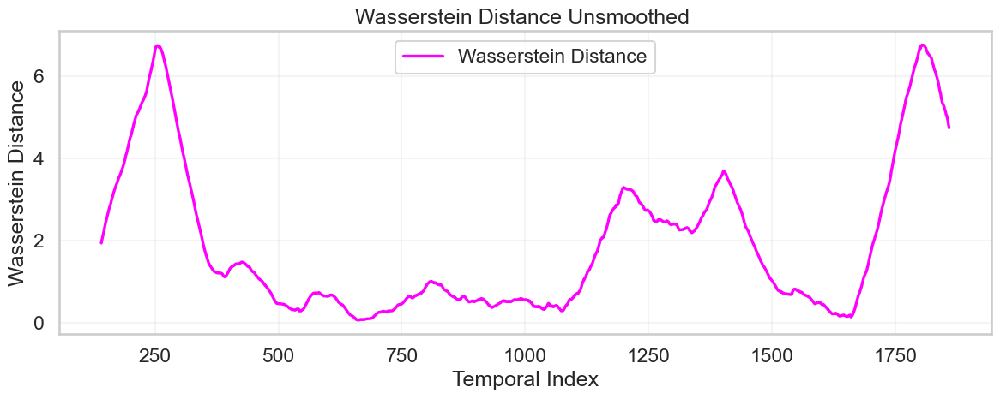

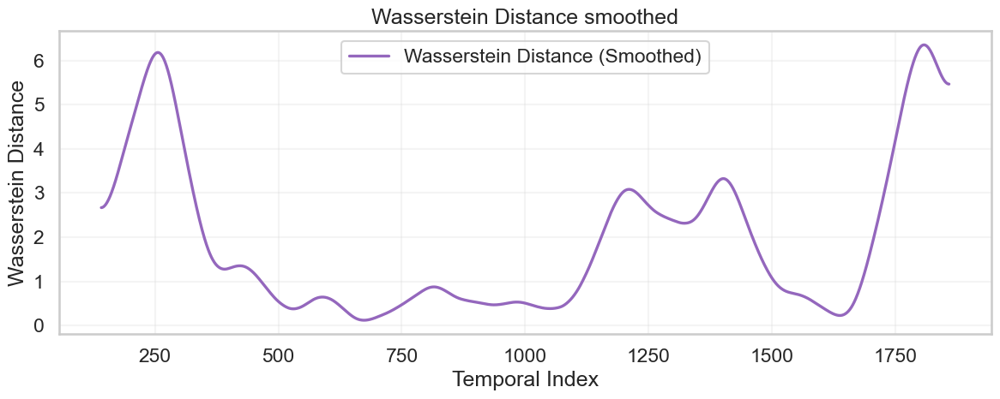

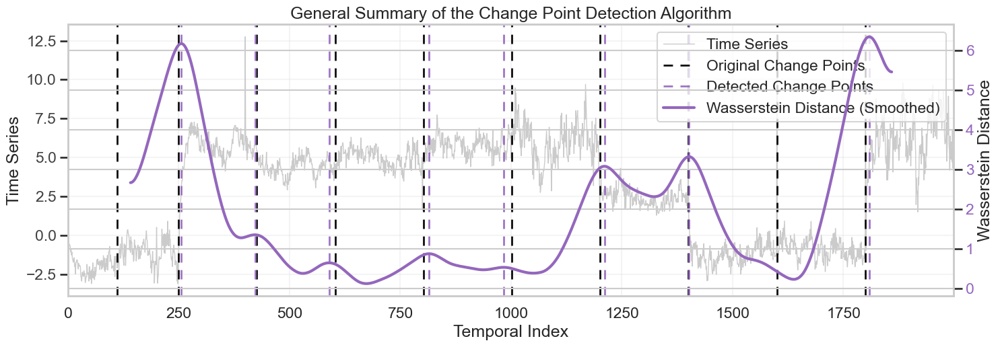

4

════════════════════════════════════════════════════════════════════════
                         Optimización Gaussiano                         
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 26.0000

Selección final
───────────────
    Ventana óptima              : 77
    Retardo óptimo              : 1
    Penalización mínima         : 0
    Gamma final                 : 0.0000
    Tiempo de búsqueda          : 18.4730
    [OK] Optimización finalizada

════════════════════════════════════════════════════════════════════════
                         Optimización Empírico                          
════════════════════════════════════════════════════════════════════════
    Tamaño de serie       

In [7]:
metricas_ar2_mdf_gauss_opt = []
metricas_ar2_mdf_emp_opt = []


experimentos_gauss_opt = []
experimentos_emp_opt = []
for i in range(200):
    print(i)
    ar2_mdf, cps_ar2_mdf, outliers_ar2_mdf = ar2_noise(
            T = 2000,
            n_segmentos = 11,
            min_mean_diff = 0.05,
            min_seg = 100,
            max_seg = 200,
            base_mean = 0.3,
            std_range = (0.3, 1.2),
            seed = 1234+i
        )

    if i <= 3:
        visualization={
                                                                            "summary": True,
                                                                            "raw_distance": True,
                                                                            "smooth_distance": True,
                                                                            "cost": True,
                                                                            "slope": True,
                                                                        }
    else:
        visualization={
                                                                            "summary": False,
                                                                            "raw_distance": False,
                                                                            "smooth_distance": False,
                                                                            "cost": False,
                                                                            "slope": False,
                                                                        }

    metricas_ar2_mdf_gauss_opt.append(
                                            best_params_sh(
                                                                ar2_mdf,
                                                                cps_ar2_mdf,
                                                                penal=True,
                                                                path='',
                                                                mean_gauss=True,
                                                                name=f"AR2_{i+1} Media y Dispersión Fluctuantes",
                                                                modo="Gaussiano",
                                                                given=False,
                                                                thr_dist=20,
                                                                min_w = 30,
                                                                max_w = 200,
                                                                t_given=1,
                                                                smooth_distances=True,
                                                                visualization=visualization,
                                                                save_fig=False,
                                                                temporal_comp=True,
                                                                max_bandwidth=True,
                                                                prominence_ratio=0)[0]
                                        )
    

    metricas_ar2_mdf_emp_opt.append(
                                        best_params_sh(
                                                            ar2_mdf,
                                                            cps_ar2_mdf,
                                                            penal=True,
                                                            path='',
                                                            name=f"AR2_{i+1} Media y Dispersión Fluctuantes",
                                                            modo="Empírico",
                                                            given=False,
                                                            thr_dist=20,
                                                            min_w = 30,
                                                            max_w = 200,
                                                            smooth_distances=True,
                                                            visualization=visualization,
                                                            save_fig=False,
                                                            temporal_comp=True,
                                                            max_bandwidth=True, 
                                                            prominence_ratio=0)[0]
        )


In [10]:
def experiment_ar2_mdf_temporal_dependence(w=100, delta=20, prominence_ratio=0.05):
    metricas_ar2_mdf_gauss_fw = []
    metricas_ar2_mdf_emp_fw = []
    metricas_ar2_mdf_roerich = []
    metricas_ar2_mdf_window_rbf = []

    for i in range(200):
        print(i)
        ar2_mdf, cps_ar2_mdf, outliers_ar2_mdf = ar2_noise(
            T = 2000,
            n_segmentos = 11,
            min_mean_diff = 0.01,
            min_seg = 100,
            max_seg = 200,
            base_mean = 0.3,
            std_range = (0.3, 1.2),
            seed = 1234+i
        )
        
        #Gaussiano
        cpd_ar2_mdf = CPD(ar2_mdf, window=w, t=1, medias=True, smooth=True, temporal_comp=True)
        distancias_ar2_mdf = cpd_ar2_mdf.distancias()
        cps_detect = detect(distancias_ar2_mdf, w, prominence_ratio=prominence_ratio)
        metricas_ar2_mdf_gauss_fw.append(metrics(cps_ar2_mdf, cps_detect, delta, 2000)[0])

        #Empírico
        cpd_ar2_mdf_emp = EmpiricalCPD(ar2_mdf, window=w, smooth=True)
        distancias_ar2_mdf_emp = cpd_ar2_mdf_emp.distancias()
        cps_detect_emp = detect(distancias_ar2_mdf_emp, w, prominence_ratio=prominence_ratio)
        metricas_ar2_mdf_emp_fw.append(metrics(cps_ar2_mdf, cps_detect_emp, delta, 2000)[0])

        #Roerich KL
        puntos_cambio_roerich_ar2_mdf = detectar_cambios_roerich(
                                        ar2_mdf,
                                        window_size=w,
                                        seed=42,
                                        periods=3
                                    )
        
        metricas_ar2_mdf_roerich.append(metrics(cps_ar2_mdf, puntos_cambio_roerich_ar2_mdf, delta, len(ar2_mdf))[0])

        #Window RBF
        puntos_cambio_ar2_mdf_window_rbf = detectar_window_rbf(
                                                ar2_mdf,
                                                window=w
                                            )
        
        metricas_ar2_mdf_window_rbf.append(metrics(cps_ar2_mdf, puntos_cambio_ar2_mdf_window_rbf, delta, len(ar2_mdf))[0])
        
    return metricas_ar2_mdf_gauss_fw, metricas_ar2_mdf_emp_fw, metricas_ar2_mdf_roerich, metricas_ar2_mdf_window_rbf

### 2.4.2. Gráficas y Resultados Promedio

In [11]:
lists_metrics_ar2_mdf = []
windows = [30, 50, 80, 100]
for w in windows:
    print(f'WINDOW SIZE: {w}')
    prominence_ratio=0.05
    if w>=80:
        prominence_ratio=0
    lists_metrics_ar2_mdf.append(experiment_ar2_mdf_temporal_dependence(w=w, delta=20, prominence_ratio=prominence_ratio))

WINDOW SIZE: 30
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
WINDOW SIZE: 50
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95


In [ ]:
for metricas, w in zip(lists_metrics_ar2_mdf, windows):
    exportar_excel(metricas, f"Resultados_Series_Simuladas/AR(2)_Fluctuating_average/Tables/ar2_mdf_metrics_window_{w}.xlsx", ["Gauss", "Empirical", "Roerich-KL", "Window-RBF"])

WINDOW SIZE: 30


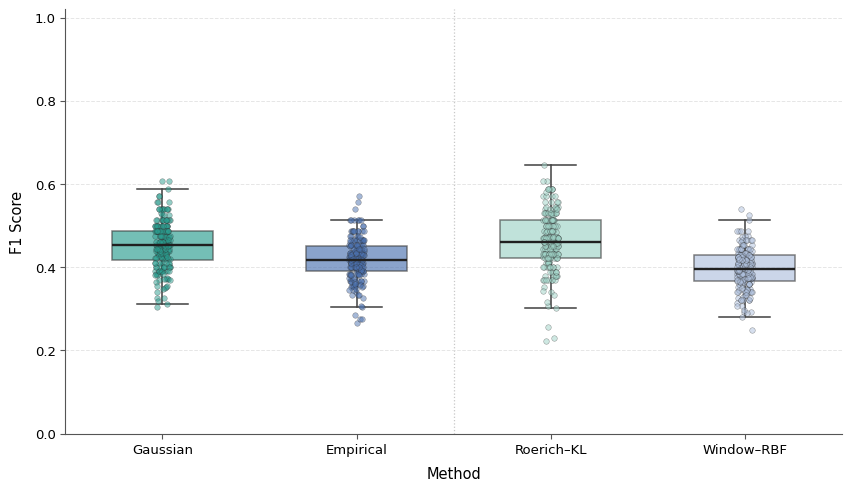

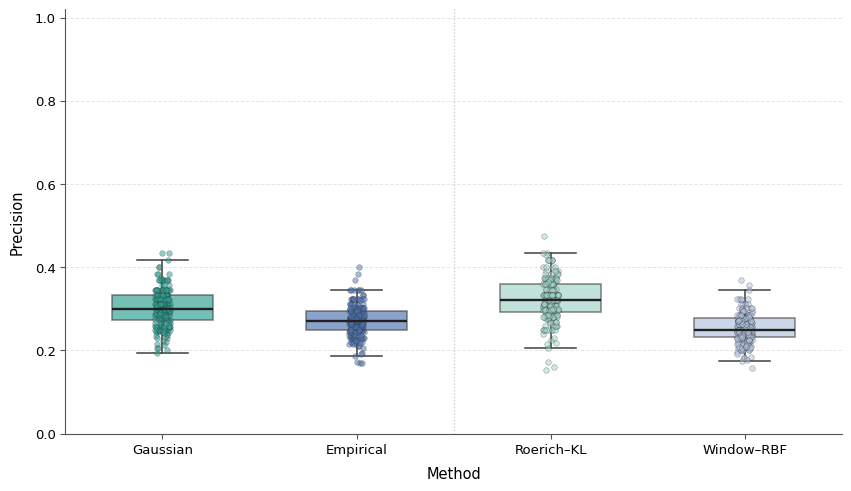

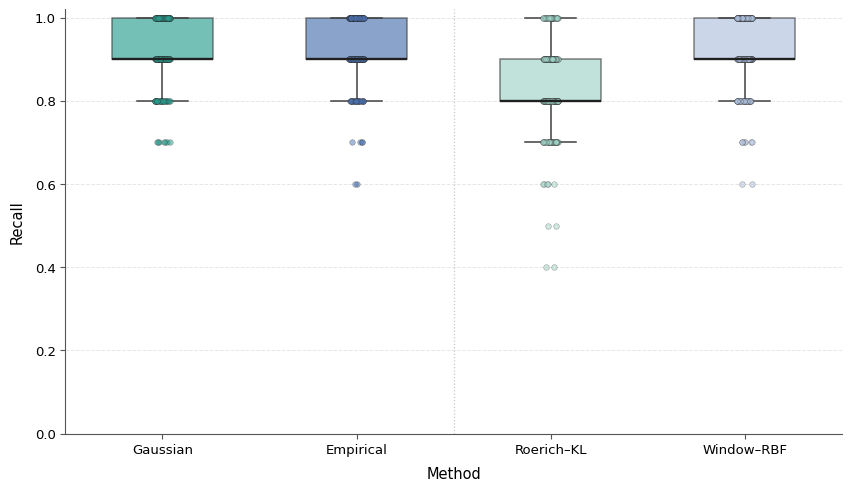

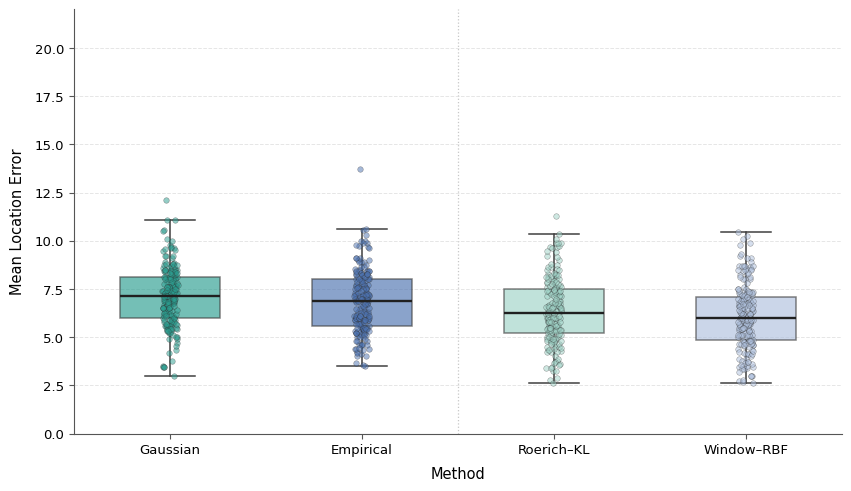

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.301380,0.9240,0.453448,7.114014
1,Empirical,0.270560,0.9270,0.418061,6.831748
2,Roerich-KL,0.320521,0.8355,0.462640,6.374480
3,Window-RBF,0.253355,0.9225,0.396777,6.069562


WINDOW SIZE: 50


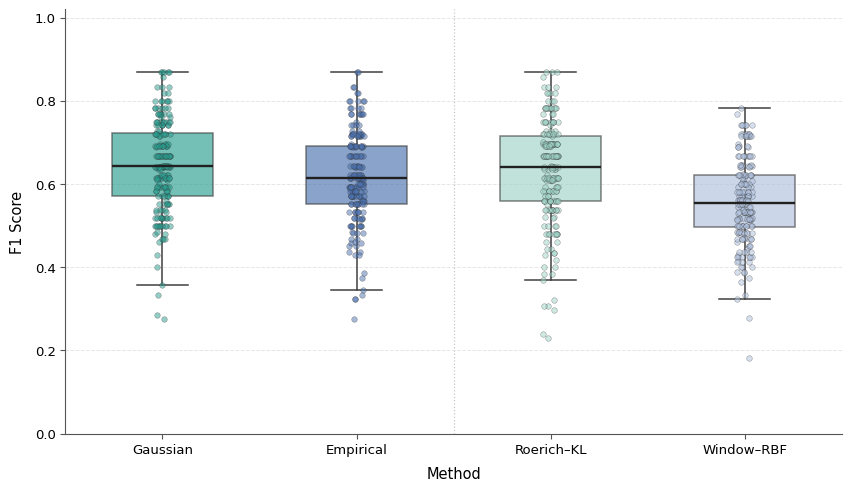

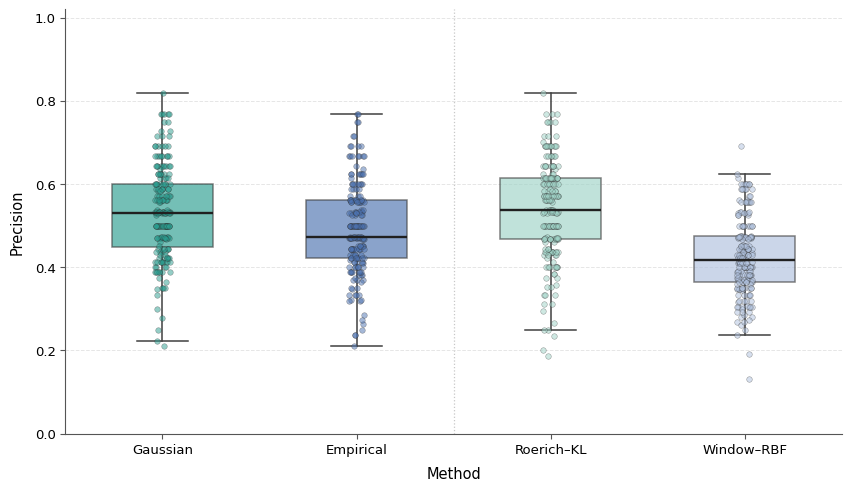

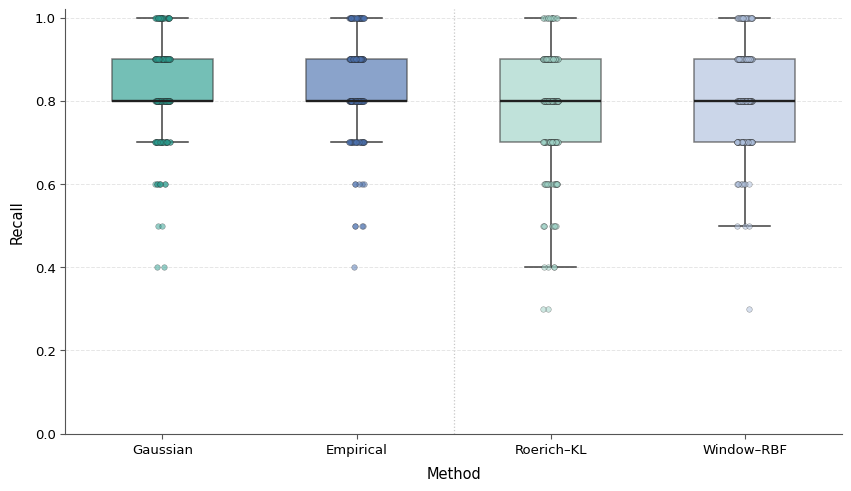

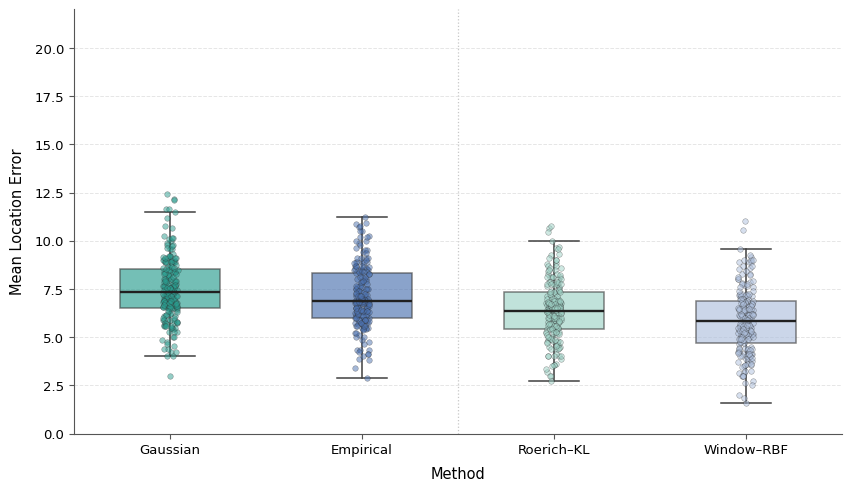

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.531035,0.8295,0.644514,7.458018
1,Empirical,0.491398,0.8370,0.615948,7.101266
2,Roerich-KL,0.535863,0.7710,0.630344,6.391835
3,Window-RBF,0.425688,0.8210,0.557784,5.824079


WINDOW SIZE: 80


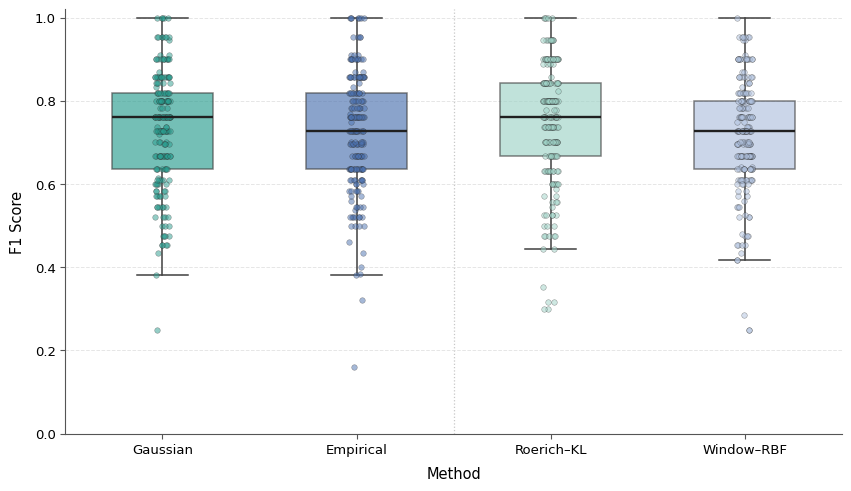

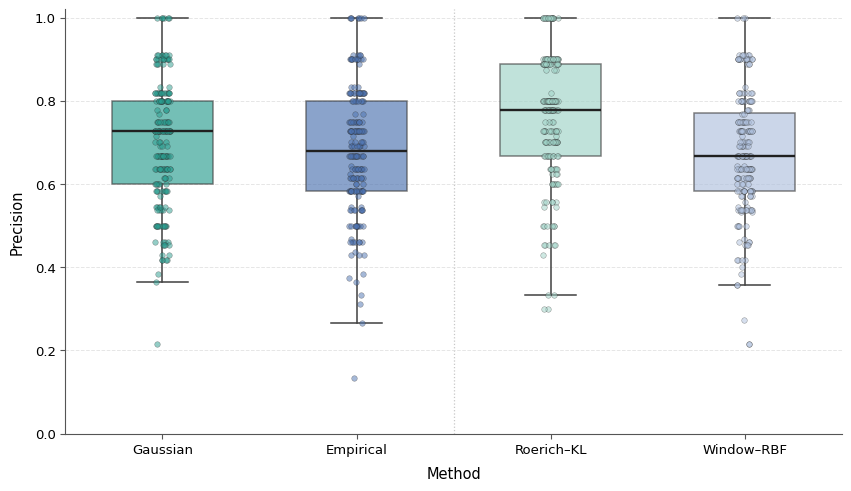

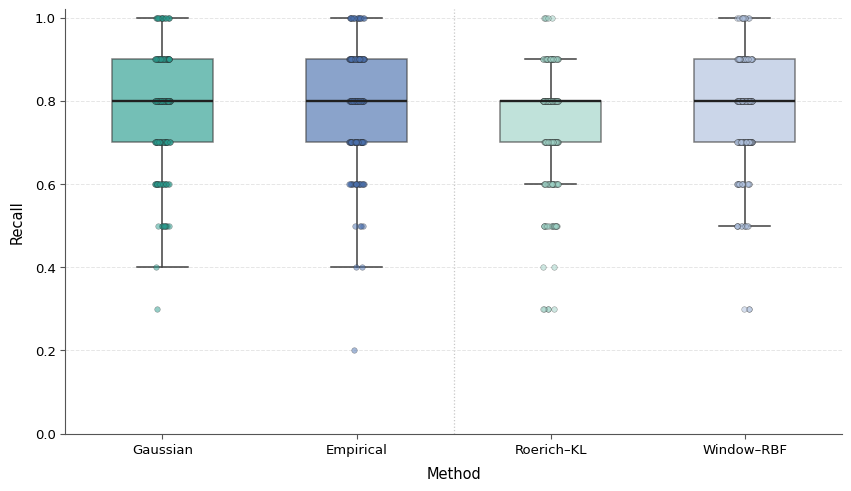

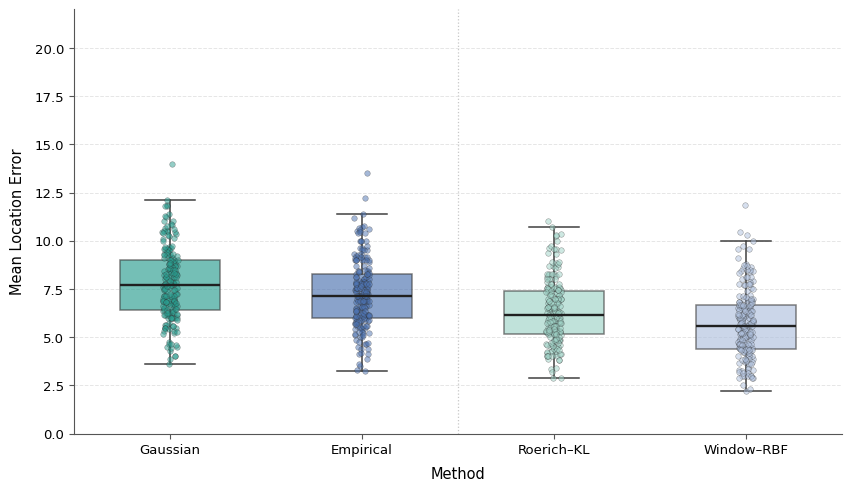

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.697033,0.7760,0.732359,7.758419
1,Empirical,0.679271,0.7855,0.726373,7.252946
2,Roerich-KL,0.762502,0.7310,0.744868,6.317454
3,Window-RBF,0.674440,0.7670,0.715064,5.709760


WINDOW SIZE: 100


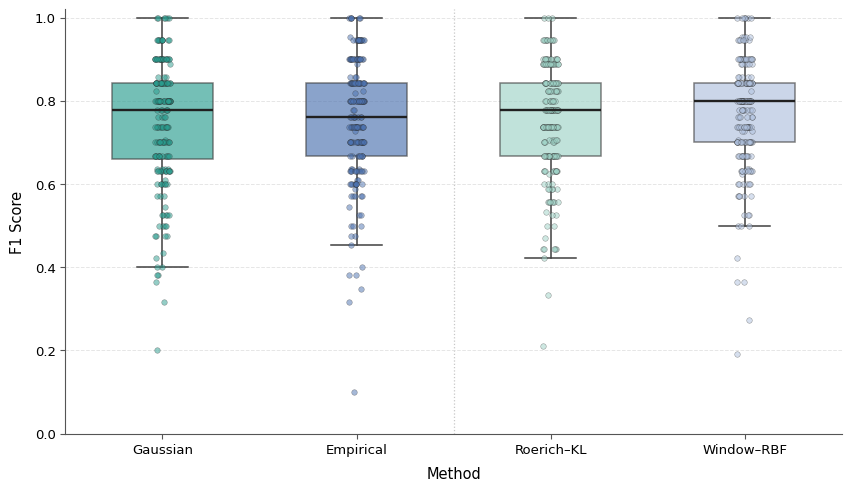

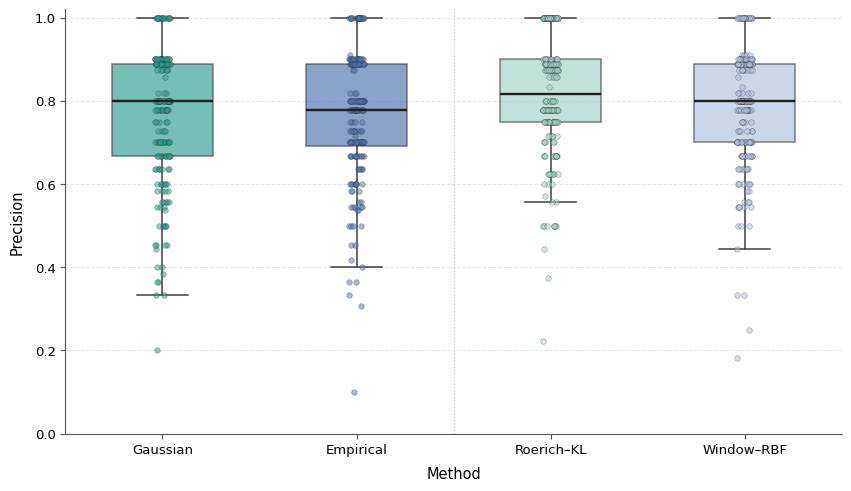

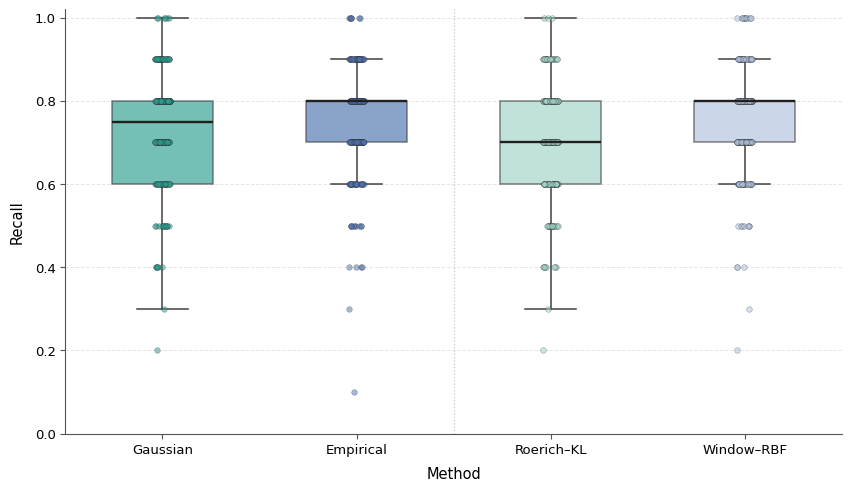

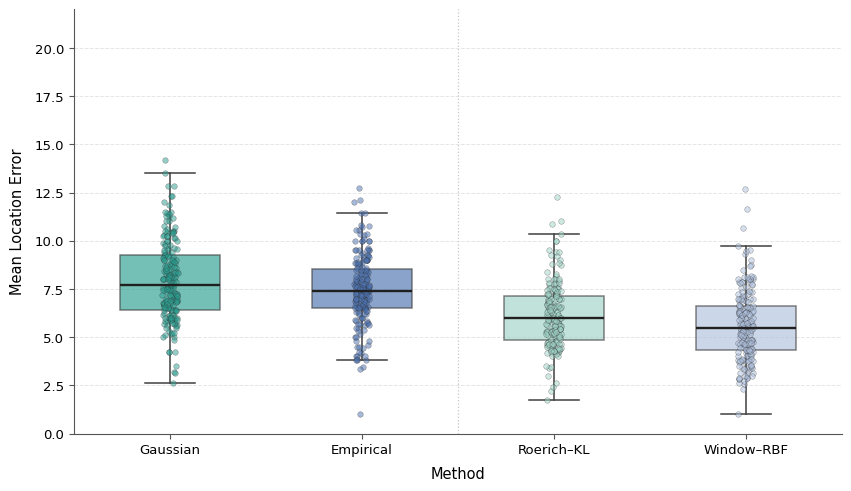

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.760805,0.7325,0.744722,7.917849
1,Empirical,0.765795,0.7440,0.753098,7.442762
2,Roerich-KL,0.816351,0.6965,0.749349,6.104357
3,Window-RBF,0.784392,0.7525,0.765999,5.594177


In [46]:
for w in [30, 50, 80, 100]:
    print("=" * 60)
    print(f"WINDOW SIZE: {w}")
    print("=" * 60)
    ruta_ar2_mdf = f"Resultados_Series_Simuladas/AR(2)_Fluctuating_average/Tables/ar2_mdf_metrics_window_{w}.xlsx"

    hojas = pd.read_excel(ruta_ar2_mdf, sheet_name=None)

    listas = [df.to_dict(orient="records") for df in hojas.values()]

    lista_gauss, lista_emp, lista_roerich, lista_window_rbf = listas

    nombres_boxplot = [
                        "Gaussian",
                        "Empirical",
                        "Roerich–KL",
                        "Window–RBF"
                    ]

    metrics_names = ['F1 Score', 'Precision', 'Recall', 'Mean Location Error']
    for n in metrics_names:
        ylim = (0, 1.02)
        name = n
        if n == 'Mean Location Error':
            ylim = (0, 22)
            name = "MLE"
        
        path_fig = f"Resultados_Series_Simuladas/AR(2)_Fluctuating_average/Graphics/Window {w}/{name}_AR2_mdf_w{w}.png"
        fig, ax = plot_boxplots(
                                datos=[
                                    [m[n] for m in lista_gauss],
                                    [m[n] for m in lista_emp],
                                    [m[n] for m in lista_roerich],
                                    [m[n] for m in lista_window_rbf]
                                ],
                                nombres=nombres_boxplot,
                                ylabel=n,
                                xlabel="Method",
                                ylim=ylim,
                                save_path = path_fig
                            )
    ruta_avg_ar2_mdf = f"Resultados_Series_Simuladas/AR(2)_Fluctuating_average/Tables/ar2_mdf_metrics_avg_window_{w}.xlsx"
    average_table = generar_tabla_desde_diccionarios(
                                                        [lista_gauss, lista_emp, lista_roerich, lista_window_rbf],
                                                        ["Gauss", "Empirical", "Roerich-KL", "Window-RBF"],
                                                        ["Precision", "Recall", "F1 Score", "Mean Location Error"]
                                                        )
    display(average_table)
    average_table.to_excel(ruta_avg_ar2_mdf, index=False)

## 2.5. AR(2) CON REZAGOS FLUCTUANTES

### 2.5.1. Simulaciones

In [17]:
def experiment_ar2_rf_temporal_dependence(w=100, delta=20, prominence_ratio=0.05):
    metricas_ar2_rf_gauss_fw = []
    metricas_ar2_rf_emp_fw = []
    metricas_ar2_rf_roerich = []
    metricas_ar2_rf_window_rbf = []

    for i in range(200):
        print(i)
        ar2_rf, cps_ar2_rf, outliers_ar2_rf = ar2_noise(
                        T = 2000,
                        n_segmentos = 11,
                        min_seg = 100,
                        max_seg = 200,
                        random_phi = True,
                        base_mean = 0.5,
                        random_mean = False,
                        base_std = 0.5,
                        random_std = True,
                        std_range = (0.3, 1.2),
                        seed = 1234+i
        )
        
        #Gaussiano
        cpd_ar2_rf = CPD(ar2_rf, window=w, t=1, medias=True, smooth=True, temporal_comp=True)
        distancias_ar2_rf = cpd_ar2_rf.distancias()
        cps_detect = detect(distancias_ar2_rf, w, prominence_ratio=prominence_ratio)
        metricas_ar2_rf_gauss_fw.append(metrics(cps_ar2_rf, cps_detect, delta, 2000)[0])

        #Empírico
        cpd_ar2_rf_emp = EmpiricalCPD(ar2_rf, window=w, smooth=True)
        distancias_ar2_rf_emp = cpd_ar2_rf_emp.distancias()
        cps_detect_emp = detect(distancias_ar2_rf_emp, w, prominence_ratio=prominence_ratio)
        metricas_ar2_rf_emp_fw.append(metrics(cps_ar2_rf, cps_detect_emp, delta, 2000)[0])

        #Roerich KL
        puntos_cambio_roerich_ar2_rf = detectar_cambios_roerich(
                                        ar2_rf,
                                        window_size=w,
                                        seed=42,
                                        periods=3
                                    )
        
        metricas_ar2_rf_roerich.append(metrics(cps_ar2_rf, puntos_cambio_roerich_ar2_rf, delta, len(ar2_rf))[0])

        #Window RBF
        puntos_cambio_ar2_rf_window_rbf = detectar_window_rbf(
                                                ar2_rf,
                                                window=w
                                            )
        
        metricas_ar2_rf_window_rbf.append(metrics(cps_ar2_rf, puntos_cambio_ar2_rf_window_rbf, delta, len(ar2_rf))[0])
        
    return metricas_ar2_rf_gauss_fw, metricas_ar2_rf_emp_fw, metricas_ar2_rf_roerich, metricas_ar2_rf_window_rbf

0

════════════════════════════════════════════════════════════════════════
                         Optimización Gaussiano                         
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 6.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 6.0000

Dispersion of Cost
──────────────────
    Execution Time              : 21.5822 s
    Best Window                 : 199

Dispersion of Cost
──────────────────
    Execution Time              : 21.5822 s
    Best Window                 : 199

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 199

Selección final
───

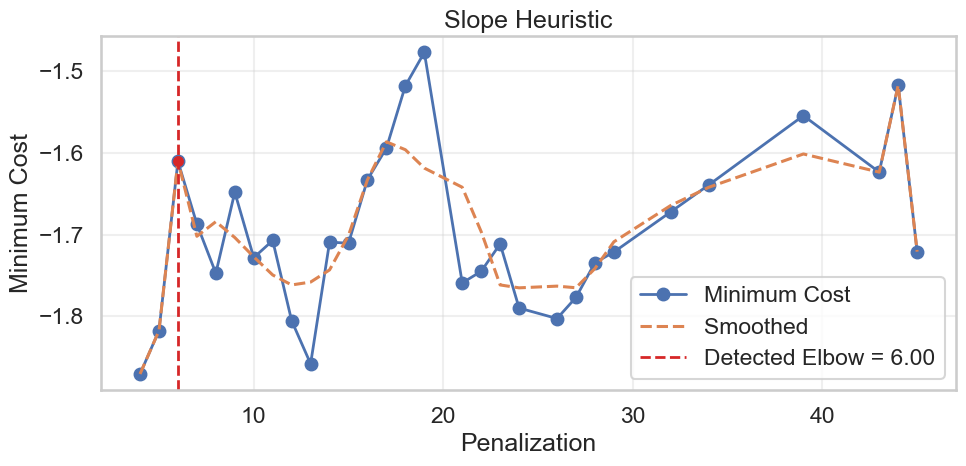

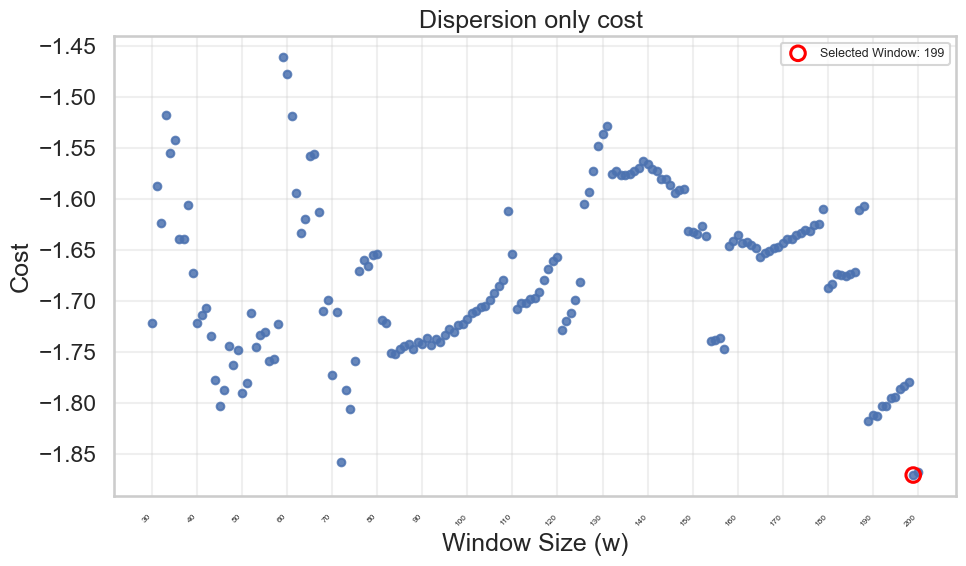

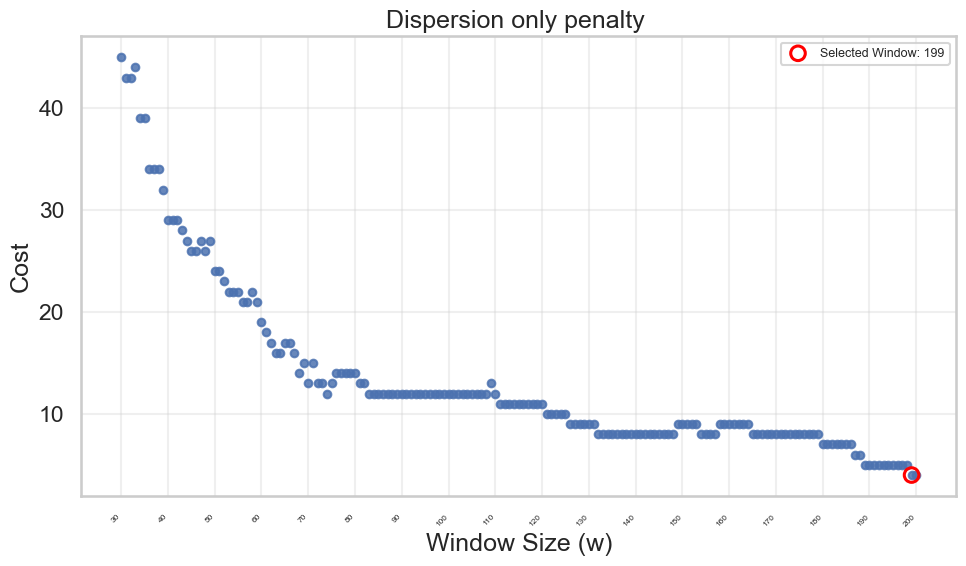

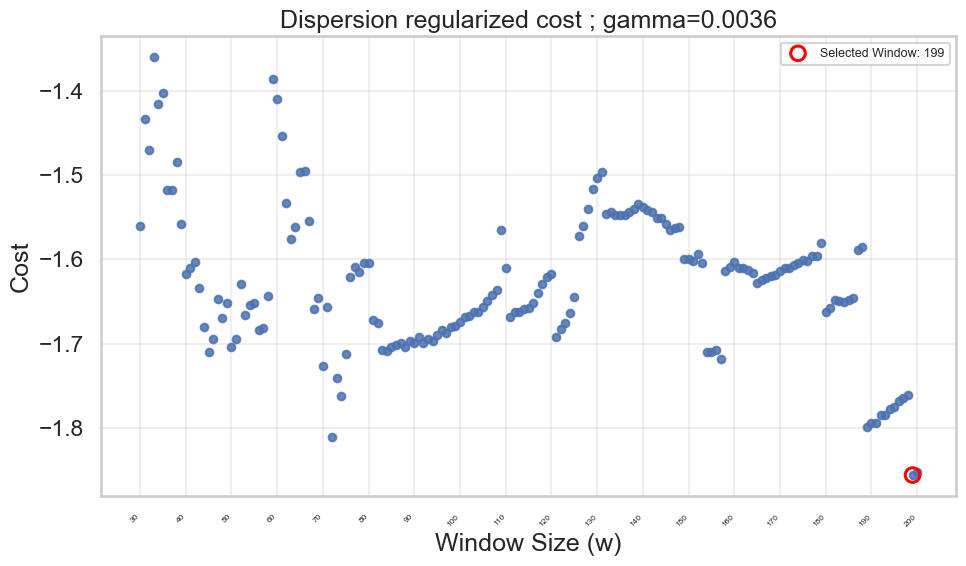

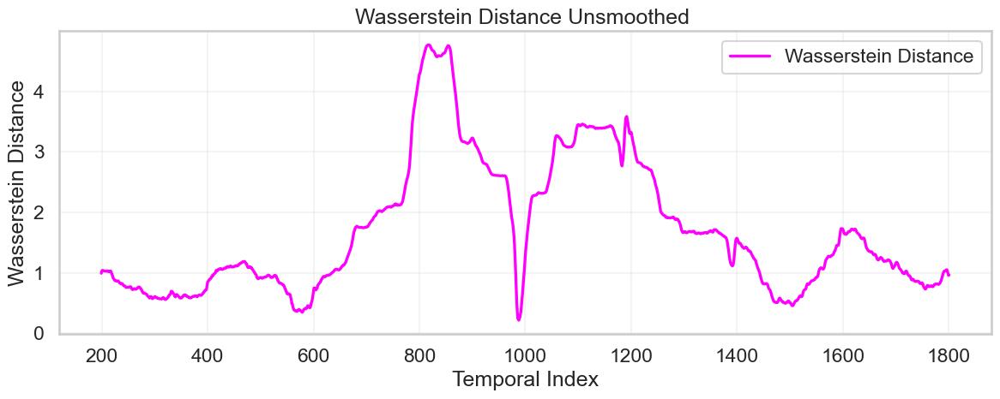

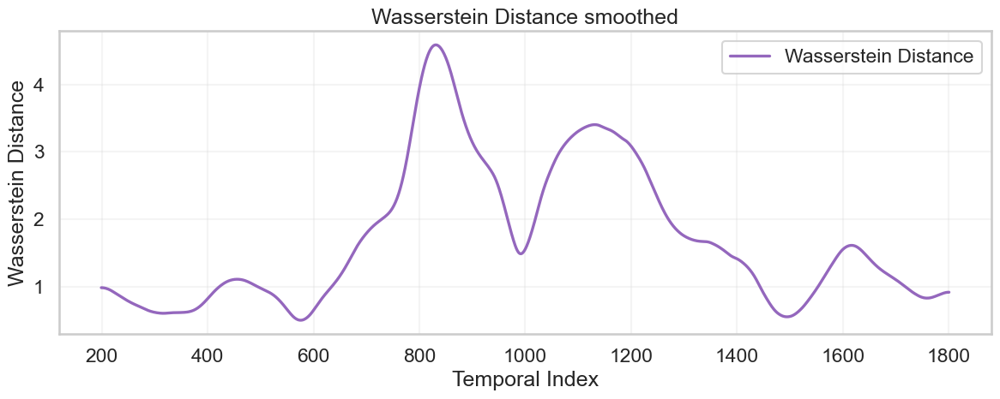

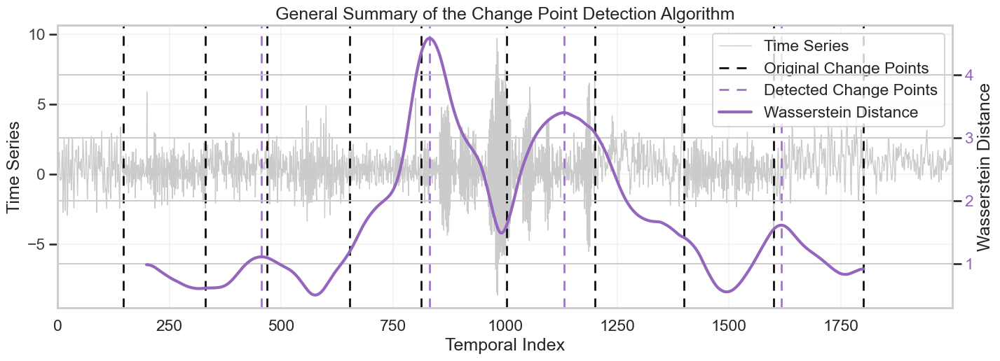


════════════════════════════════════════════════════════════════════════
                         Optimización Empírico                          
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 12.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 12.0000

Dispersion of Cost
──────────────────
    Execution Time              : 14.4417 s
    Best Window                 : 94

Dispersion of Cost
──────────────────
    Execution Time              : 14.4417 s
    Best Window                 : 94

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 94

Selección final
──────

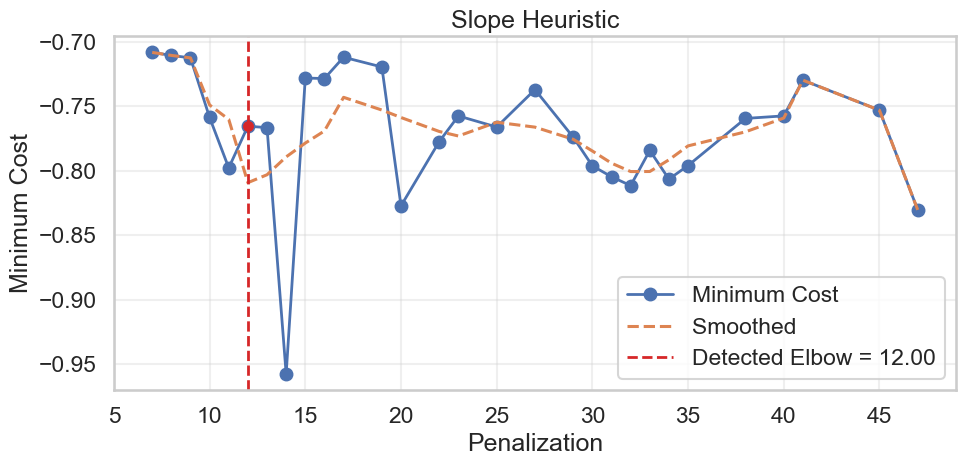

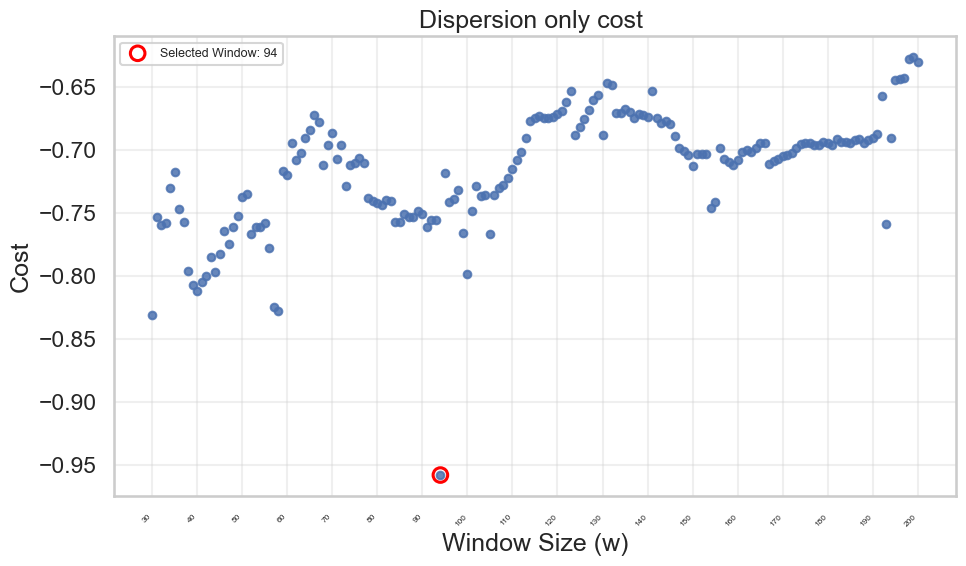

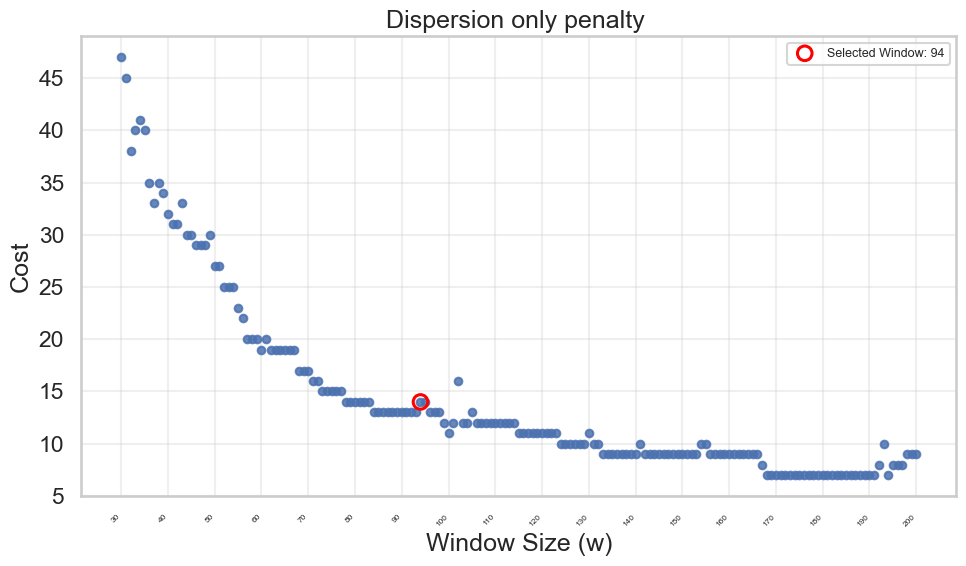

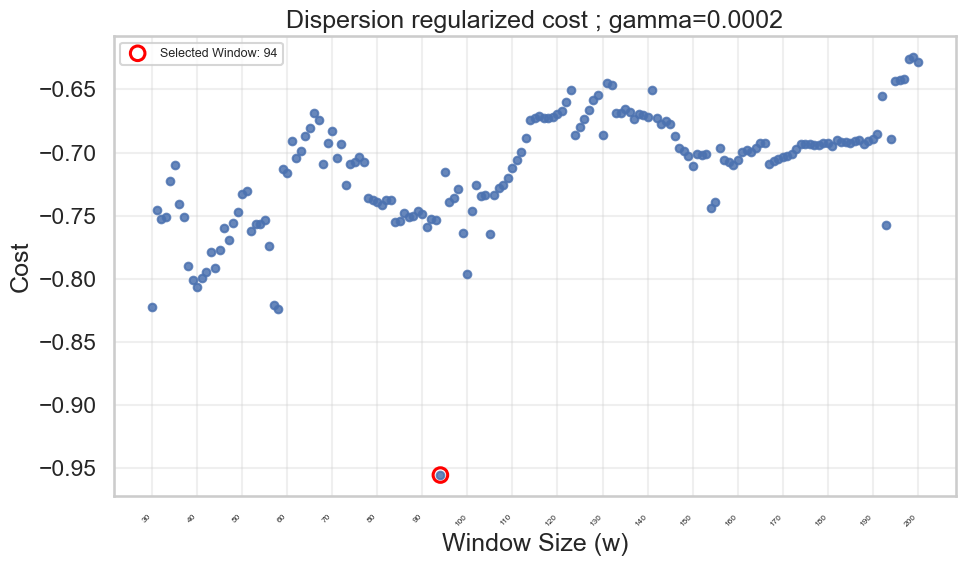

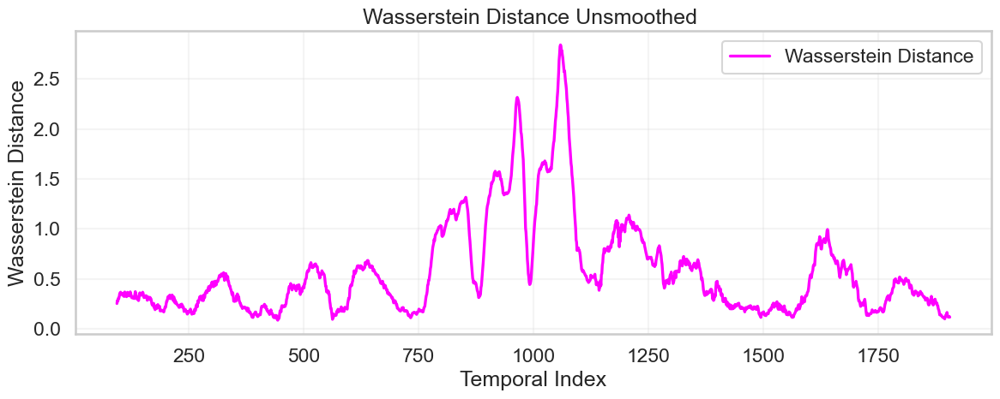

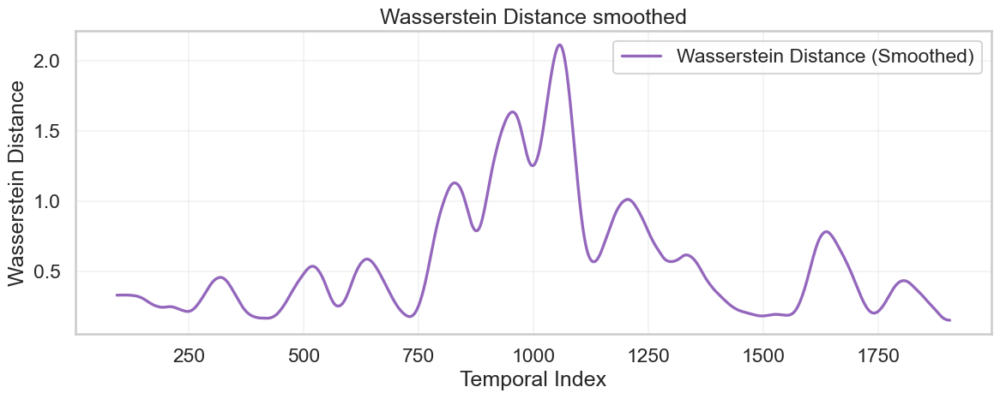

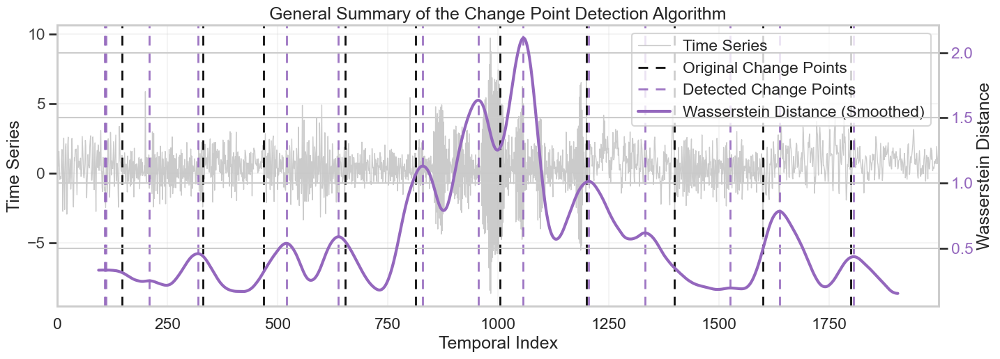

1

════════════════════════════════════════════════════════════════════════
                         Optimización Gaussiano                         
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 11.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 11.0000

Dispersion of Cost
──────────────────
    Execution Time              : 20.9330 s
    Best Window                 : 152

Dispersion of Cost
──────────────────
    Execution Time              : 20.9330 s
    Best Window                 : 152

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 152

Selección final
─

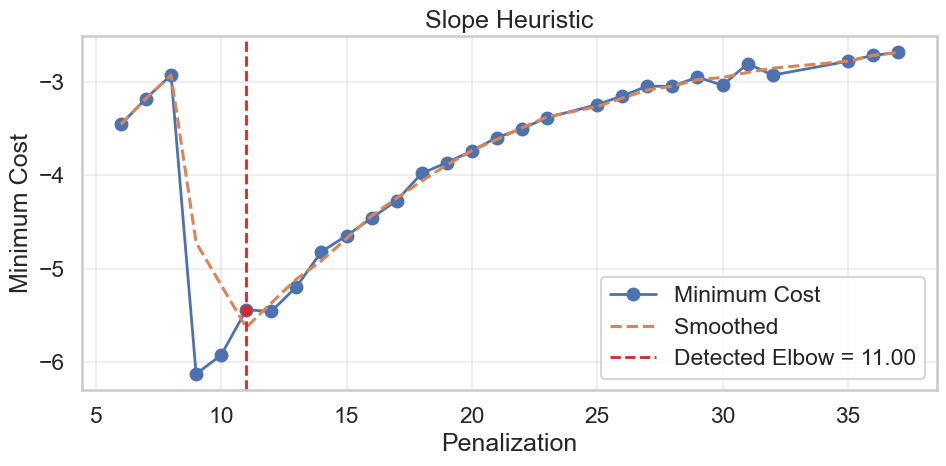

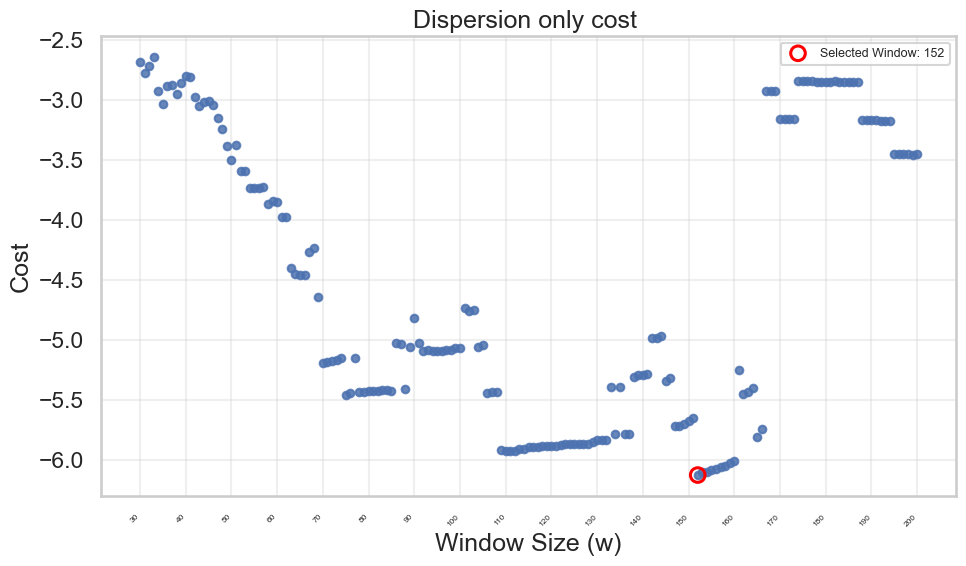

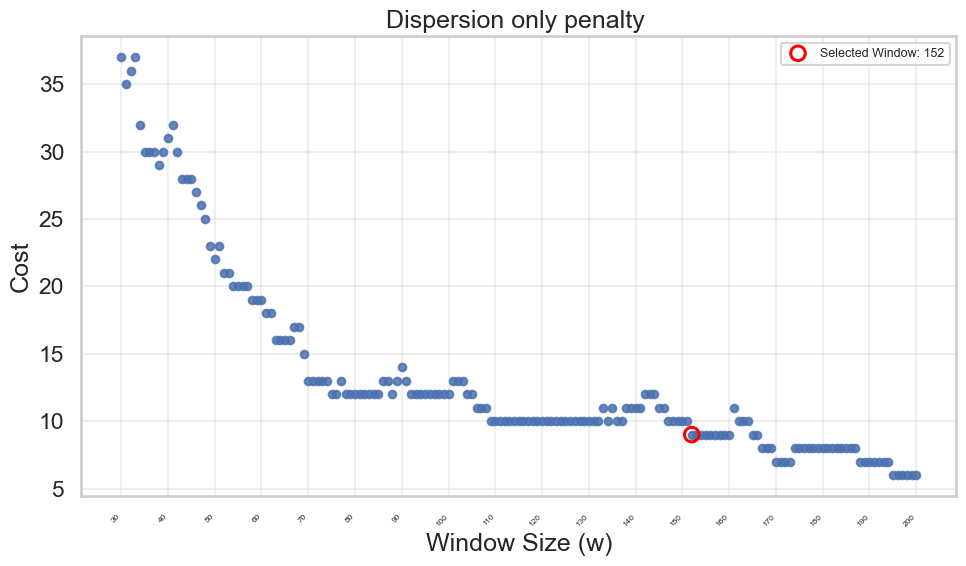

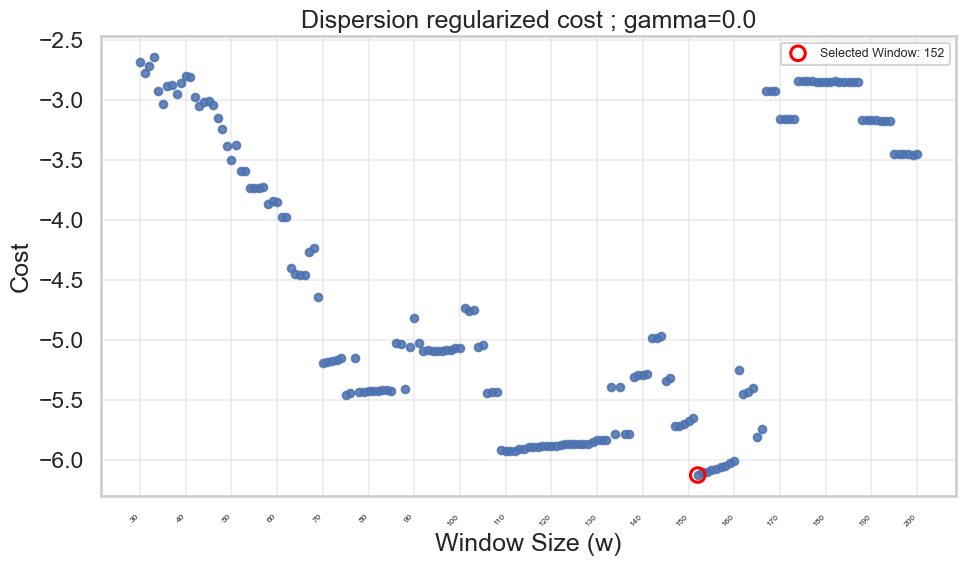

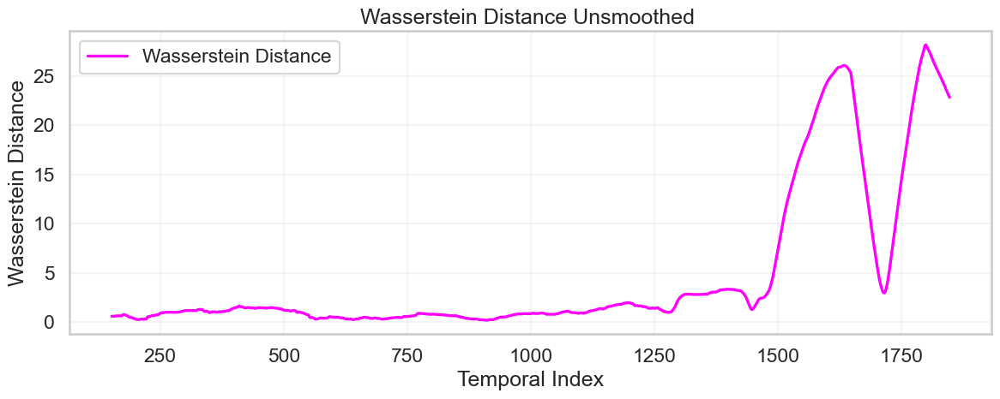

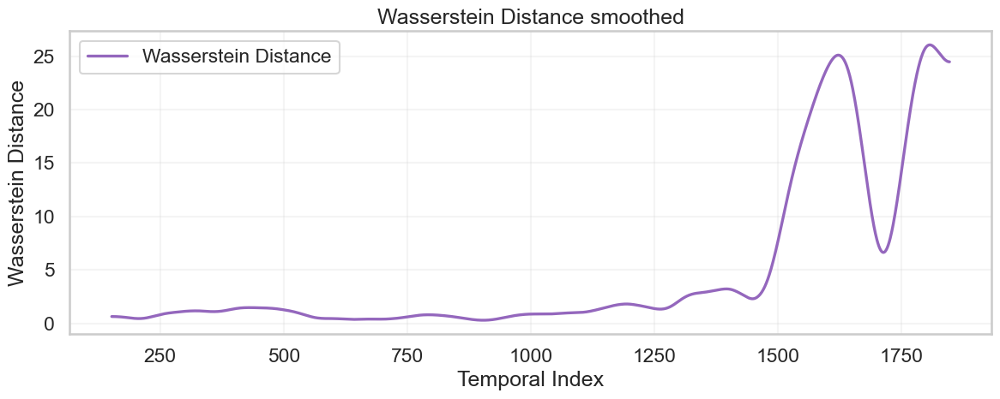

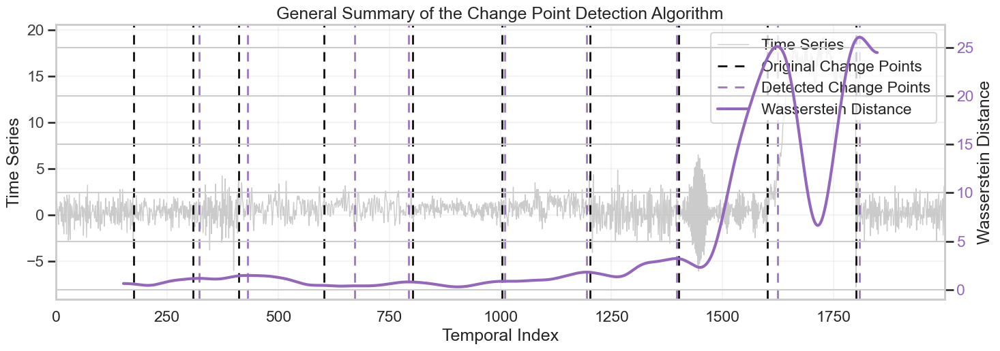


════════════════════════════════════════════════════════════════════════
                         Optimización Empírico                          
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 8.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 8.0000

Dispersion of Cost
──────────────────
    Execution Time              : 14.7524 s
    Best Window                 : 160

Dispersion of Cost
──────────────────
    Execution Time              : 14.7524 s
    Best Window                 : 160

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 160

Selección final
─────

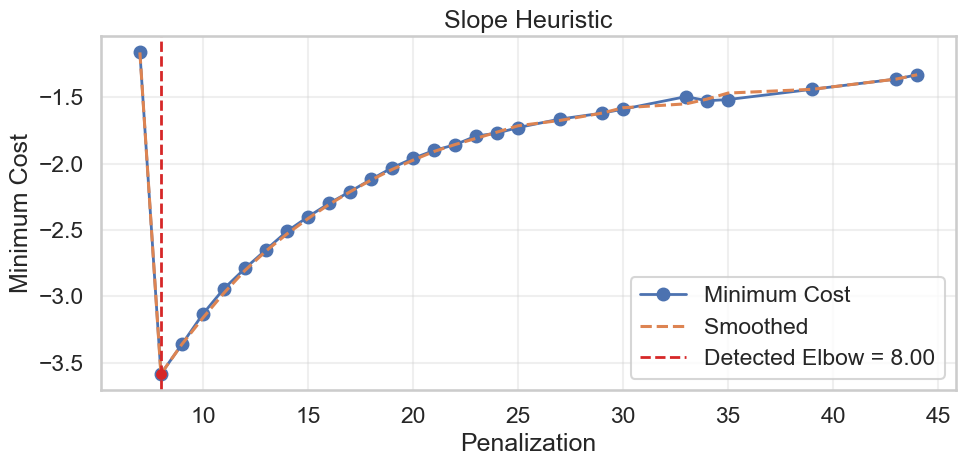

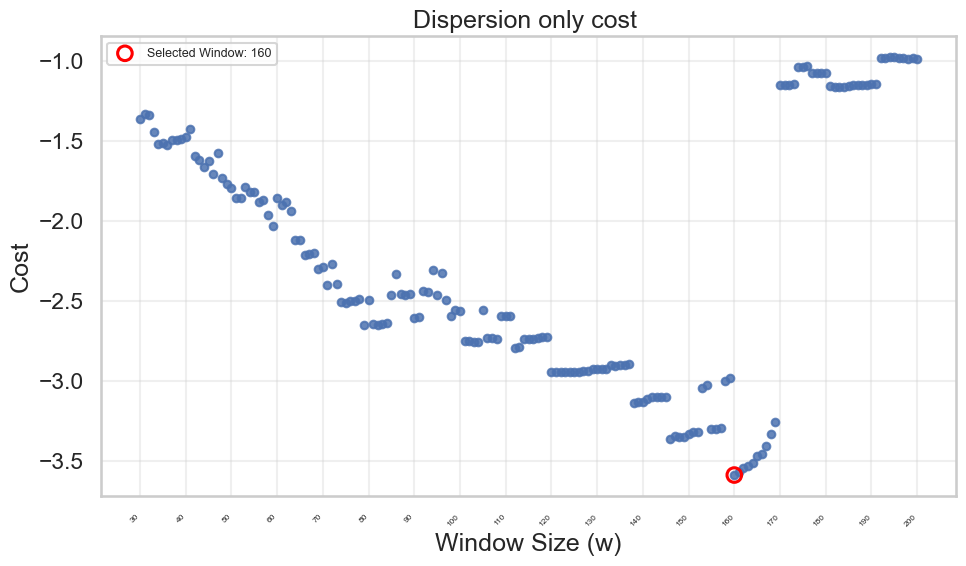

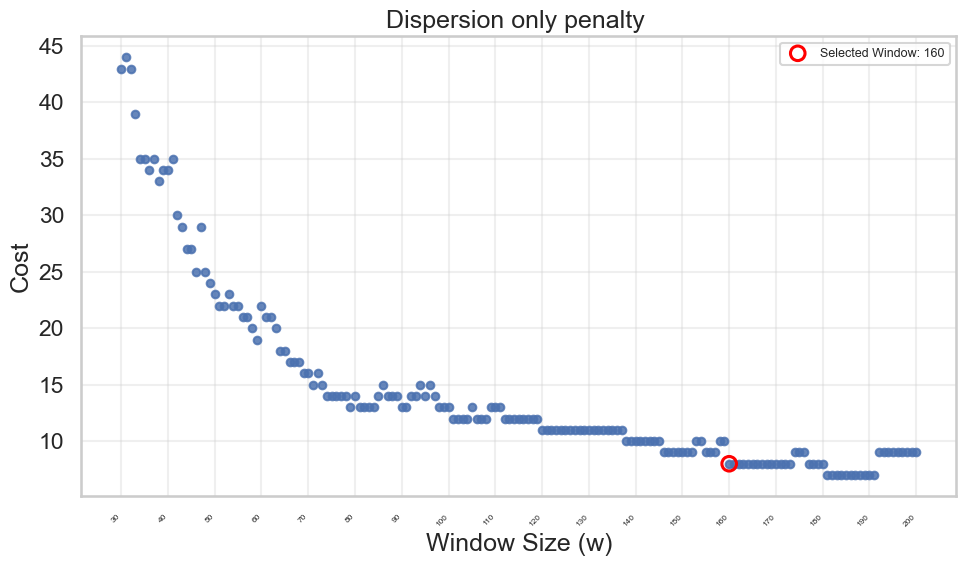

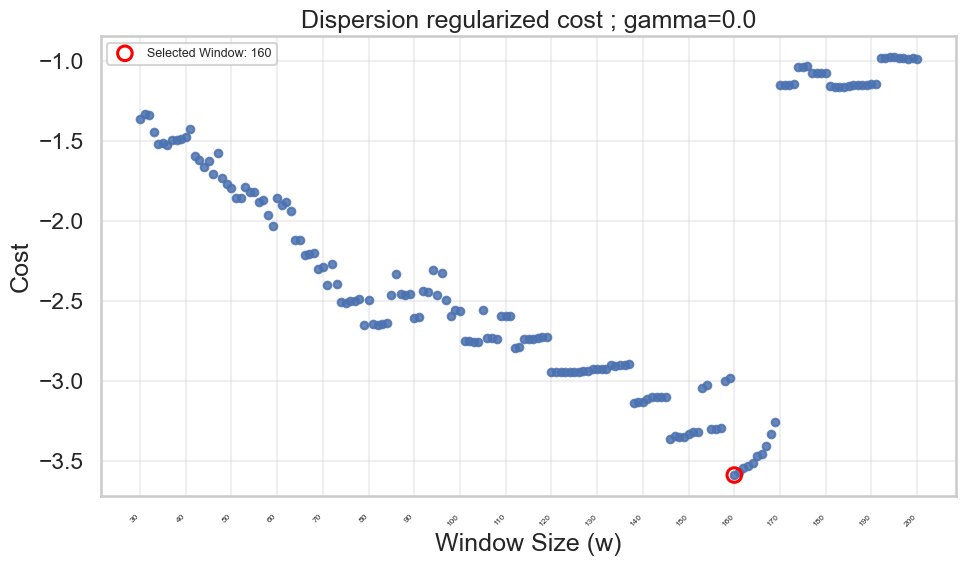

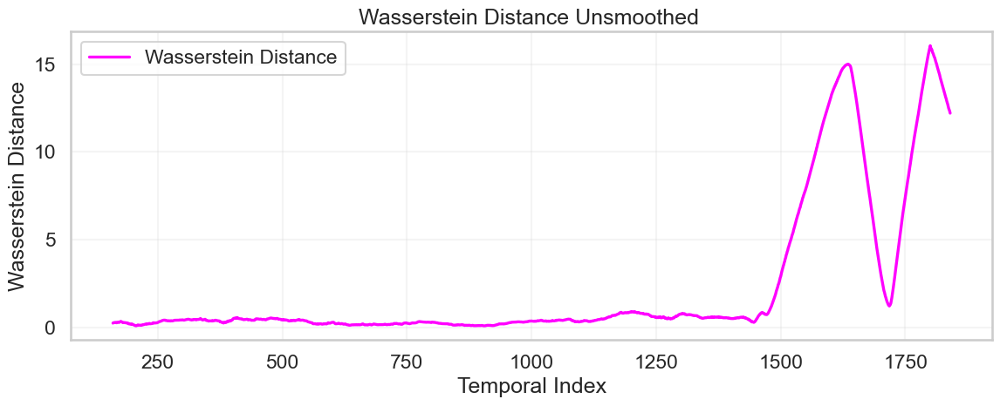

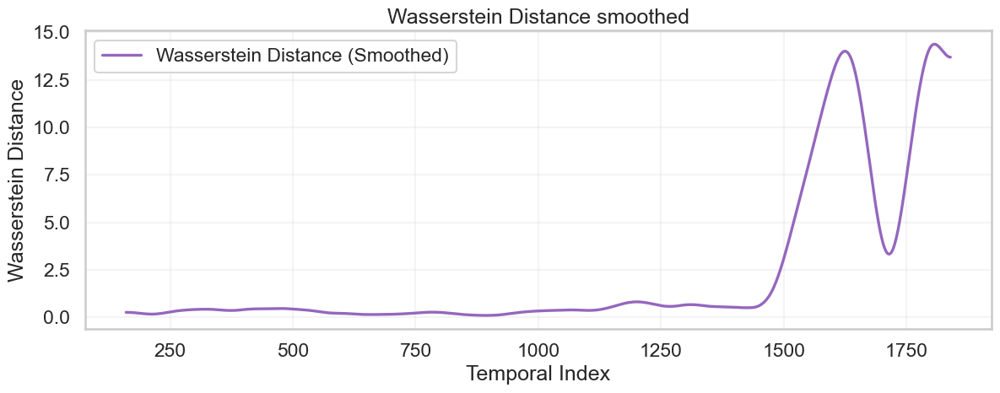

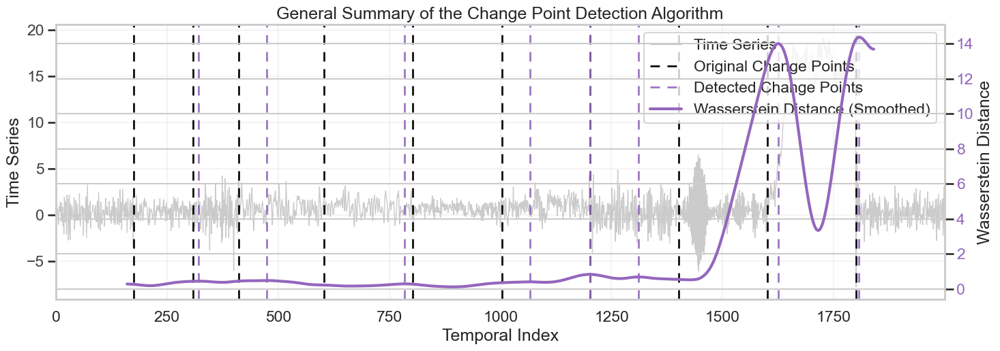

2

════════════════════════════════════════════════════════════════════════
                         Optimización Gaussiano                         
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 19.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 19.0000

Dispersion of Cost
──────────────────
    Execution Time              : 20.7162 s
    Best Window                 : 200

Dispersion of Cost
──────────────────
    Execution Time              : 20.7162 s
    Best Window                 : 200

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 200

Selección final
─

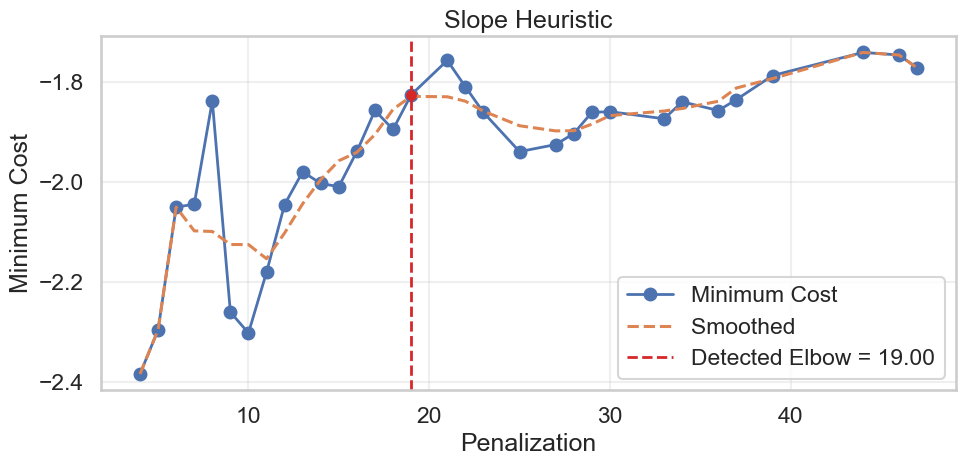

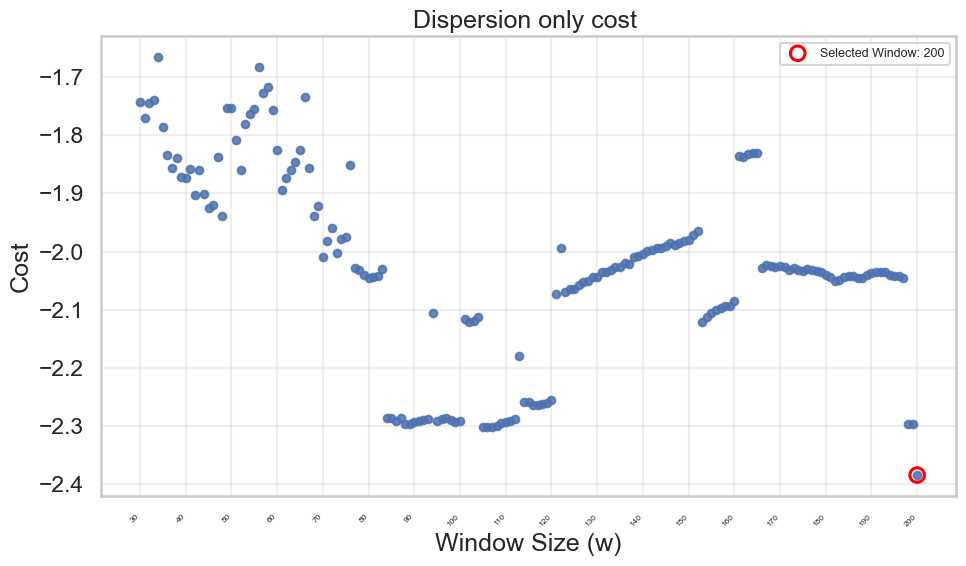

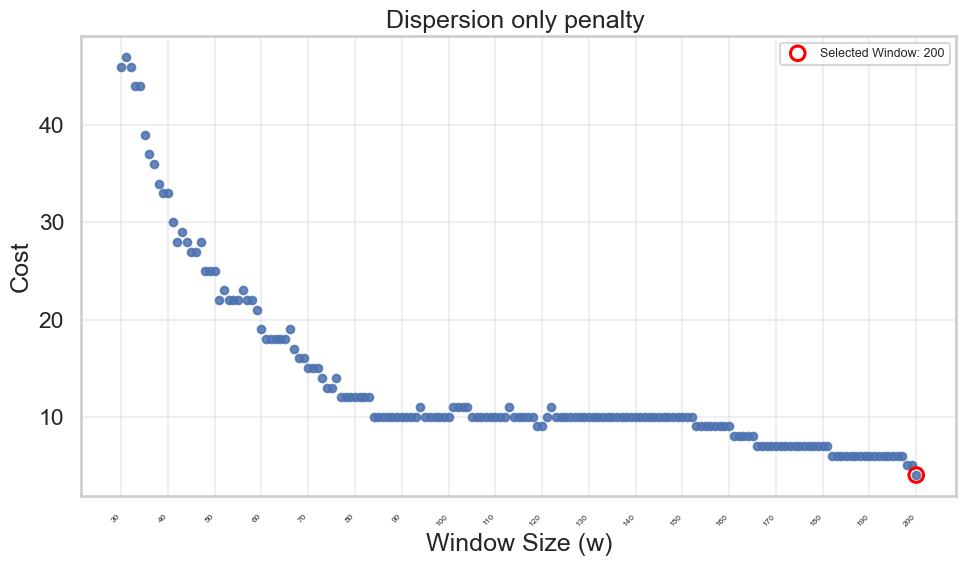

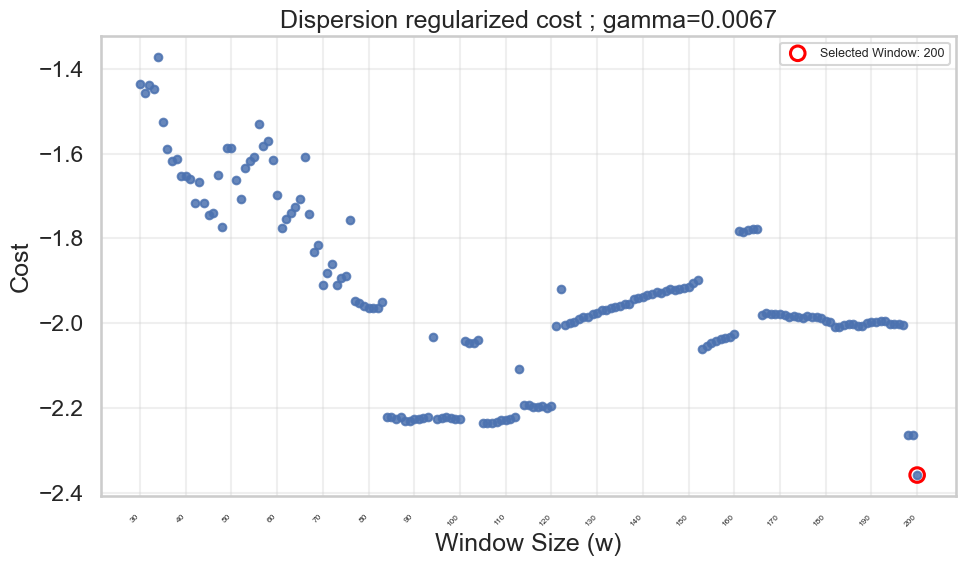

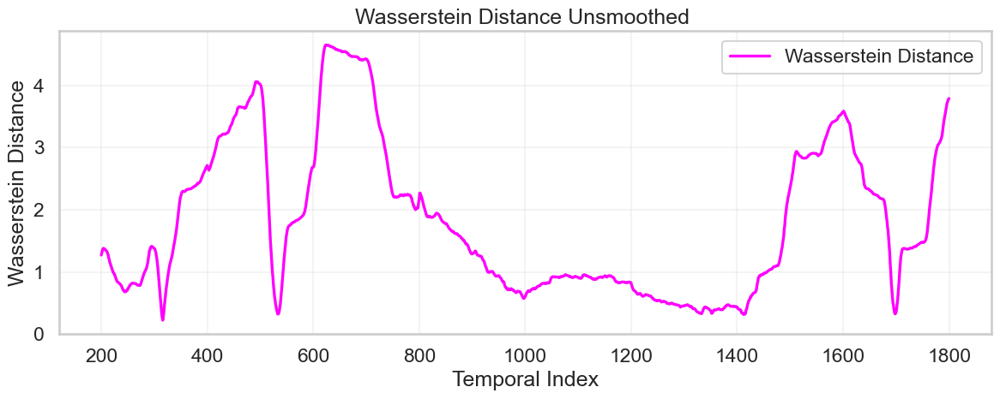

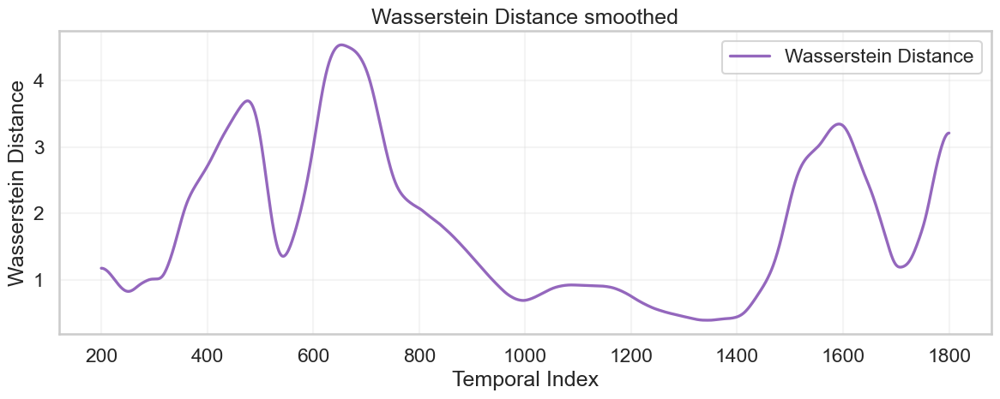

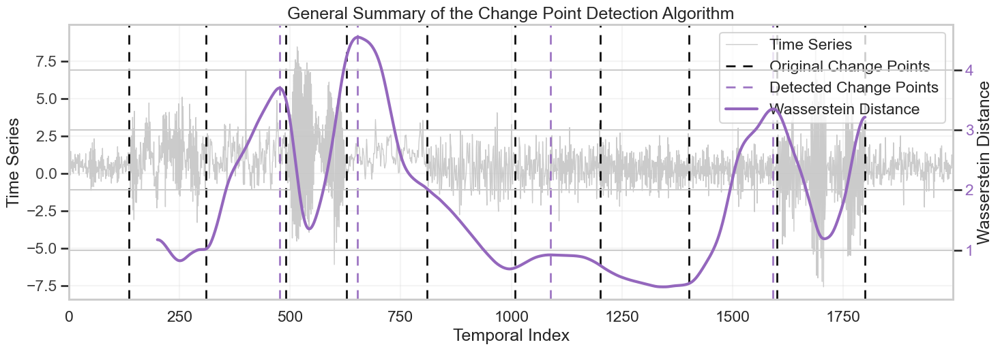


════════════════════════════════════════════════════════════════════════
                         Optimización Empírico                          
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 9.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 9.0000

Dispersion of Cost
──────────────────
    Execution Time              : 14.5713 s
    Best Window                 : 115

Dispersion of Cost
──────────────────
    Execution Time              : 14.5713 s
    Best Window                 : 115

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 115

Selección final
─────

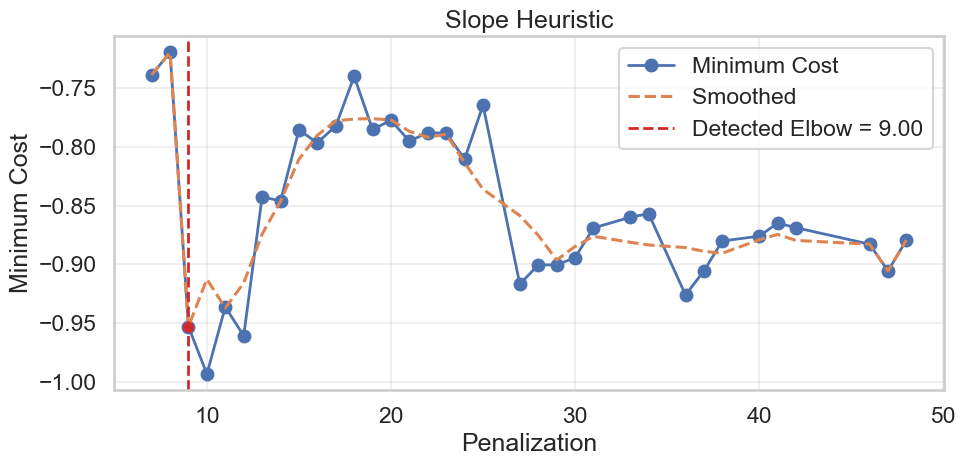

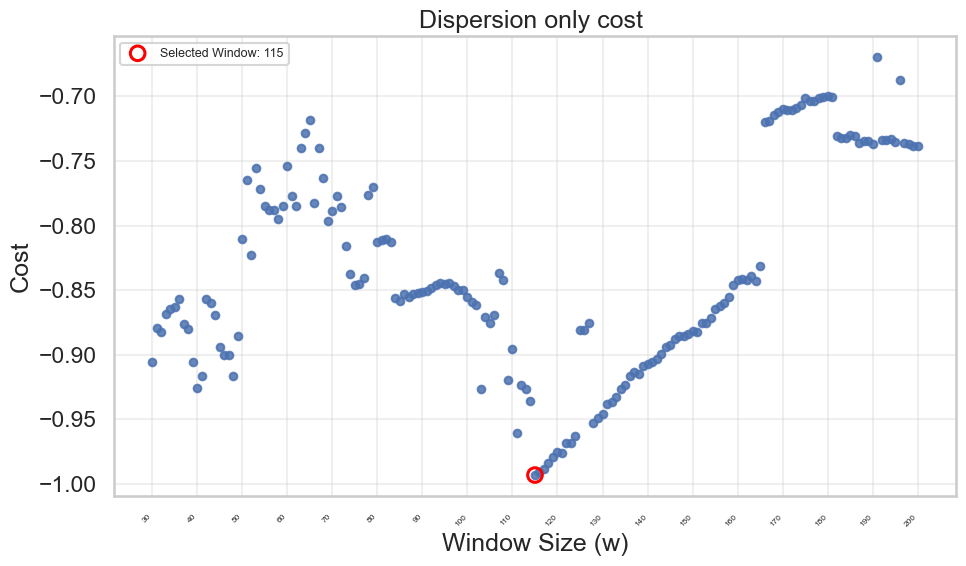

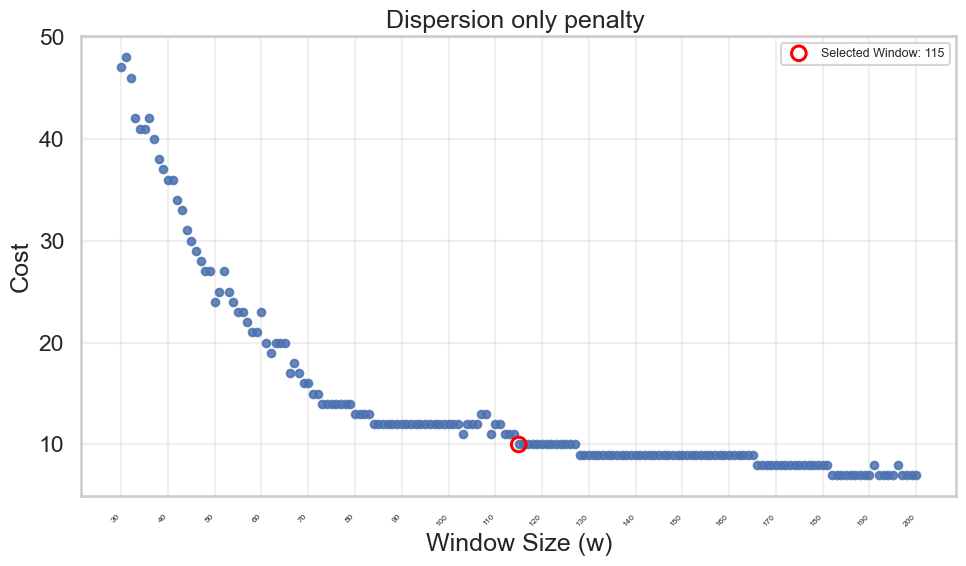

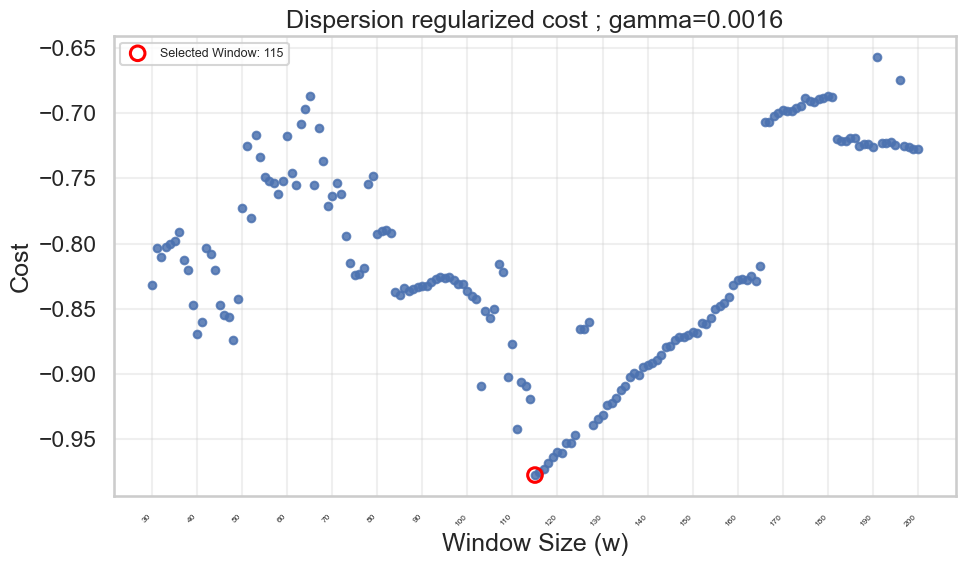

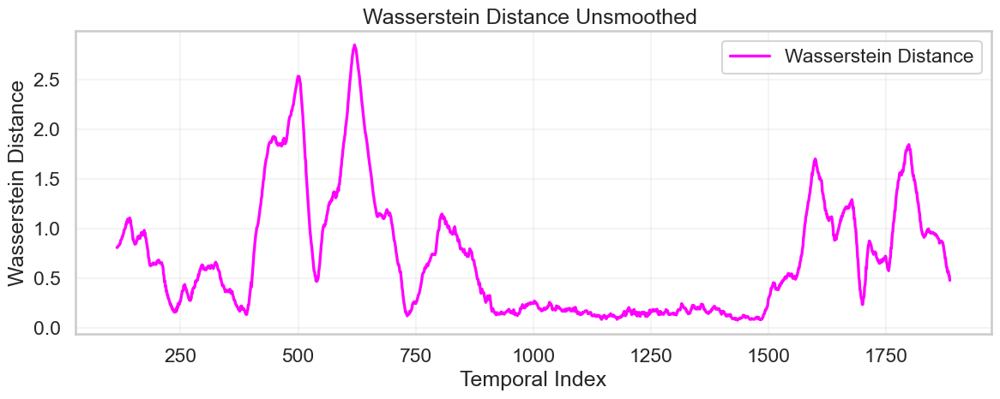

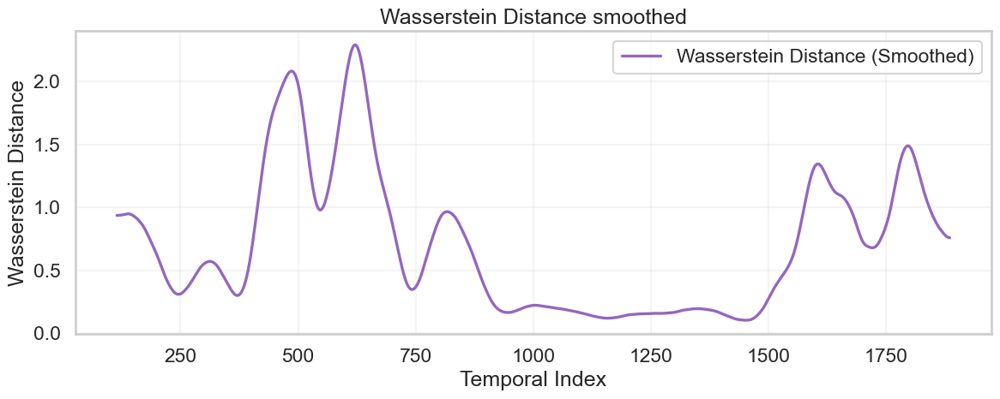

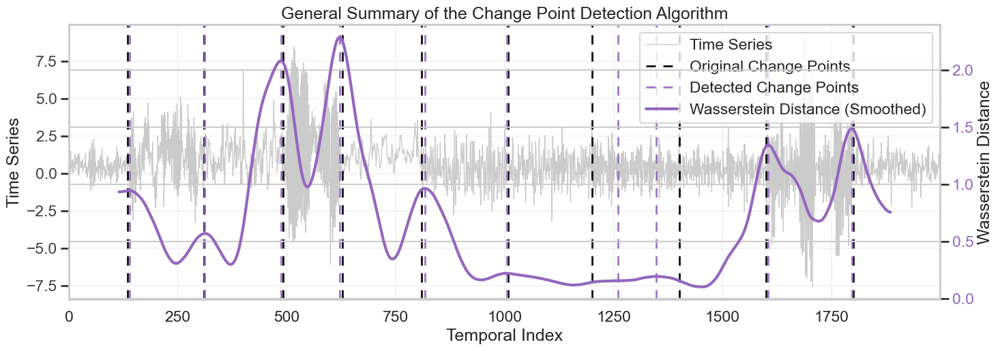

3

════════════════════════════════════════════════════════════════════════
                         Optimización Gaussiano                         
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 19.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 19.0000

Dispersion of Cost
──────────────────
    Execution Time              : 21.0190 s
    Best Window                 : 193

Dispersion of Cost
──────────────────
    Execution Time              : 21.0190 s
    Best Window                 : 193

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 193

Selección final
─

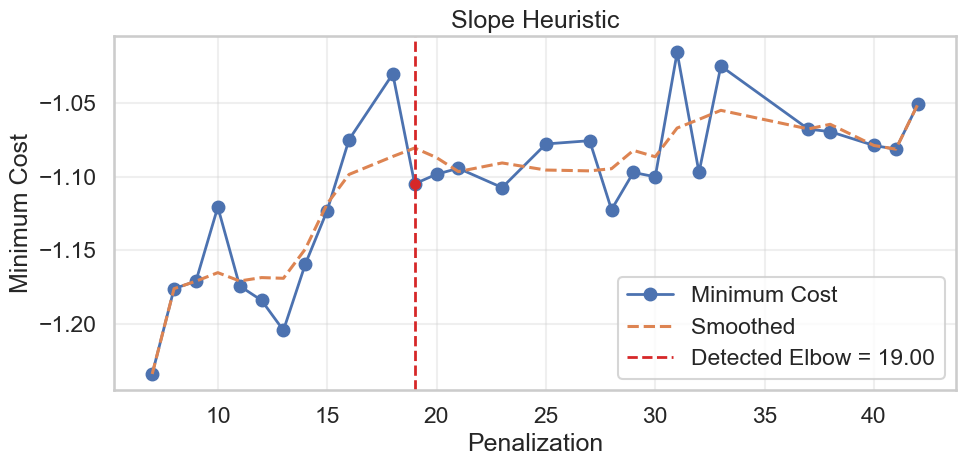

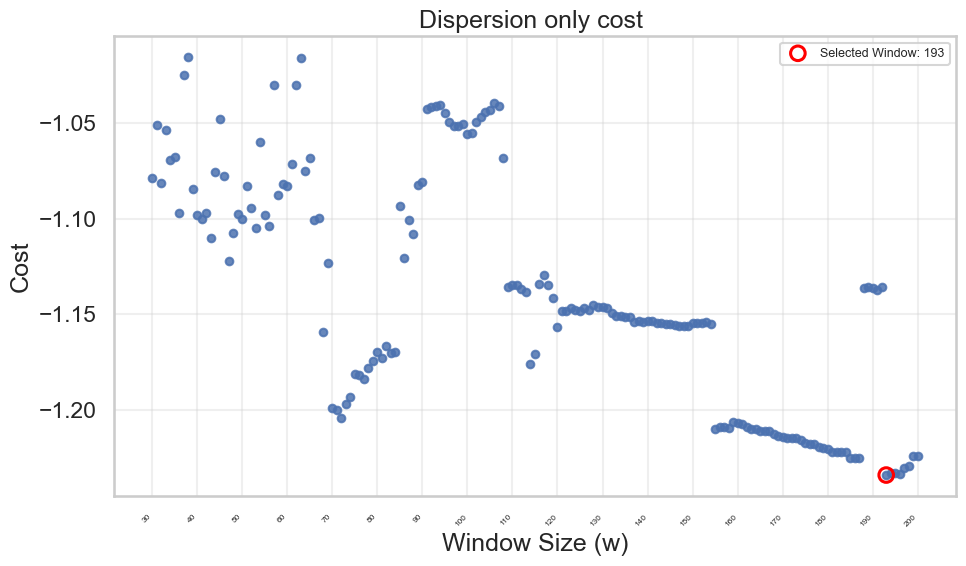

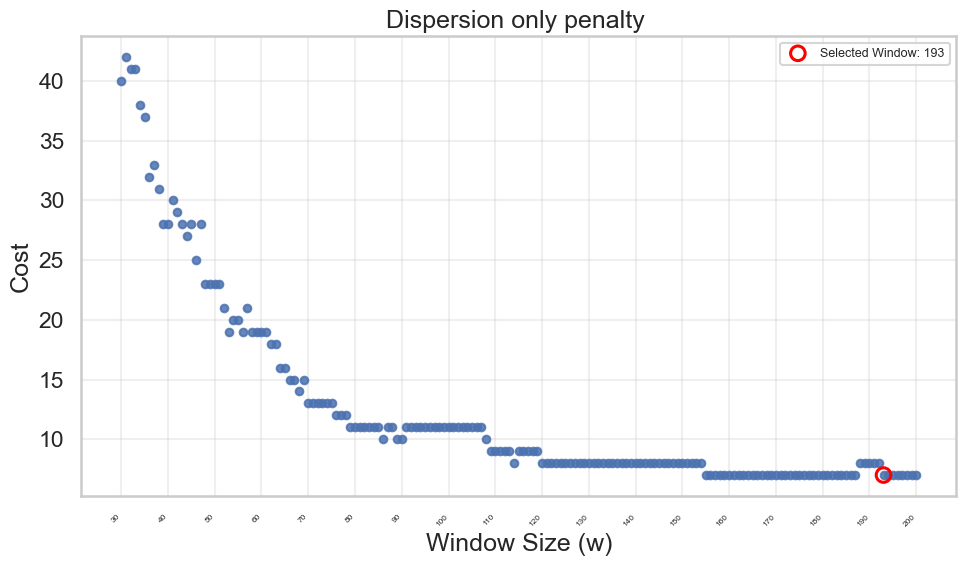

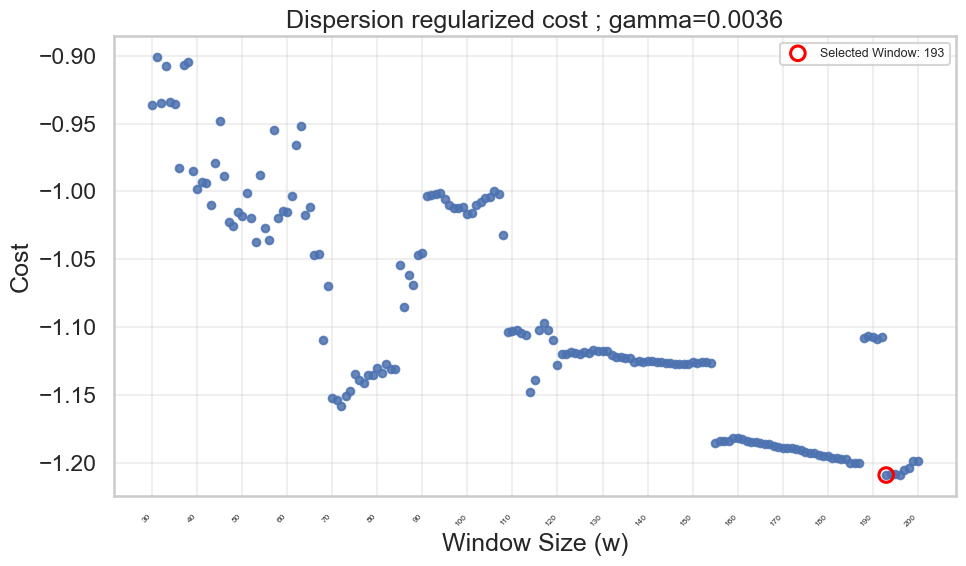

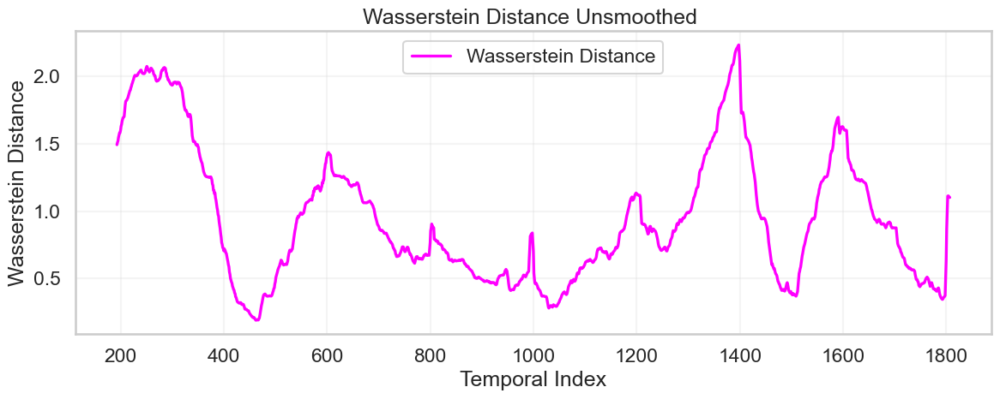

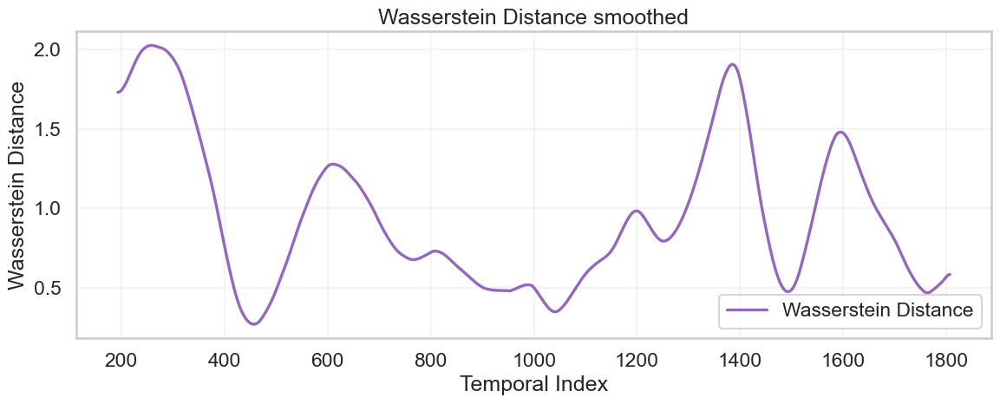

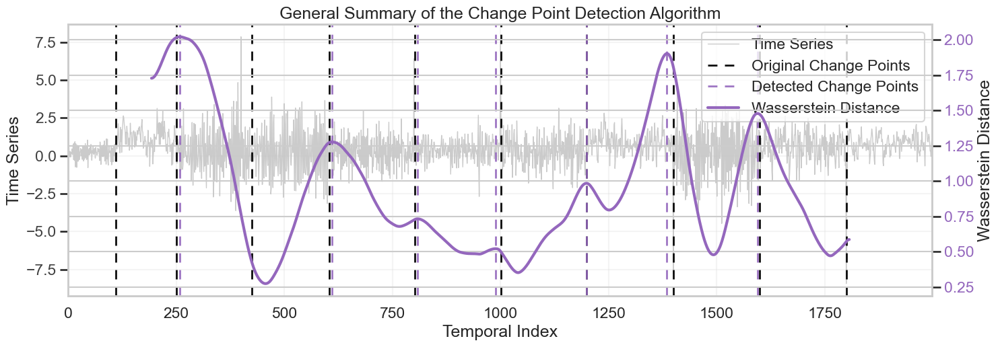


════════════════════════════════════════════════════════════════════════
                         Optimización Empírico                          
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 14.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 14.0000

Dispersion of Cost
──────────────────
    Execution Time              : 14.5377 s
    Best Window                 : 92

Dispersion of Cost
──────────────────
    Execution Time              : 14.5377 s
    Best Window                 : 92

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 92

Selección final
──────

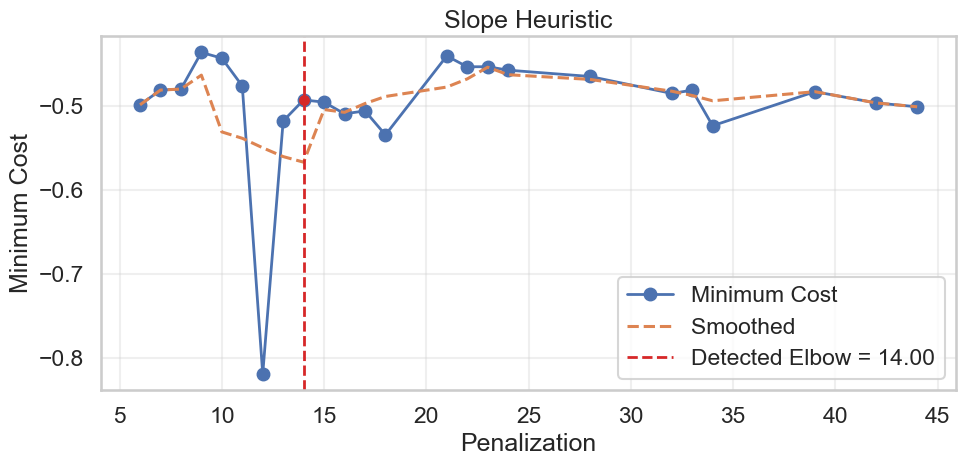

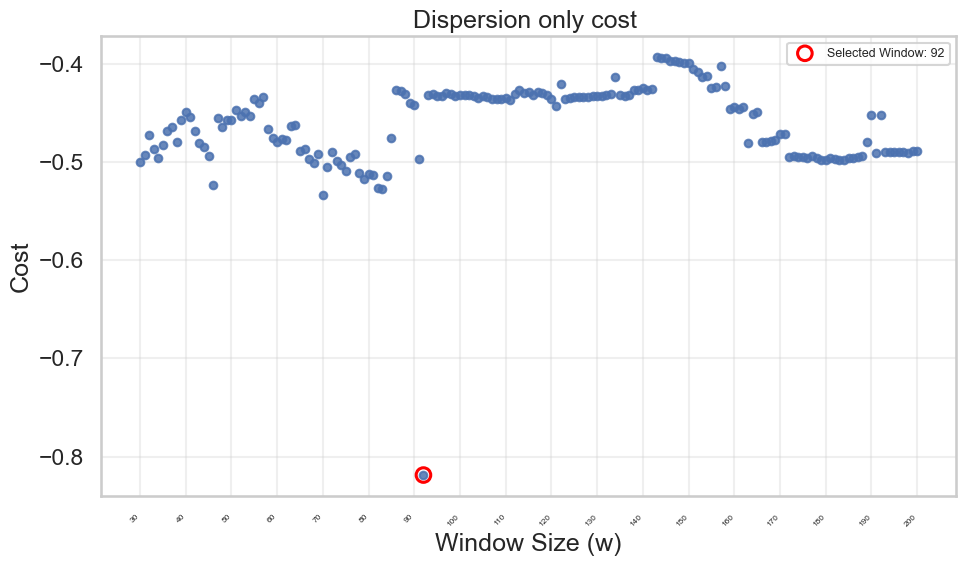

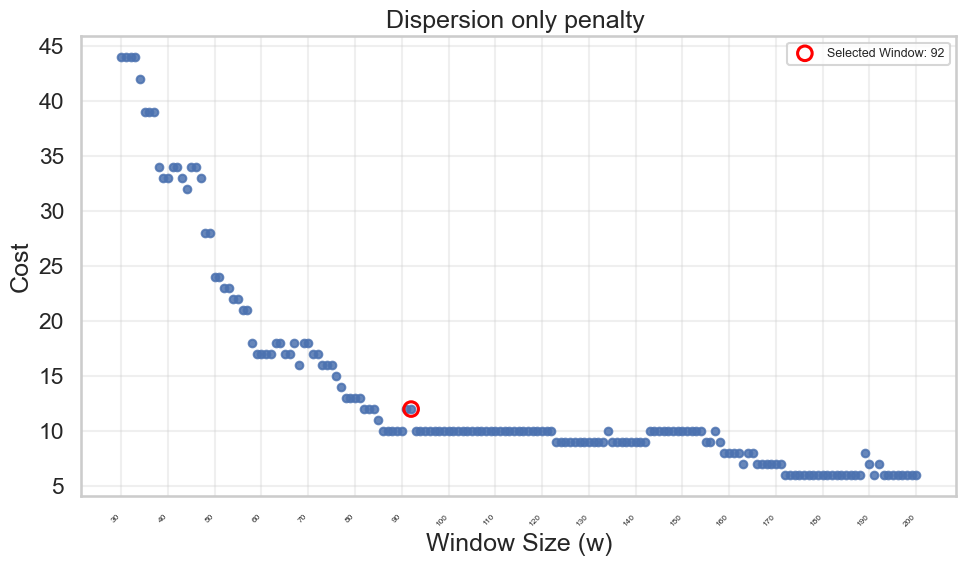

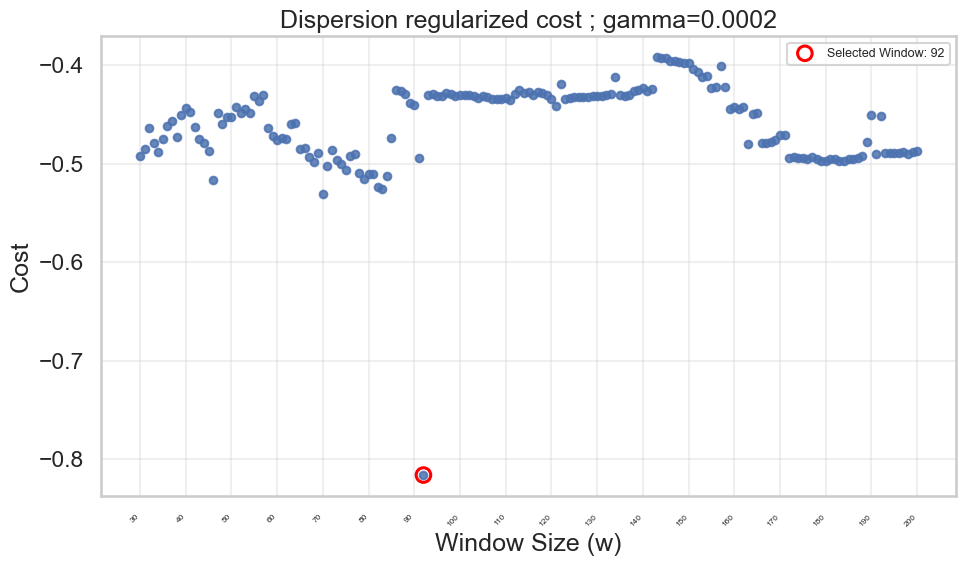

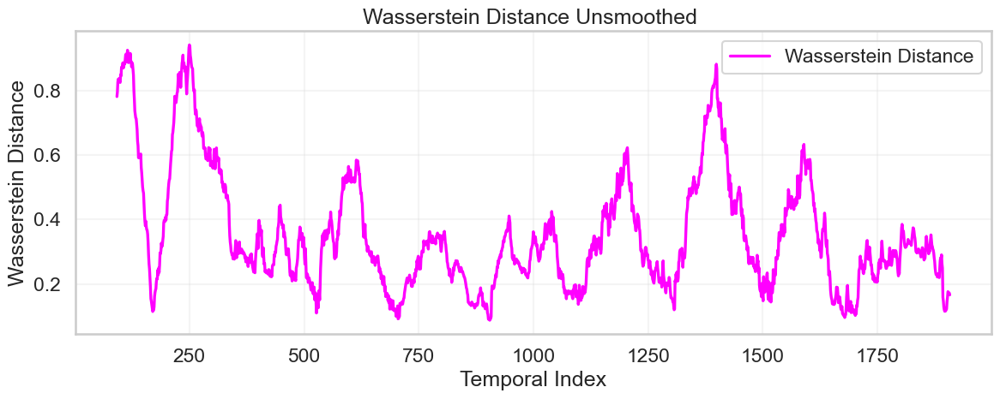

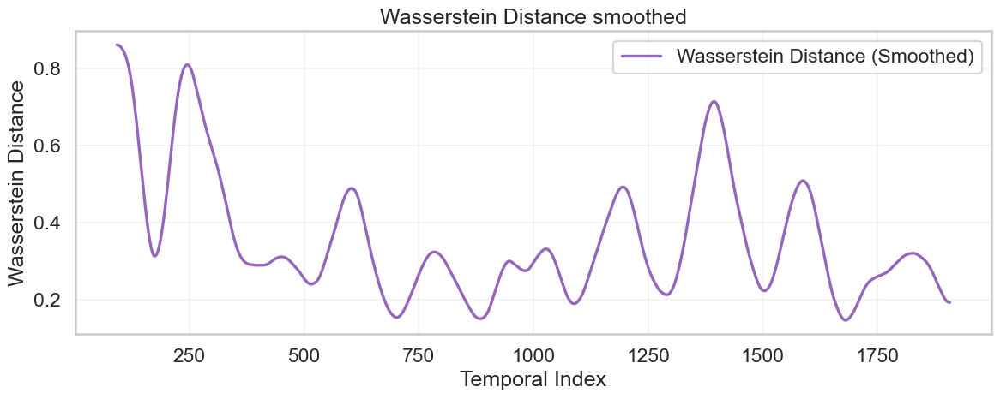

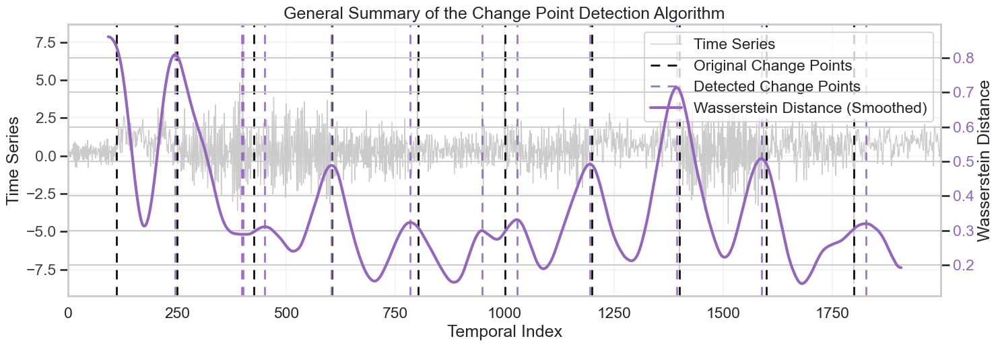

4

════════════════════════════════════════════════════════════════════════
                         Optimización Gaussiano                         
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 2000
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 11.0000

Selección final
───────────────
    Ventana óptima              : 130
    Retardo óptimo              : 1
    Penalización mínima         : 0
    Gamma final                 : 0.0000
    Tiempo de búsqueda          : 20.8230
    [OK] Optimización finalizada

════════════════════════════════════════════════════════════════════════
                         Optimización Empírico                          
════════════════════════════════════════════════════════════════════════
    Tamaño de serie      

In [23]:
metricas_ar2_rf_gauss_opt = []
metricas_ar2_rf_emp_opt = []



for i in range(200):
    print(i)
    ar2_rf, cps_ar2_rf, outliers_ar2_rf = ar2_noise(
                T = 2000,
                n_segmentos = 11,
                min_seg = 100,
                max_seg = 200,
                random_phi = True,
                base_mean = 0.5,
                random_mean = False,
                base_std = 0.5,
                random_std = True,
                std_range = (0.3, 1.2),
                seed = 1234+i
            )

    if i <= 3:
        visualization={
                                                                            "summary": True,
                                                                            "raw_distance": True,
                                                                            "smooth_distance": True,
                                                                            "cost": True,
                                                                            "slope": True,
                                                                        }
    else:
        visualization={
                                                                            "summary": False,
                                                                            "raw_distance": False,
                                                                            "smooth_distance": False,
                                                                            "cost": False,
                                                                            "slope": False,
                                                                        }
    
    metricas_ar2_rf_gauss_opt.append(
                                            best_params_sh(
                                                                ar2_rf,
                                                                cps_ar2_rf,
                                                                penal=True,
                                                                path='',
                                                                mean_gauss=True,
                                                                name=f"AR2_{i+1} Rezagos Fluctuantes",
                                                                modo="Gaussiano",
                                                                given=False,
                                                                thr_dist=20,
                                                                min_w = 30,
                                                                max_w = 200,
                                                                t_given=1,
                                                                smooth_distances=True,
                                                                visualization=visualization,
                                                                save_fig=False,
                                                                temporal_comp=True,
                                                                max_bandwidth=True,
                                                                prominence_ratio=0)[0]
                                        )
    

    metricas_ar2_rf_emp_opt.append(
                                        best_params_sh(
                                                            ar2_rf,
                                                            cps_ar2_rf,
                                                            penal=True,
                                                            path='',
                                                            name=f"AR2_{i+1} Rezagos Fluctuantes",
                                                            modo="Empírico",
                                                            given=False,
                                                            thr_dist=20,
                                                            min_w = 30,
                                                            max_w = 200,
                                                            smooth_distances=True,
                                                            visualization=visualization,
                                                            save_fig=False,
                                                            temporal_comp=True,
                                                            max_bandwidth=True, 
                                                            prominence_ratio=0)[0]
        )


### 2.5.2. Gráficas y Resultados Promedio

In [18]:
lists_metrics_ar2_rf = []
windows = [30, 50, 80, 100]
prominence_ratio = 0.05
for w in windows:
    print(f'WINDOW SIZE: {w}')
    if w >= 80:
        prominence_ratio=0
    lists_metrics_ar2_rf.append(experiment_ar2_rf_temporal_dependence(w=w, delta=20, prominence_ratio=prominence_ratio))

WINDOW SIZE: 30
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
WINDOW SIZE: 50
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95


In [ ]:
for metricas, w in zip(lists_metrics_ar2_rf, windows):
    exportar_excel(metricas, f"Resultados_Series_Simuladas/AR(2)_Altering_auto-correlation/Tables/ar2_rf_metrics_window_{w}.xlsx", ["Gauss", "Empirical", "Roerich-KL", "Window-RBF"])

WINDOW SIZE: 30


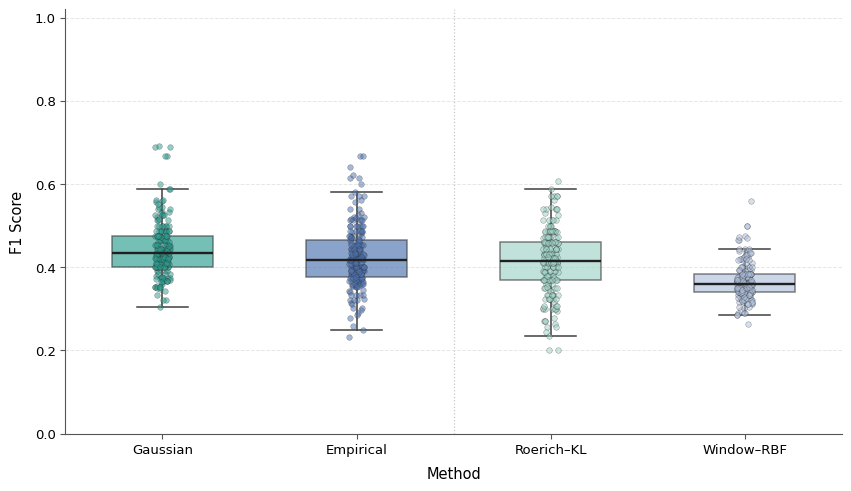

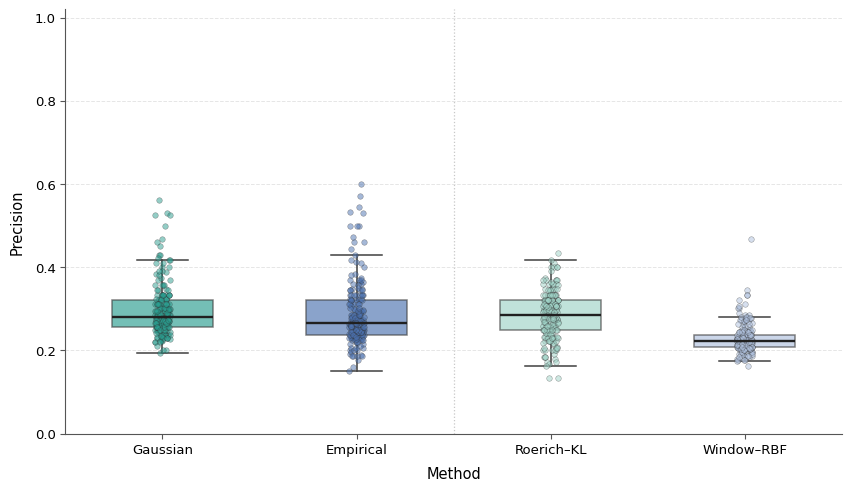

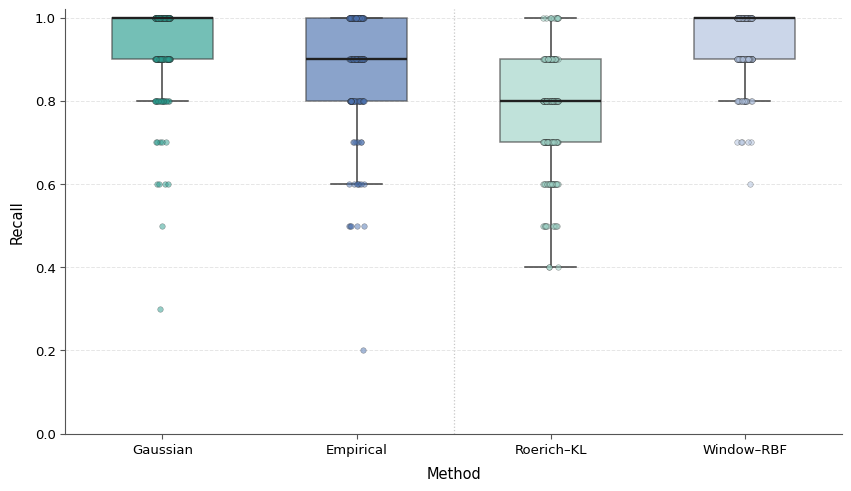

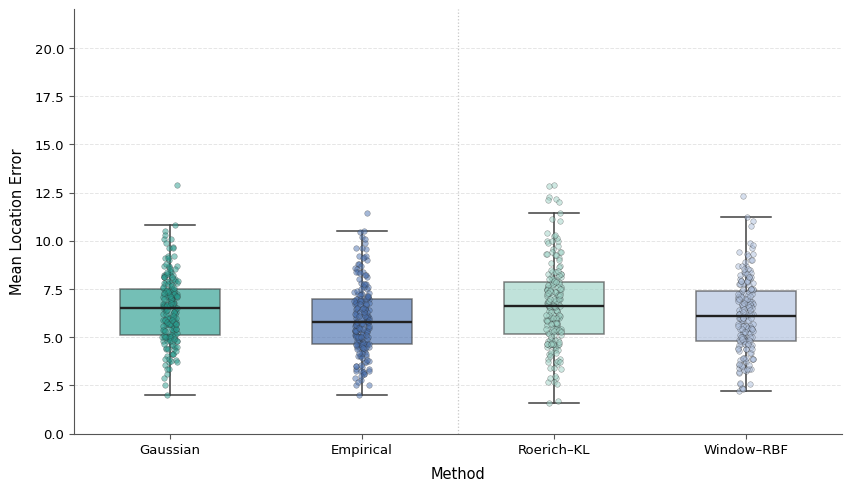

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.297659,0.9270,0.445075,6.467173
1,Empirical,0.286203,0.8935,0.424406,5.925244
2,Roerich-KL,0.285099,0.7625,0.414427,6.657536
3,Window-RBF,0.228630,0.9395,0.365941,6.101284


WINDOW SIZE: 50


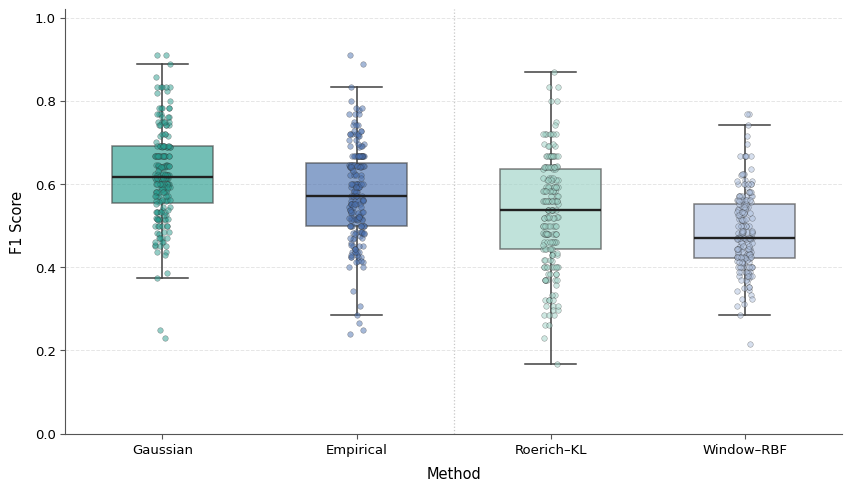

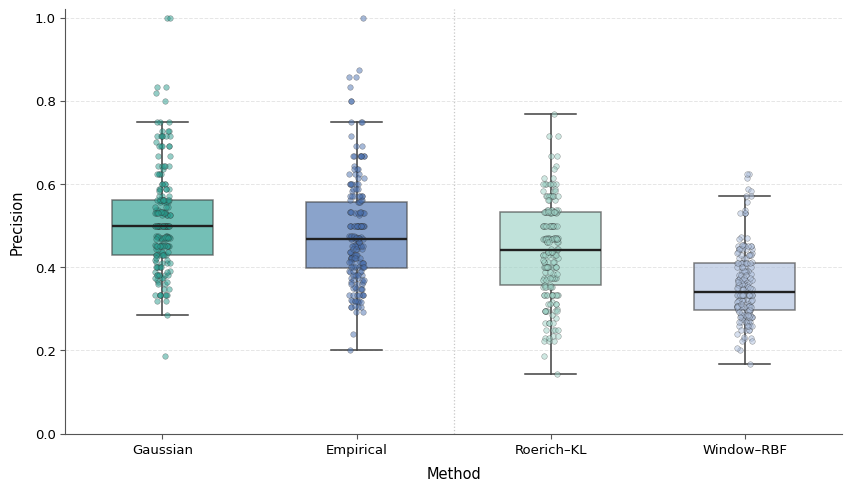

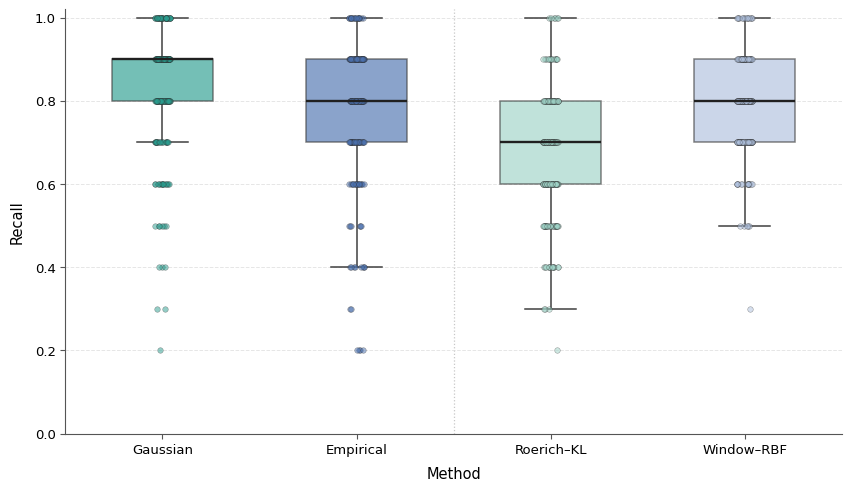

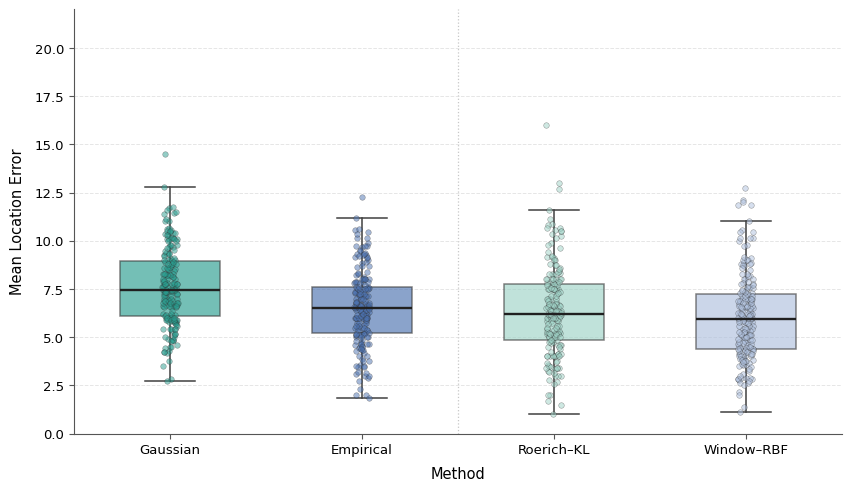

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.513904,0.8255,0.621198,7.614544
1,Empirical,0.482782,0.7700,0.575484,6.515788
2,Roerich-KL,0.440106,0.6685,0.529408,6.374756
3,Window-RBF,0.356367,0.7865,0.486858,6.025946


WINDOW SIZE: 80


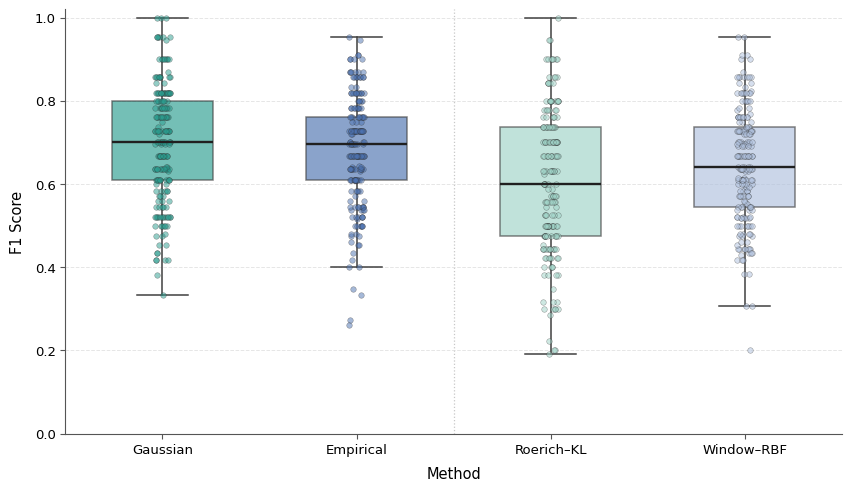

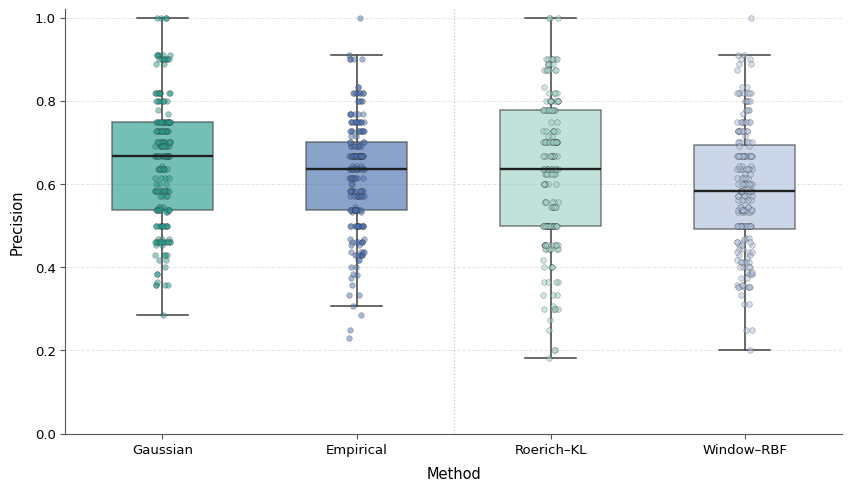

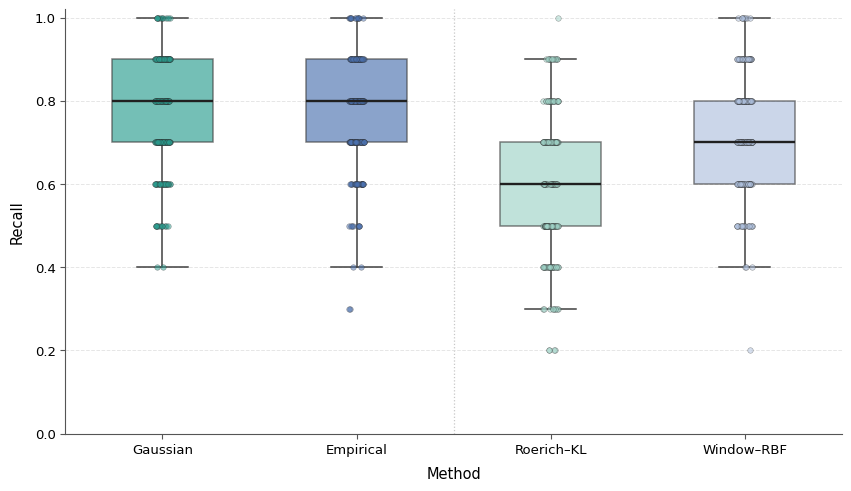

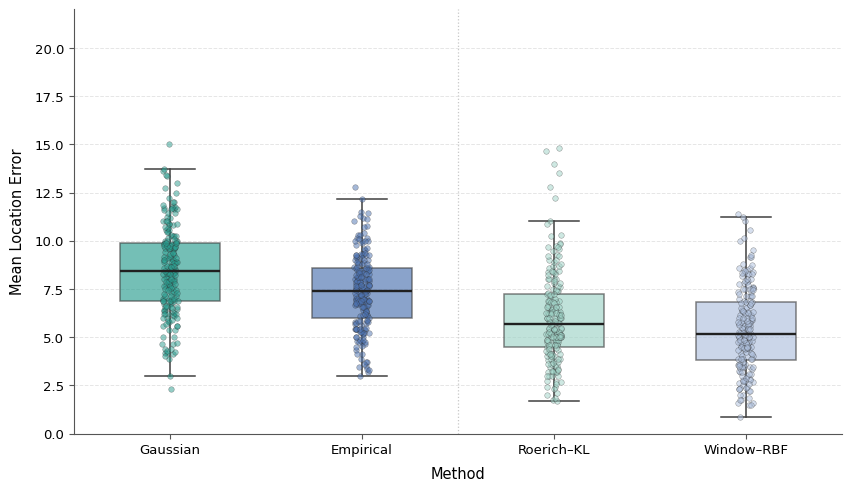

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.650615,0.7595,0.698393,8.427278
1,Empirical,0.616209,0.7595,0.677956,7.350155
2,Roerich-KL,0.618882,0.5970,0.605800,6.005181
3,Window-RBF,0.586421,0.7270,0.643649,5.379992


WINDOW SIZE: 100


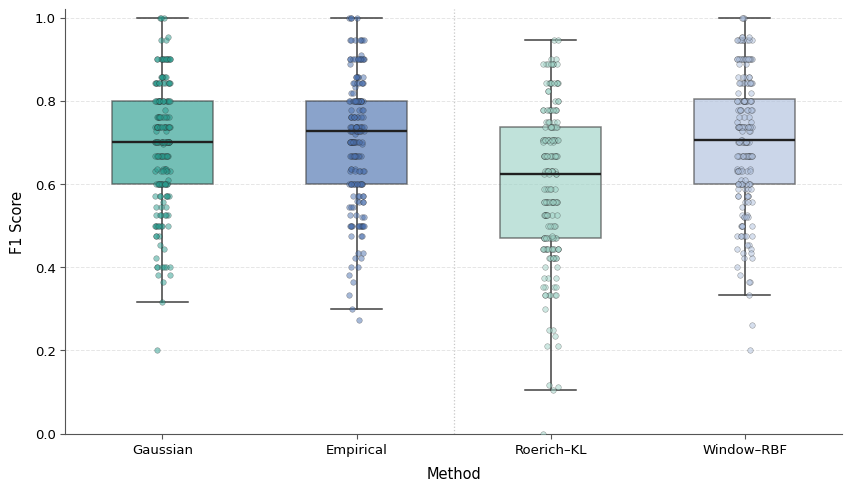

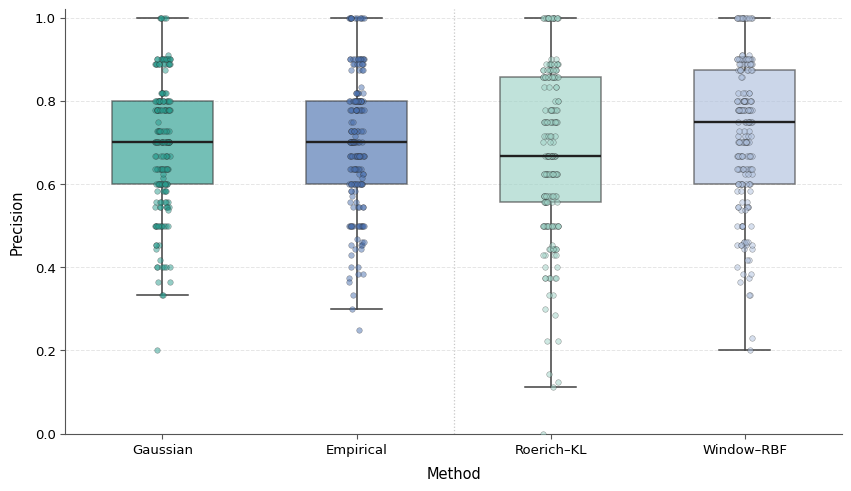

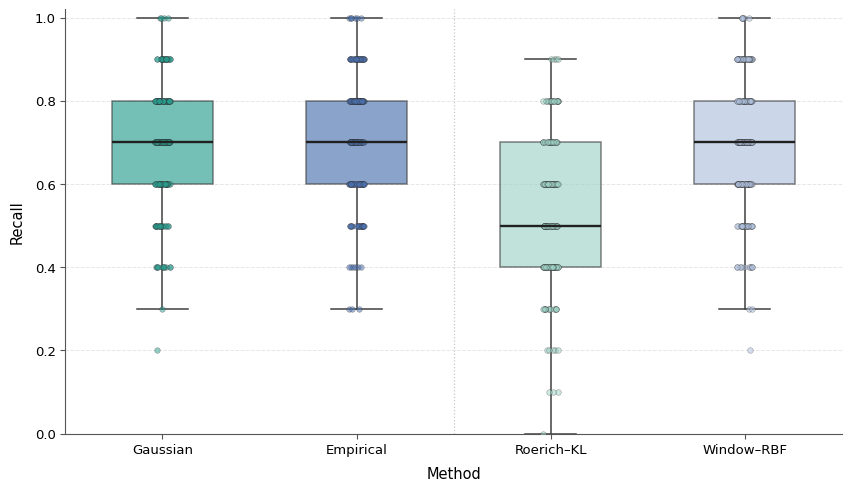

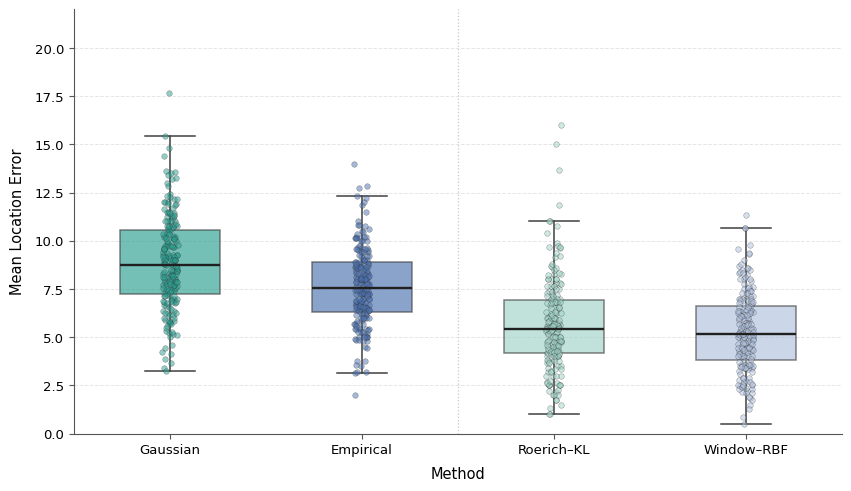

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.693070,0.6955,0.692905,8.853409
1,Empirical,0.698764,0.7125,0.703157,7.609617
2,Roerich-KL,0.678638,0.5390,0.597964,5.642739
3,Window-RBF,0.720758,0.6945,0.703738,5.271401


In [48]:
for w in [30, 50, 80, 100]:
    print("=" * 60)
    print(f"WINDOW SIZE: {w}")
    print("=" * 60)
    ruta_ar2_rf = f"Resultados_Series_Simuladas/AR(2)_Altering_auto-correlation/Tables/ar2_rf_metrics_window_{w}.xlsx"

    hojas = pd.read_excel(ruta_ar2_rf, sheet_name=None)

    listas = [df.to_dict(orient="records") for df in hojas.values()]

    lista_gauss, lista_emp, lista_roerich, lista_window_rbf = listas

    nombres_boxplot = [
                        "Gaussian",
                        "Empirical",
                        "Roerich–KL",
                        "Window–RBF"
                    ]

    metrics_names = ['F1 Score', 'Precision', 'Recall', 'Mean Location Error']
    for n in metrics_names:
        ylim = (0, 1.02)
        name = n
        if n == 'Mean Location Error':
            ylim = (0, 22)
            name = "MLE"
        path_fig = f"Resultados_Series_Simuladas/AR(2)_Altering_auto-correlation/Graphics/Window {w}/{name}_AR2_rf_w{w}.png"
        fig, ax = plot_boxplots(
                                datos=[
                                    [m[n] for m in lista_gauss],
                                    [m[n] for m in lista_emp],
                                    [m[n] for m in lista_roerich],
                                    [m[n] for m in lista_window_rbf]
                                ],
                                nombres=nombres_boxplot,
                                ylabel=n,
                                xlabel="Method",
                                ylim=ylim,
                                save_path = path_fig
                            )
    ruta_avg_ar2_rf = f"Resultados_Series_Simuladas/AR(2)_Altering_auto-correlation/Tables/ar2_rf_metrics_avg_window_{w}.xlsx"
    average_table = generar_tabla_desde_diccionarios(
                                                            [lista_gauss, lista_emp, lista_roerich, lista_window_rbf],
                                                            ["Gauss", "Empirical", "Roerich-KL", "Window-RBF"],
                                                            ["Precision", "Recall", "F1 Score", "Mean Location Error"]
                                                            )
    display(average_table)
    average_table.to_excel(ruta_avg_ar2_rf, index=False)

# 3. Datos Reales

## Funciones Auxiliares

In [55]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import math


COLORES_METODOS = {
    "Gaussian": "#009E73",
    "Empirical": "#0072B2",
    "Roerich-KL": "#E69F00",
    "Window-RBF": "#CC79A7"
}


def _nombre_canonico_metodo(nombre):
    """
    Normaliza variantes como Gauss, Gauss-FW,
    Gaussian Fixed Window, Empirical-FW, etc.
    """
    nombre_normalizado = (
        str(nombre)
        .strip()
        .lower()
        .replace("–", "-")
        .replace("—", "-")
        .replace("_", "-")
    )

    if "gauss" in nombre_normalizado:
        return "Gaussian"

    if "empir" in nombre_normalizado:
        return "Empirical"

    if "roerich" in nombre_normalizado:
        return "Roerich-KL"

    if "window" in nombre_normalizado and "rbf" in nombre_normalizado:
        return "Window-RBF"

    raise ValueError(
        f"No se reconoce el método '{nombre}'. "
        "Use Gaussian, Empirical, Roerich-KL o Window-RBF."
    )


def plot_change_points_by_method(
    serie,
    puntos_cambio_referencia,
    lista_puntos_detectados,
    nombres_metodos,
    titulo="Change-point detection",
    ylabel="Time-series value",
    xlabel="Temporal index",
    figsize=None,
    color_serie="#455A64",
    color_referencia="#555555",
    linewidth_serie=0.75,
    linewidth_referencia=1.25,
    linewidth_deteccion=1.35,
    alpha_serie=0.92,
    save_path=None,
    dpi=300,
    mostrar=True
):
    """
    Grafica la serie original con los puntos de cambio de referencia
    y, debajo, las detecciones obtenidas por cada método.

    El color de las detecciones depende del nombre del método y no
    de su posición en la lista.
    """

    serie = np.asarray(
        serie,
        dtype=np.float64
    ).reshape(-1)

    puntos_cambio_referencia = np.asarray(
        puntos_cambio_referencia,
        dtype=int
    ).reshape(-1)

    if len(lista_puntos_detectados) != len(nombres_metodos):
        raise ValueError(
            "lista_puntos_detectados y nombres_metodos "
            "deben tener la misma longitud."
        )

    if len(nombres_metodos) == 0:
        raise ValueError(
            "Debe proporcionarse al menos un método."
        )

    n = serie.size
    indices = np.arange(n)

    # Eliminar puntos que estén fuera del dominio de la serie.
    puntos_cambio_referencia = puntos_cambio_referencia[
        (puntos_cambio_referencia >= 0)
        & (puntos_cambio_referencia < n)
    ]

    detecciones_limpias = []

    for puntos in lista_puntos_detectados:
        puntos = np.asarray(
            puntos,
            dtype=int
        ).reshape(-1)

        puntos = puntos[
            (puntos >= 0)
            & (puntos < n)
        ]

        detecciones_limpias.append(
            np.unique(puntos)
        )

    numero_metodos = len(nombres_metodos)
    numero_filas_metodos = math.ceil(
        numero_metodos / 2
    )
    numero_filas = numero_filas_metodos + 1

    if figsize is None:
        figsize = (
            14,
            3.1 + 3.0 * numero_filas_metodos
        )

    fig = plt.figure(
        figsize=figsize
    )

    grid = fig.add_gridspec(
        numero_filas,
        2,
        height_ratios=[
            1.12,
            *([1.0] * numero_filas_metodos)
        ],
        hspace=0.34,
        wspace=0.18
    )

    fig.suptitle(
        titulo,
        fontsize=15,
        fontweight="bold",
        y=0.985
    )

    # ---------------------------------------------------------
    # Panel superior: serie y puntos de cambio de referencia
    # ---------------------------------------------------------
    ax_original = fig.add_subplot(
        grid[0, :]
    )

    ax_original.plot(
        indices,
        serie,
        color=color_serie,
        linewidth=linewidth_serie,
        alpha=alpha_serie,
        zorder=2
    )

    for punto in puntos_cambio_referencia:
        ax_original.axvline(
            punto,
            color=color_referencia,
            linestyle=":",
            linewidth=linewidth_referencia,
            alpha=0.9,
            zorder=3
        )

    ax_original.set_title(
        "Original series and reference change points",
        fontsize=11,
        fontweight="bold",
        pad=7
    )

    ax_original.set_ylabel(
        ylabel,
        fontsize=10
    )

    referencia_handle = Line2D(
        [0],
        [0],
        color=color_referencia,
        linestyle=":",
        linewidth=linewidth_referencia,
        label="Reference change points"
    )

    ax_original.legend(
        handles=[referencia_handle],
        loc="upper right",
        fontsize=8,
        frameon=True
    )

    # Solo cuadrícula horizontal.
    ax_original.grid(False)
    ax_original.yaxis.grid(
        True,
        linestyle="--",
        linewidth=0.6,
        alpha=0.22
    )
    ax_original.set_axisbelow(True)
    ax_original.margins(x=0)

    # ---------------------------------------------------------
    # Paneles correspondientes a cada método
    # ---------------------------------------------------------
    for i, (
        nombre,
        puntos_detectados
    ) in enumerate(
        zip(
            nombres_metodos,
            detecciones_limpias
        )
    ):
        fila = 1 + i // 2
        columna = i % 2

        ax = fig.add_subplot(
            grid[fila, columna],
            sharex=ax_original,
            sharey=ax_original
        )

        nombre_canonico = (
            _nombre_canonico_metodo(nombre)
        )

        color_deteccion = (
            COLORES_METODOS[nombre_canonico]
        )

        ax.plot(
            indices,
            serie,
            color=color_serie,
            linewidth=linewidth_serie,
            alpha=alpha_serie,
            zorder=2
        )

        # Puntos de cambio de referencia.
        for punto in puntos_cambio_referencia:
            ax.axvline(
                punto,
                color=color_referencia,
                linestyle=":",
                linewidth=linewidth_referencia,
                alpha=0.80,
                zorder=3
            )

        # Puntos detectados con el color fijo del método.
        for punto in puntos_detectados:
            ax.axvline(
                punto,
                color=color_deteccion,
                linestyle="--",
                linewidth=linewidth_deteccion,
                alpha=0.95,
                zorder=4
            )

        ax.set_title(
            (
                f"{nombre_canonico} "
                f"(detected: {len(puntos_detectados)})"
            ),
            fontsize=11,
            fontweight="bold",
            pad=6
        )

        ax.set_ylabel(
            ylabel,
            fontsize=9
        )

        if fila == numero_filas - 1:
            ax.set_xlabel(
                xlabel,
                fontsize=10
            )

        deteccion_handle = Line2D(
            [0],
            [0],
            color=color_deteccion,
            linestyle="--",
            linewidth=linewidth_deteccion,
            label="Detected change point"
        )

        referencia_panel_handle = Line2D(
            [0],
            [0],
            color=color_referencia,
            linestyle=":",
            linewidth=linewidth_referencia,
            label="Reference change point"
        )

        ax.legend(
            handles=[
                referencia_panel_handle,
                deteccion_handle
            ],
            loc="upper right",
            fontsize=7.5,
            frameon=True
        )

        # Evita líneas verticales de cuadrícula.
        ax.grid(False)
        ax.yaxis.grid(
            True,
            linestyle="--",
            linewidth=0.6,
            alpha=0.22
        )
        ax.set_axisbelow(True)
        ax.margins(x=0)

    # Ocultar la celda sobrante si hay un número impar de métodos.
    if numero_metodos % 2 != 0:
        ax_vacio = fig.add_subplot(
            grid[-1, 1]
        )
        ax_vacio.axis("off")

    if save_path is not None:
        fig.savefig(
            save_path,
            dpi=dpi,
            bbox_inches="tight",
            facecolor="white"
        )

    if mostrar:
        plt.show()

    return fig

## 7.1. BabyECG

### 7.1.1. Carga y Visualización

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

baby_data = pd.read_csv("Real Data/BabyECG.csv")

serie_baby_ecg = baby_data["Heart_rate"].to_numpy(
    dtype=float
)

sleep_state = baby_data["Sleep_state"].to_numpy(
    dtype=int
)

print(baby_data.head())
print("Longitud:", len(serie_baby_ecg))

   Index  Time_seconds  Heart_rate  Sleep_state
0      1             0         129            2
1      2            16         130            2
2      3            32         123            2
3      4            48         126            2
4      5            64         125            2
Longitud: 2048


In [24]:
change_points_sleep = (
    np.flatnonzero(
        np.diff(sleep_state) != 0
    )
    + 1
)

print(change_points_sleep)
print(
    "Número de transiciones:",
    len(change_points_sleep)
)

[  10   34  295  415  439  475  488  510  520  649  774  902  969 1136
 1149 1250 1271 1412 1429 1458 1567 1676 1765 1788 1797 1839 1845 1929
 1942]
Número de transiciones: 29


In [25]:
import numpy as np

inicio = 100
numero_cps_eliminados = 2

serie_baby_ecg_model = serie_baby_ecg[inicio:].copy()
sleep_state_model = sleep_state[inicio:].copy()

change_points_model = (
    np.asarray(
        change_points_sleep,
        dtype=int
    )[numero_cps_eliminados:]
    - inicio
)

change_points_model = change_points_model[
    (change_points_model > 0)
    & (
        change_points_model
        < len(serie_baby_ecg_model)
    )
]


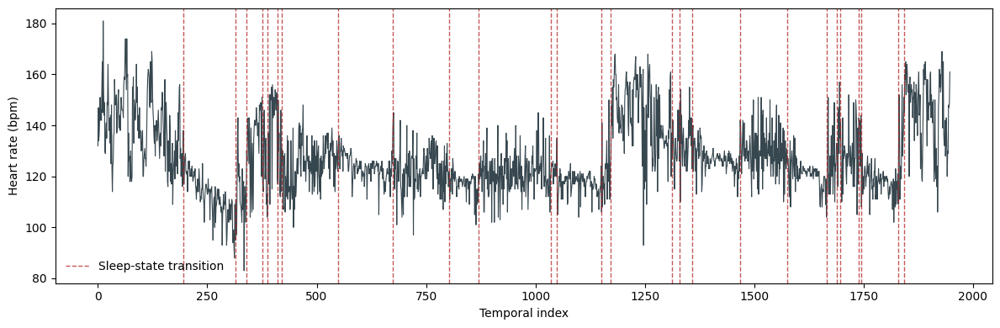

In [26]:
fig, ax = plt.subplots(
    figsize=(12, 4)
)

ax.plot(
    serie_baby_ecg_model,
    color="#37474F",
    linewidth=0.8
)

for i, cp in enumerate(change_points_model):
    ax.axvline(
        cp,
        color="#B22222",
        linestyle="--",
        linewidth=1,
        alpha=0.75,
        label=(
            "Sleep-state transition"
            if i == 0
            else None
        )
    )

ax.set_xlabel("Temporal index")
ax.set_ylabel("Heart rate (bpm)")
ax.legend(frameon=False)

fig.tight_layout()
plt.show()

### 7.1.2. Resultados


════════════════════════════════════════════════════════════════════════
                         Optimización Gaussiano                         
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 1948
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 28.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 28.0000

Dispersion of Cost
──────────────────
    Execution Time              : 14.3381 s
    Best Window                 : 58

Dispersion of Cost
──────────────────
    Execution Time              : 14.3381 s
    Best Window                 : 58

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 58

Selección final
──────

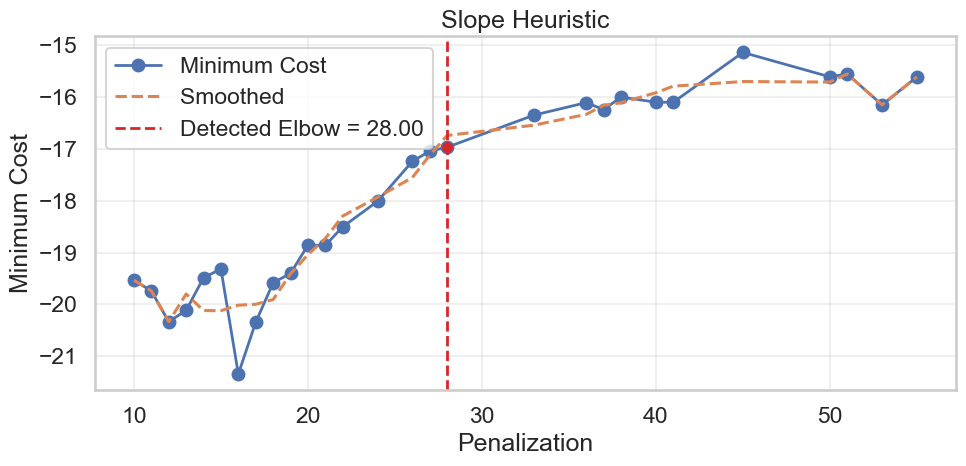

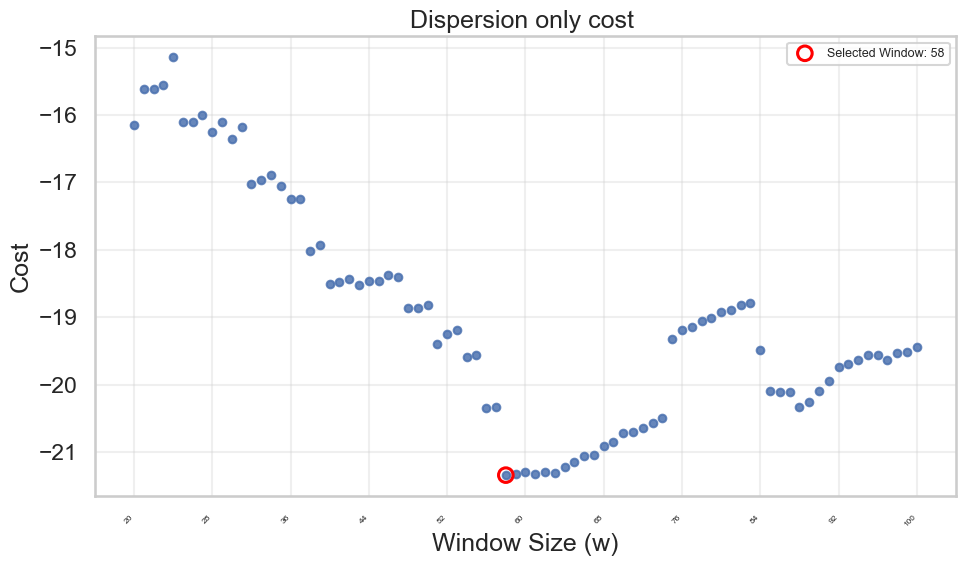

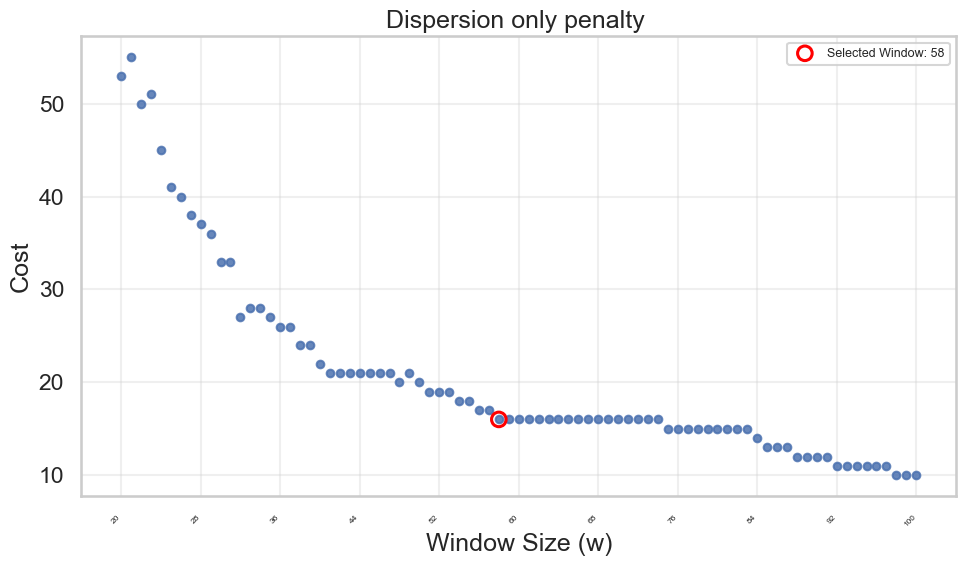

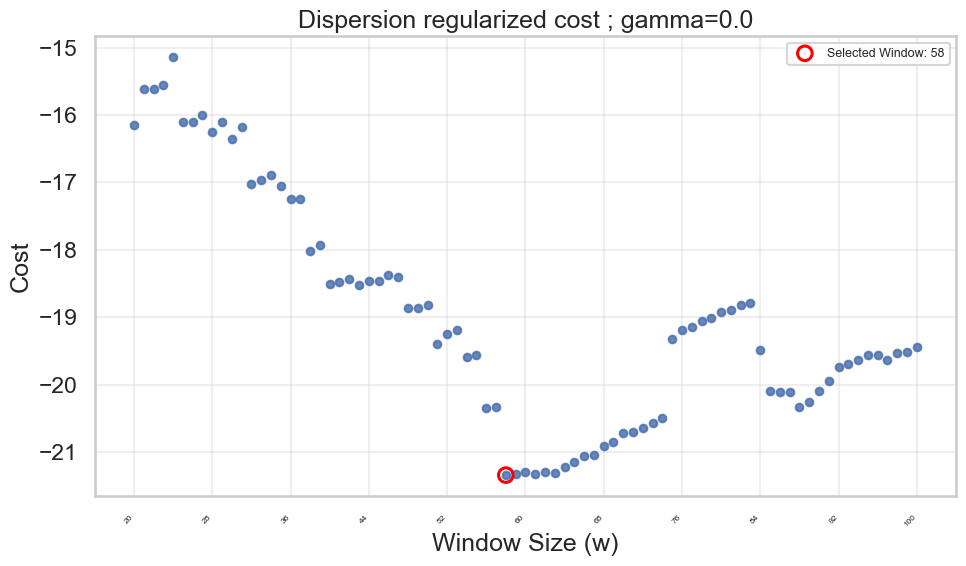

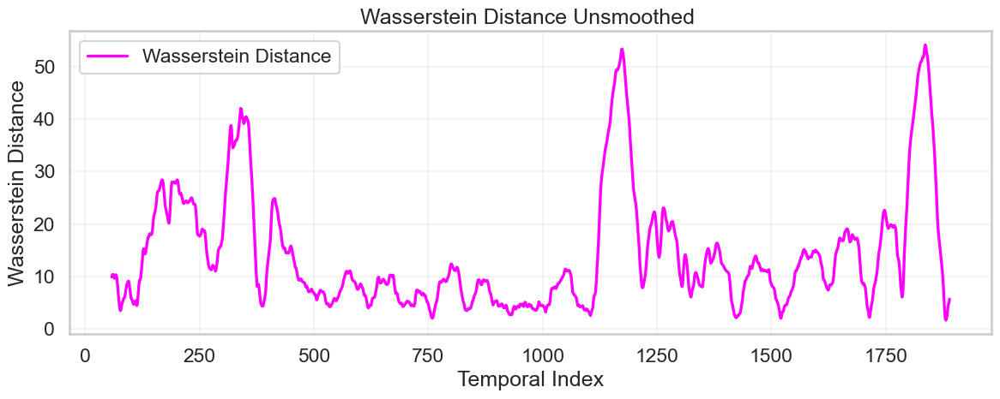

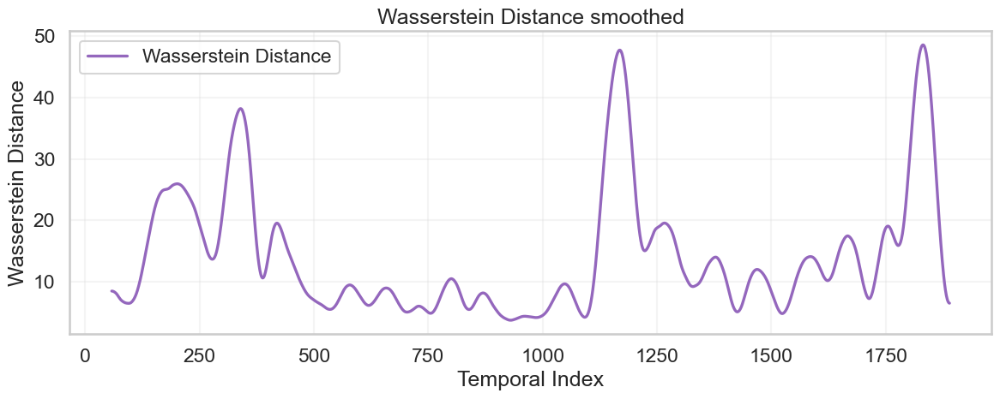

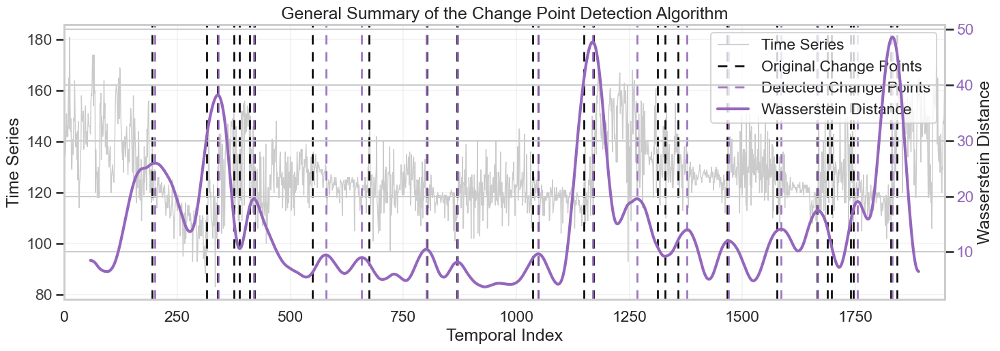

In [27]:
metrics_babyecg_gauss_opt = best_params_sh(
                                                                serie_baby_ecg_model,
                                                                change_points_model,
                                                                penal=True,
                                                                path='',
                                                                name=f"BabyECG",
                                                                modo="Gaussiano",
                                                                given=False,
                                                                thr_dist=20,
                                                                min_w = 20,
                                                                max_w = 100,
                                                                t_given=1,
                                                                smooth_distances=True,
                                                                save_fig=False,
                                                                visualization={
                                                                    "summary": True,
                                                                    "raw_distance": True,
                                                                    "smooth_distance": True,
                                                                    "cost": True,
                                                                    "slope": True,
                                                                },
                                                                temporal_comp=True)[0]


════════════════════════════════════════════════════════════════════════
                         Optimización Empírico                          
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 1948
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 25.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 25.0000

Dispersion of Cost
──────────────────
    Execution Time              : 13.6033 s
    Best Window                 : 59

Dispersion of Cost
──────────────────
    Execution Time              : 13.6033 s
    Best Window                 : 59

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 59

Selección final
──────

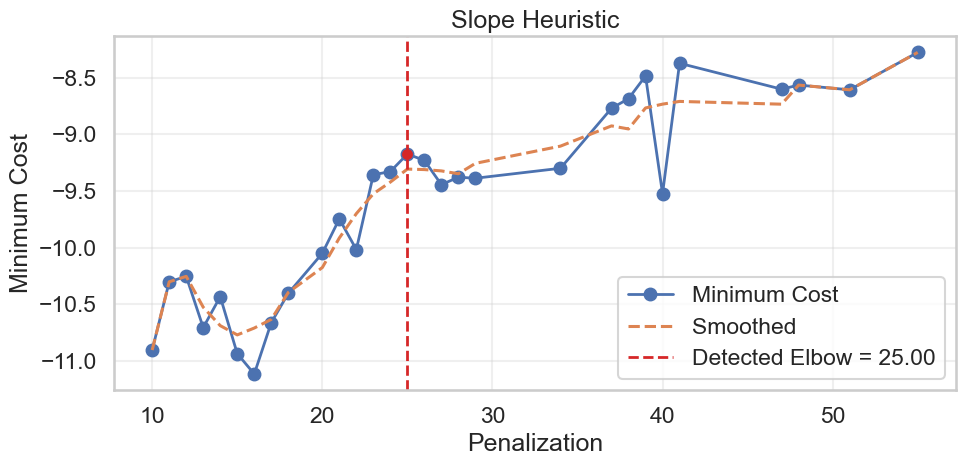

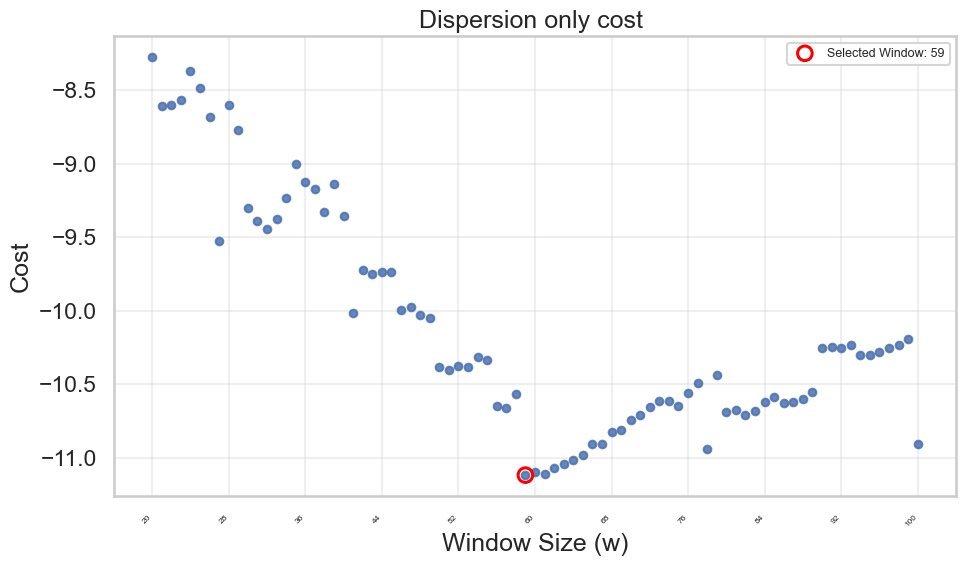

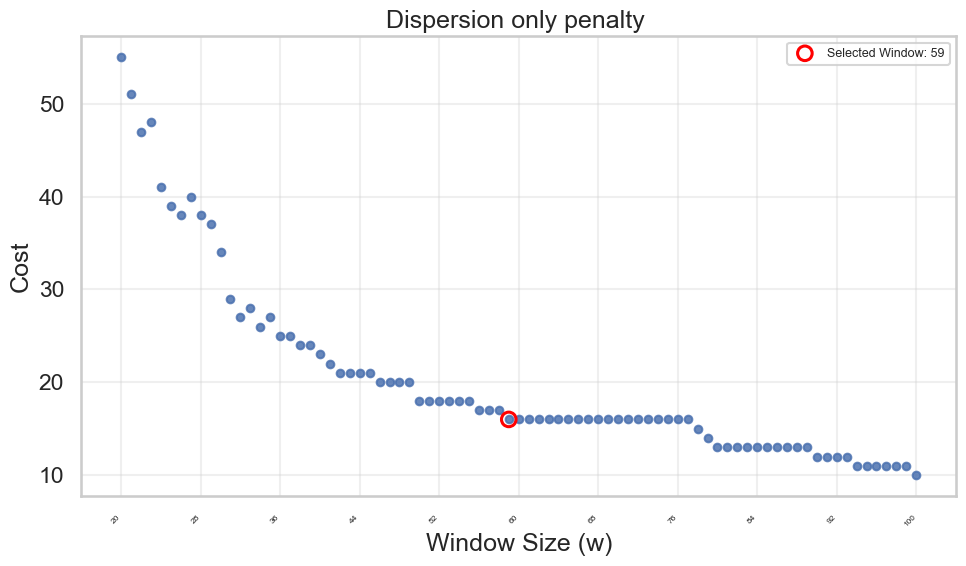

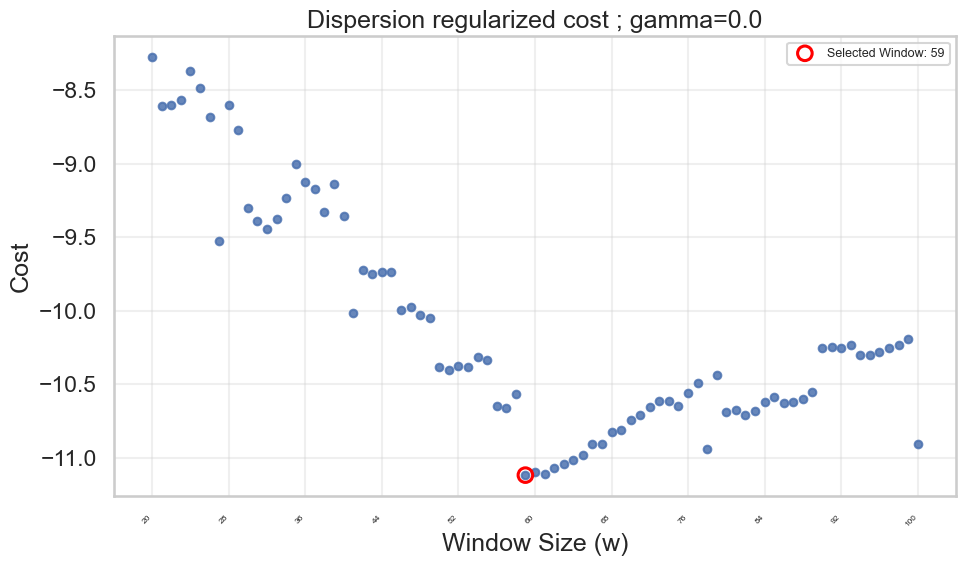

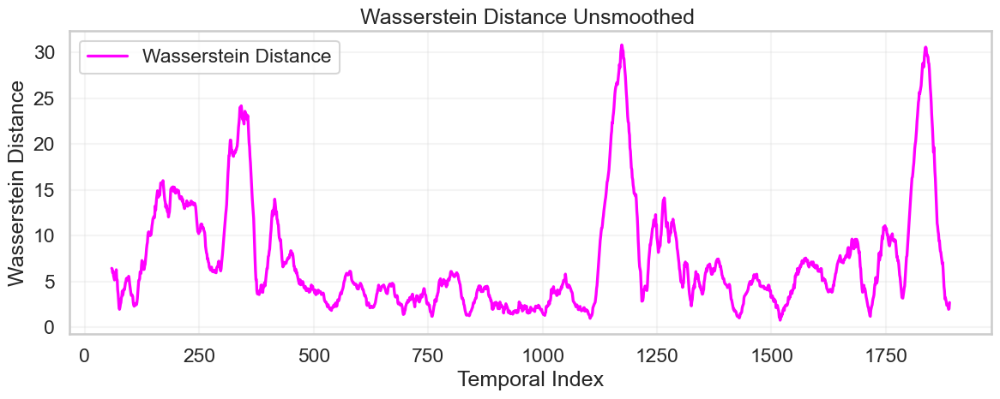

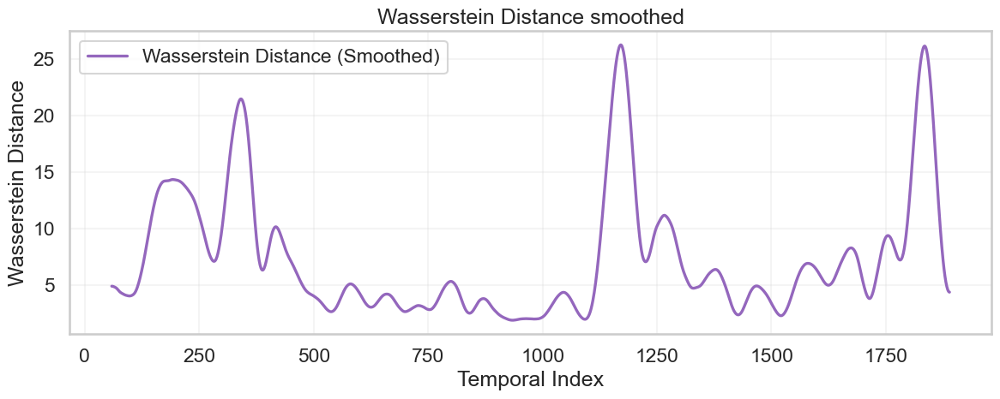

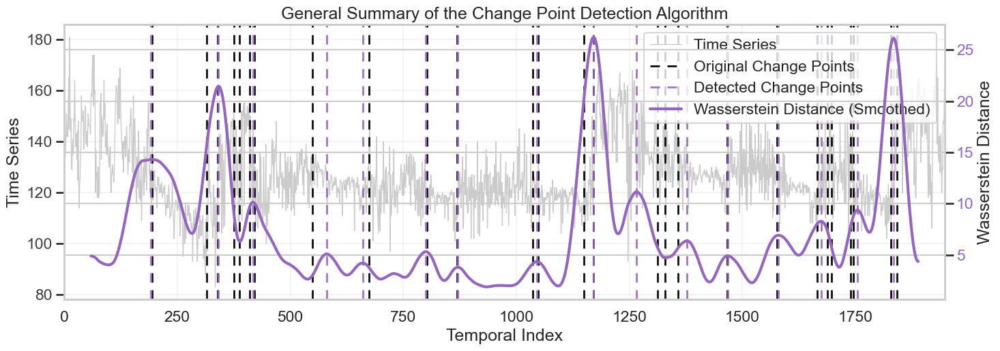

In [28]:
metrics_babyecg_emp_opt = best_params_sh(
                                                                serie_baby_ecg_model,
                                                                change_points_model,
                                                                penal=True,
                                                                path='',
                                                                name=f"BabyECG",
                                                                modo="Empírico",
                                                                given=False,
                                                                thr_dist=20,
                                                                min_w = 20,
                                                                max_w = 100,
                                                                t_given=1,
                                                                smooth_distances=True,
                                                                save_fig=False,
                                                                visualization={
                                                                    "summary": True,
                                                                    "raw_distance": True,
                                                                    "smooth_distance": True,
                                                                    "cost": True,
                                                                    "slope": True,
                                                                },
                                                                temporal_comp=True)[0]

In [29]:
puntos_cambio_roerich_babyecg = detectar_cambios_roerich(
                                serie_baby_ecg_model,
                                window_size=50,
                                seed=42,
                                periods=10
                            )

metrics_babyecg_roerich = metrics(change_points_model, puntos_cambio_roerich_babyecg, 20, len(serie_baby_ecg_model))[0]

In [30]:
puntos_cambio_window_rbf_babyecg = detectar_window_rbf(
                                serie_baby_ecg_model,
                                window=50
                            )

metrics_babyecg_window_rbf = metrics(change_points_model, puntos_cambio_window_rbf_babyecg, 20, len(serie_baby_ecg_model))[0]

In [36]:
w=50
cpd_gauss_babyecg_fw = CPD(serie_baby_ecg_model, window=w, t=1, medias=True, smooth=True, temporal_comp=True)
distancias_gauss_babyecg_fw = cpd_gauss_babyecg_fw.distancias()
cps_detect_gauss_babyecg_fw = detect(distancias_gauss_babyecg_fw, w)
metrics_babyecg_gauss_fw = metrics(change_points_model, cps_detect_gauss_babyecg_fw, 20, len(serie_baby_ecg_model))[0]

w_gauss_opt = 58
cpd_gauss_babyecg_opt = CPD(serie_baby_ecg_model, window=w_gauss_opt, t=1, medias=True, smooth=True, temporal_comp=True)
distancias_babyecg_opt = cpd_gauss_babyecg_opt.distancias()
cps_detect_gauss_babyecg_opt = detect(distancias_babyecg_opt, w_gauss_opt)


In [37]:
cpd_emp_babyecg = EmpiricalCPD(serie_baby_ecg_model, window=w, smooth=True)
distancias_babyecg_emp = cpd_emp_babyecg.distancias()
cps_detect_emp_babyecg_fw = detect(distancias_babyecg_emp, w)
metrics_babyecg_emp_fw = metrics(change_points_model, cps_detect_emp_babyecg_fw, 20, len(serie_baby_ecg_model))[0]

w_emp_opt = 59
cpd_emp_babyecg_opt = EmpiricalCPD(serie_baby_ecg_model, window=w_emp_opt, smooth=True)
distancias_babyecg_emp_opt = cpd_emp_babyecg_opt.distancias()
cps_detect_emp_babyecg_opt = detect(distancias_babyecg_emp_opt, w_emp_opt)

In [35]:
generar_tabla_desde_diccionarios(
    [[metrics_babyecg_gauss_opt], [metrics_babyecg_emp_opt], 
     [metrics_babyecg_gauss_fw], [metrics_babyecg_emp_fw], 
     [metrics_babyecg_roerich], [metrics_babyecg_window_rbf]],
    ["Gauss-Opt", "Empirical-Opt", 
     "Gauss-FW", "Empirical-FW", 
     "Roerich-KL", "Window-RBF"],
    ["Precision", "Recall", "F1 Score", "Mean Location Error"]
)

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss-Opt,0.875000,0.518519,0.651163,5.428571
1,Empirical-Opt,0.875000,0.518519,0.651163,5.500000
2,Gauss-FW,0.700000,0.518519,0.595745,6.357143
3,Empirical-FW,0.777778,0.518519,0.622222,7.214286
4,Roerich-KL,0.666667,0.370370,0.476190,6.200000
5,Window-RBF,0.454545,0.370370,0.408163,2.400000


In [40]:
cpd_gauss_babyecg_opt

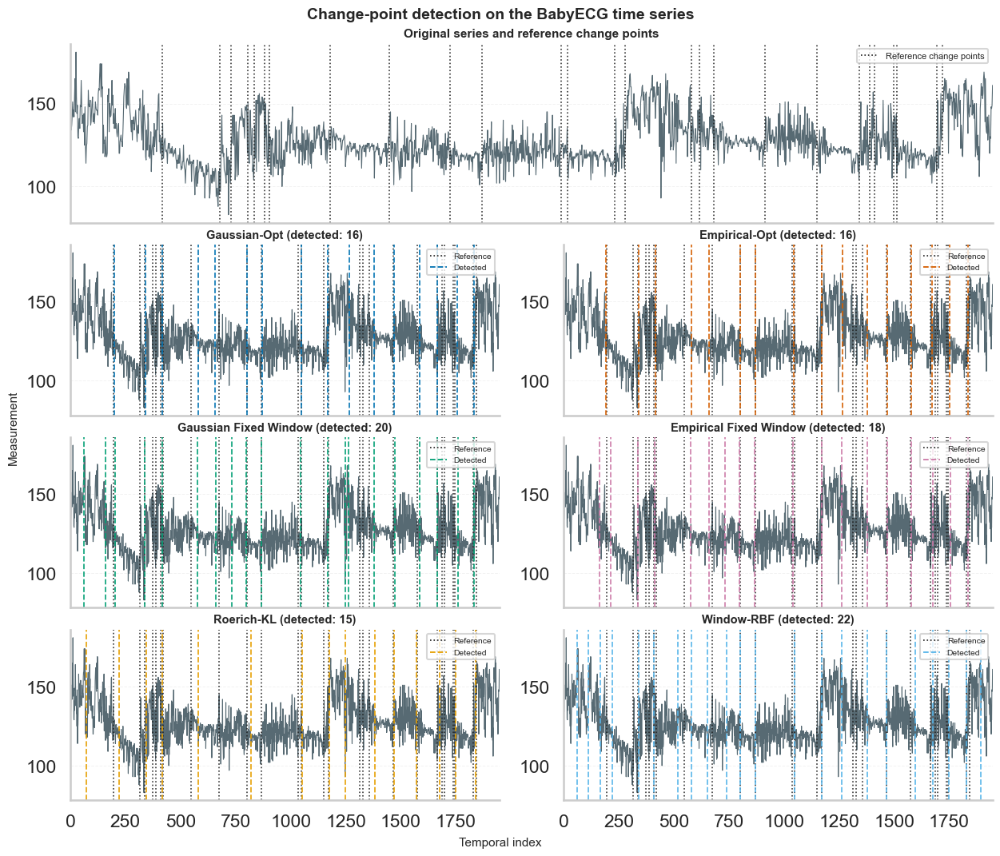

In [44]:
detected_cps = [
    cps_detect_gauss_babyecg_opt,
    cps_detect_emp_babyecg_opt,
    cps_detect_gauss_babyecg_fw,
    cps_detect_emp_babyecg_fw,
    puntos_cambio_roerich_babyecg,
    puntos_cambio_window_rbf_babyecg
]

method_names = [
    "Gaussian-Opt",
    "Empirical-Opt",
    "Gaussian Fixed Window",
    "Empirical Fixed Window",
    "Roerich-KL",
    "Window-RBF"
]

fig, axes = plot_change_points_by_method(
    serie=serie_baby_ecg_model,
    reference_change_points=change_points_model,
    detected_change_points=detected_cps,
    method_names=method_names,
    title="Change-point detection on the BabyECG time series",
    ylabel="Measurement",
    index_base=0
)

## 7.2. Well-Log

### 7.2.1. Carga y Visualización

In [38]:
import json
import numpy as np
from pathlib import Path


carpeta = Path("Real Data/Well_log")

# Serie original de 4050 observaciones
serie_well_log = np.loadtxt(
    carpeta / "well_log_original.txt",
    dtype=np.float64
)

# Versión reducida de TCPD
with open(
    carpeta / "well_log_tcpd.json",
    "r",
    encoding="utf-8"
) as archivo:

    datos_tcpd = json.load(archivo)

serie_well_log_tcpd = np.asarray(
    datos_tcpd["series"][0]["raw"],
    dtype=np.float64
)

print("Longitud original:", len(serie_well_log))
print("Longitud TCPD:", len(serie_well_log_tcpd))

Longitud original: 4050
Longitud TCPD: 675


In [39]:
with open(
    carpeta / "annotations.json",
    "r",
    encoding="utf-8"
) as archivo:

    todas_las_anotaciones = json.load(archivo)

anotaciones_well_log = todas_las_anotaciones[
    "well_log"
]

for anotador, puntos in anotaciones_well_log.items():
    print(
        f"Anotador {anotador}: "
        f"{len(puntos)} puntos -> {puntos}"
    )

Anotador 6: 11 puntos -> [179, 255, 281, 311, 343, 402, 413, 422, 432, 462, 464]
Anotador 7: 9 puntos -> [179, 255, 281, 312, 343, 402, 412, 422, 432]
Anotador 8: 9 puntos -> [179, 255, 282, 312, 343, 402, 413, 422, 432]
Anotador 12: 2 puntos -> [177, 467]
Anotador 13: 17 puntos -> [4, 179, 255, 281, 311, 344, 402, 412, 422, 432, 462, 464, 521, 526, 620, 643, 661]


In [40]:
cps_well_log = np.array(anotaciones_well_log['13'][1:])

In [41]:
factor_submuestreo = 6

change_points_well_log = (
    factor_submuestreo
    * cps_well_log
).astype(int)

print(change_points_well_log.tolist())

[1074, 1530, 1686, 1866, 2064, 2412, 2472, 2532, 2592, 2772, 2784, 3126, 3156, 3720, 3858, 3966]


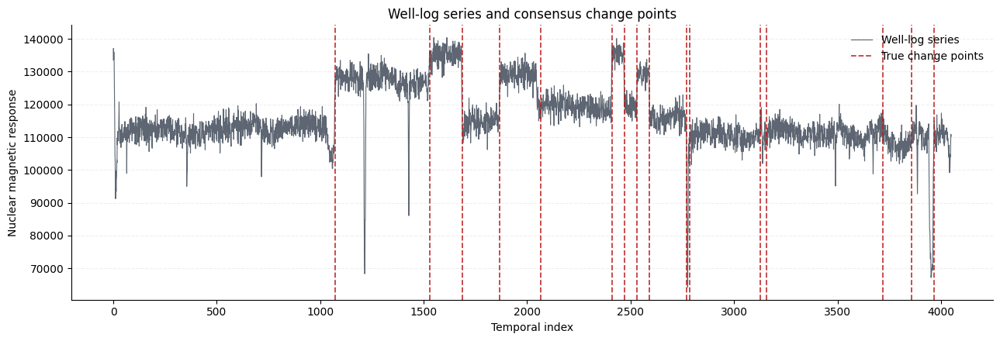

In [42]:
import matplotlib.pyplot as plt

def graficar_well_log(serie, true_cps, detect_cps=None):
    fig, ax = plt.subplots(
        figsize=(13, 4.5)
    )

    ax.plot(
        serie,
        color="#4B5563",
        linewidth=0.8,
        alpha=0.9,
        label="Well-log series"
    )

    for i, cp in enumerate(true_cps):
        ax.axvline(
            cp,
            color="#B91C1C",
            linestyle="--",
            linewidth=1.3,
            alpha=0.85,
            label=(
                "True change points"
                if i == 0
                else None
            )
        )

    if detect_cps != None:
        for i, cp in enumerate(detect_cps):
            ax.axvline(
                cp,
                color="blue",
                linestyle="--",
                linewidth=1.3,
                alpha=0.85,
                label=(
                    "Detected change points"
                    if i == 0
                    else None
                )
            )

    ax.set_xlabel("Temporal index")
    ax.set_ylabel("Nuclear magnetic response")
    ax.set_title(
        "Well-log series and consensus change points"
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.legend(
        frameon=False,
        loc="upper right"
    )

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.2
    )

    plt.tight_layout()
    plt.show()

graficar_well_log(serie_well_log, change_points_well_log)

### 7.2.2. Resultados

#### Resultados por Método


════════════════════════════════════════════════════════════════════════
                         Optimización Gaussiano                         
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 4050
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 18.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 18.0000

Dispersion of Cost
──────────────────
    Execution Time              : 37.4186 s
    Best Window                 : 189

Dispersion of Cost
──────────────────
    Execution Time              : 37.4186 s
    Best Window                 : 189

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 189

Selección final
───

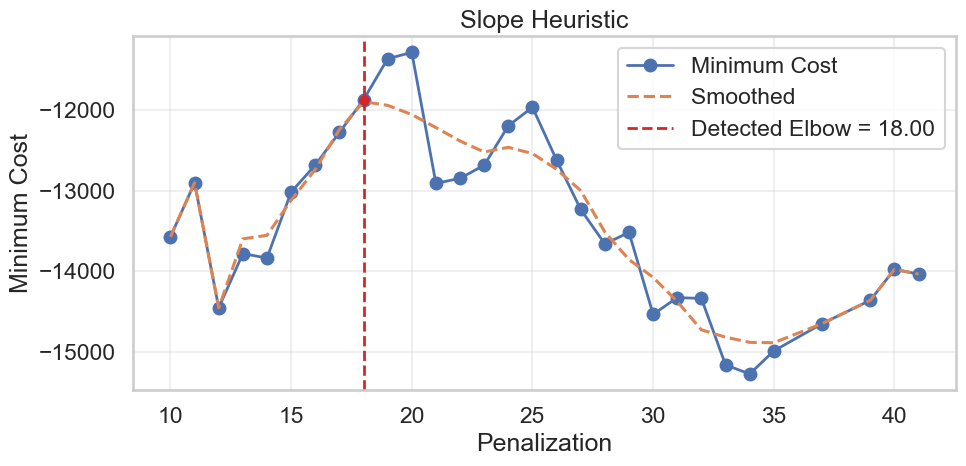

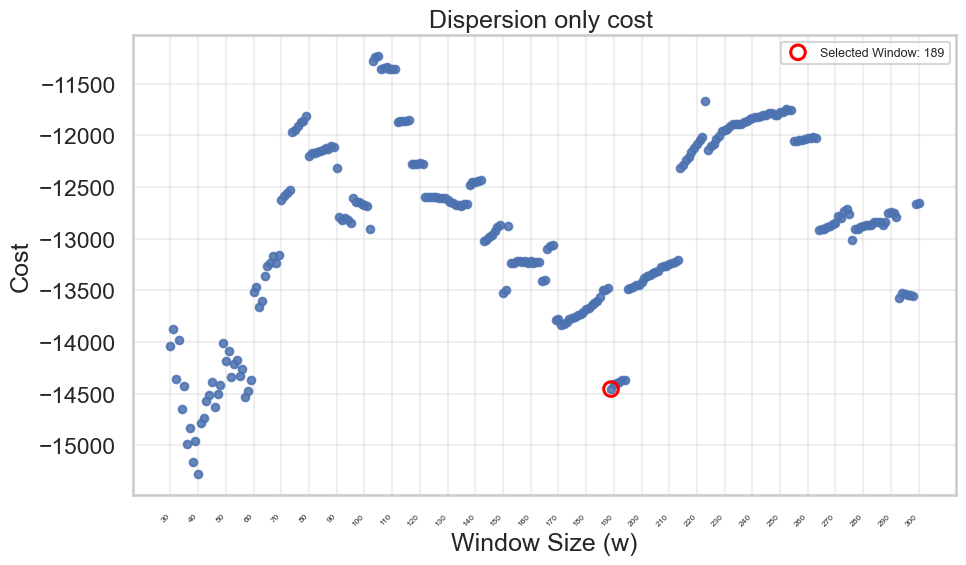

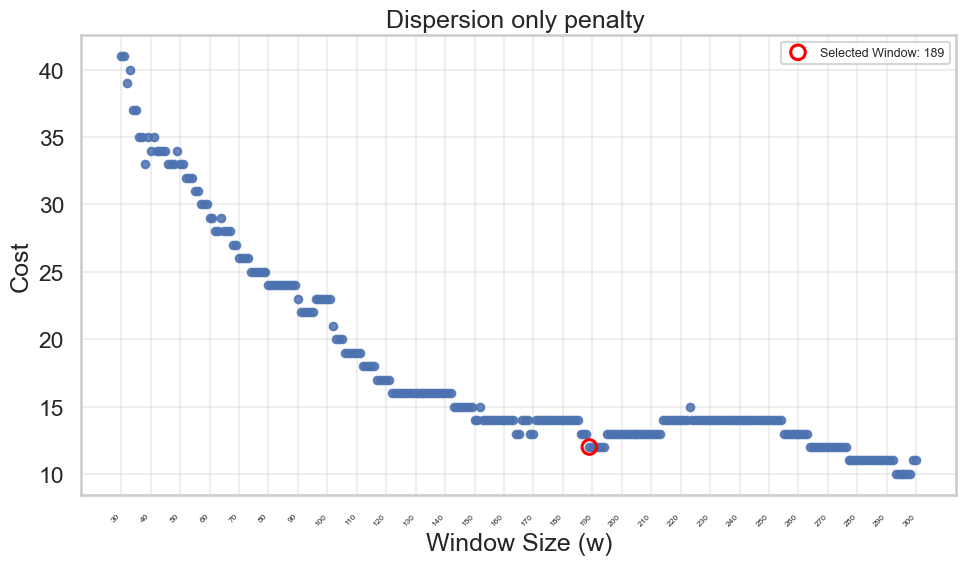

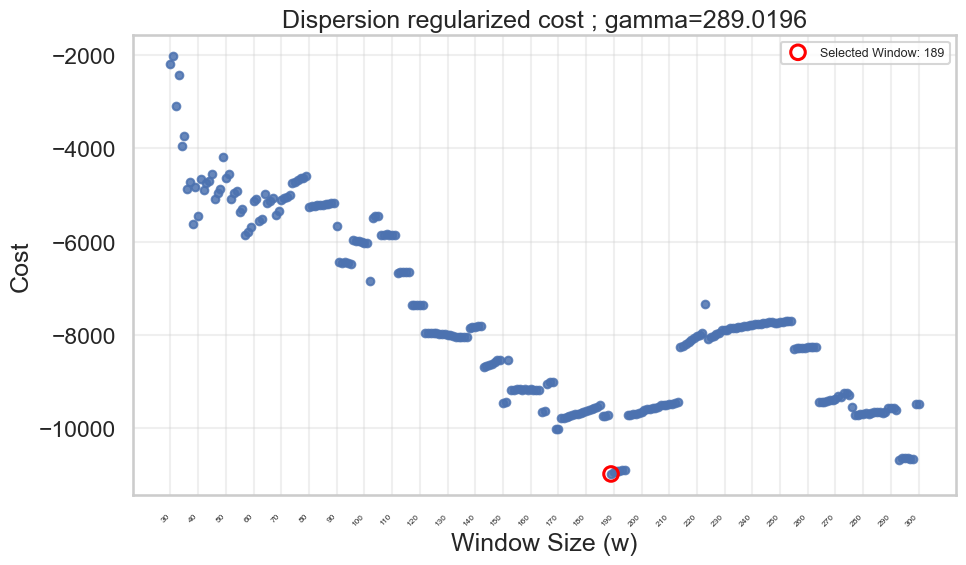

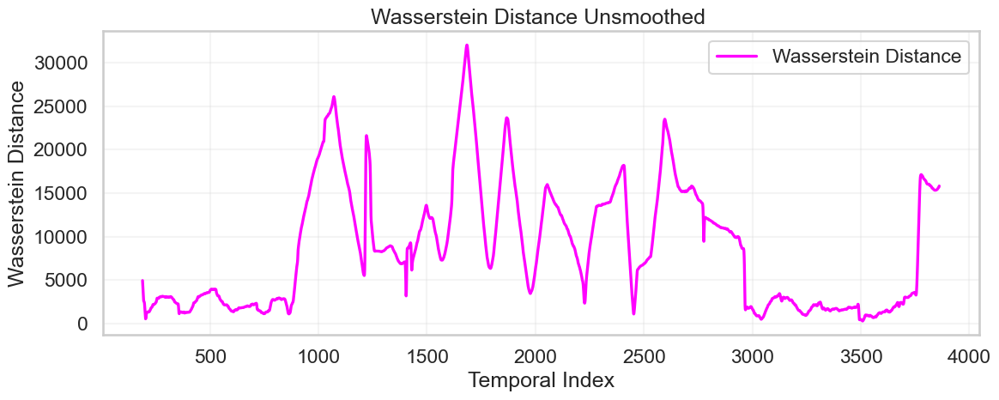

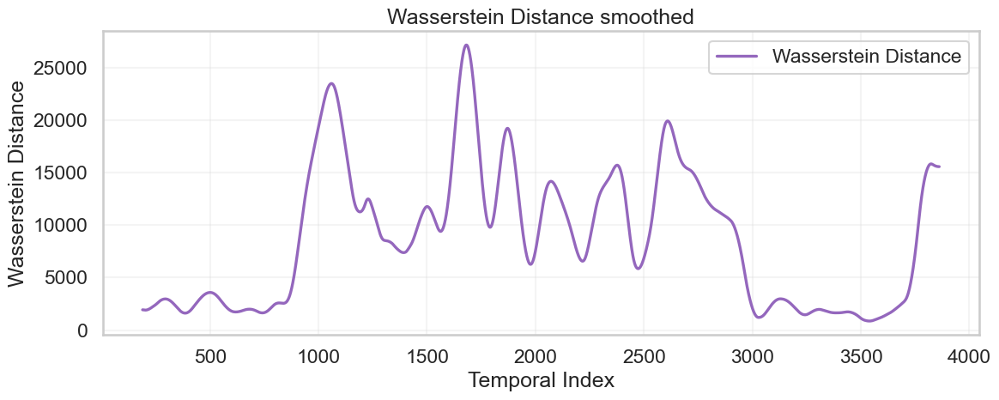

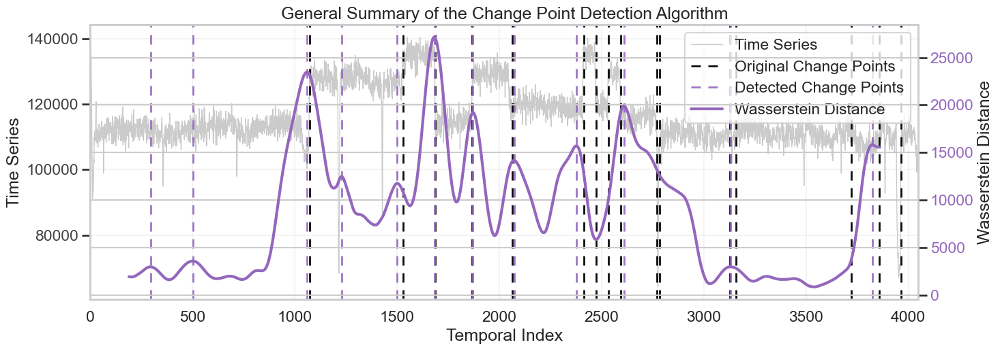

In [54]:
metrics_well_log_gauss_opt = best_params_sh(
                                                                serie_well_log,
                                                                change_points_well_log,
                                                                penal=True,
                                                                path='',
                                                                name=f"Well_Log",
                                                                modo="Gaussiano",
                                                                given=False,
                                                                thr_dist=30,
                                                                min_w = 30,
                                                                max_w = 300,
                                                                t_given=1,
                                                                smooth_distances=True,
                                                                save_fig=False,
                                                                visualization={
                                                                    "summary": True,
                                                                    "raw_distance": True,
                                                                    "smooth_distance": True,
                                                                    "cost": True,
                                                                    "slope": True,
                                                                },
                                                                temporal_comp=True,
                                                                max_bandwidth=True)[0]


════════════════════════════════════════════════════════════════════════
                         Optimización Empírico                          
════════════════════════════════════════════════════════════════════════
    Tamaño de serie             : 4050
    Penalización                : Sí
    Codo dado                   : No
    Codo geométrico             : Sí

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 21.0000

Detección de codo
─────────────────
    Método                      : Geométrico
    Punto umbral                : 21.0000

Dispersion of Cost
──────────────────
    Execution Time              : 20.1884 s
    Best Window                 : 295

Dispersion of Cost
──────────────────
    Execution Time              : 20.1884 s
    Best Window                 : 295

Dispersion of Cost
──────────────────
    Execution Time              : 0.0000 s
    Best Window                 : 295

Selección final
───

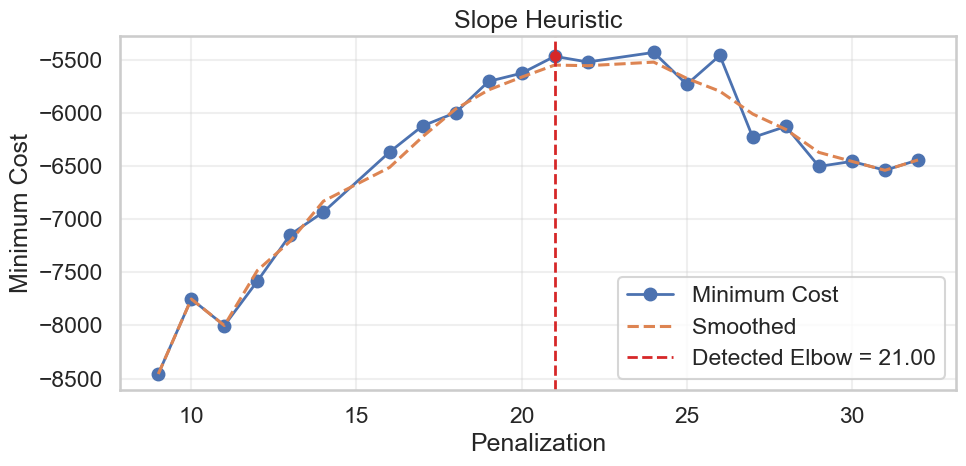

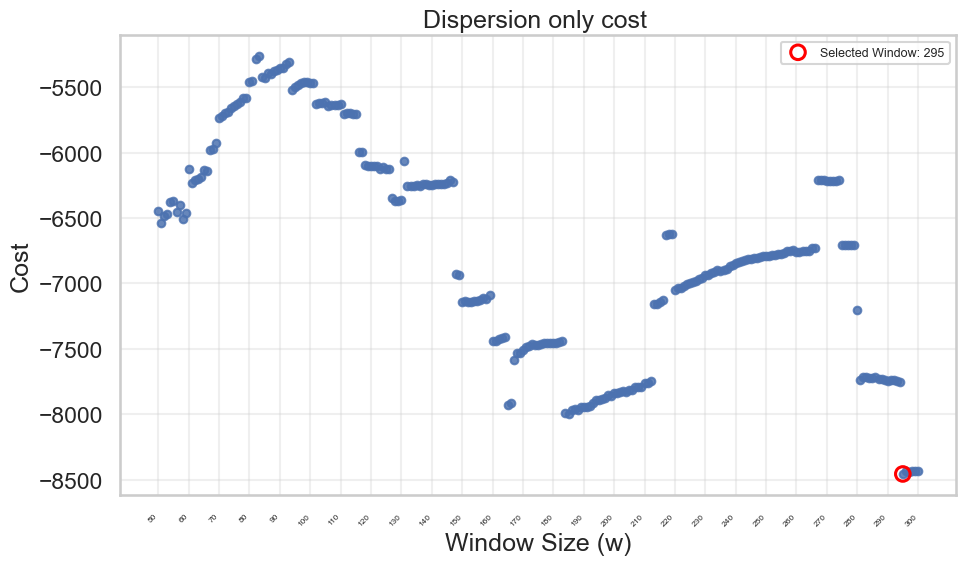

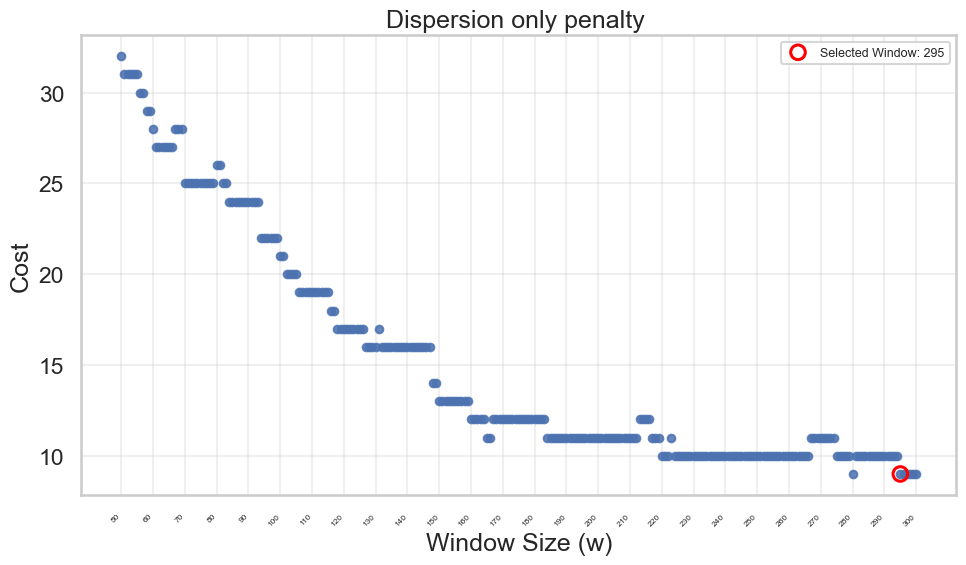

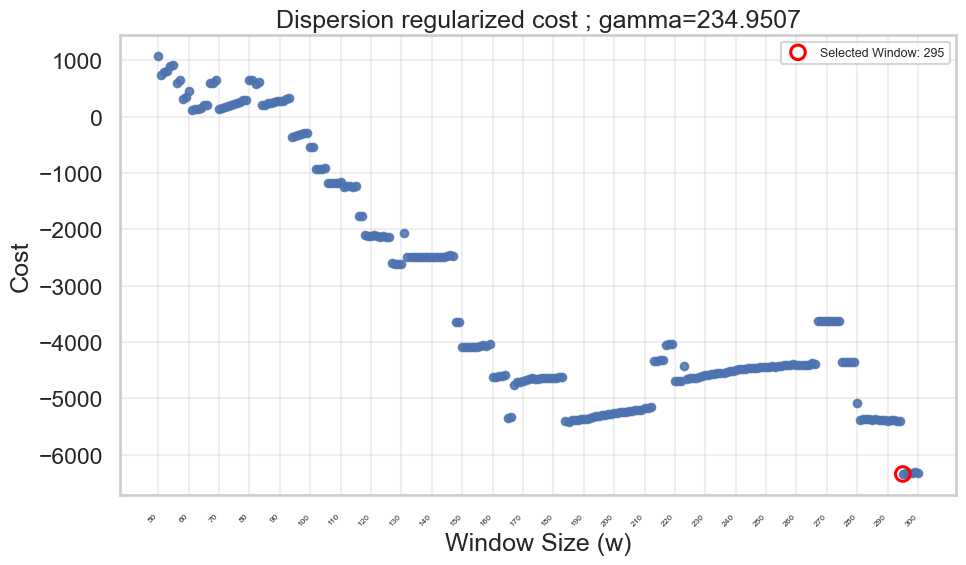

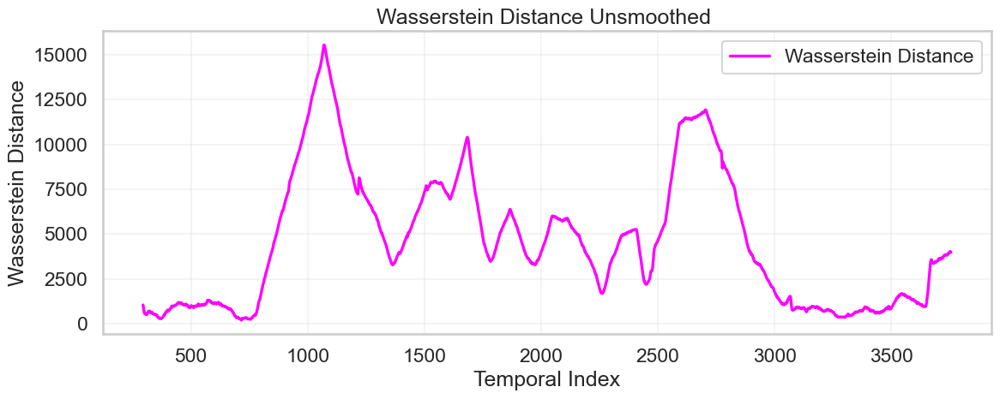

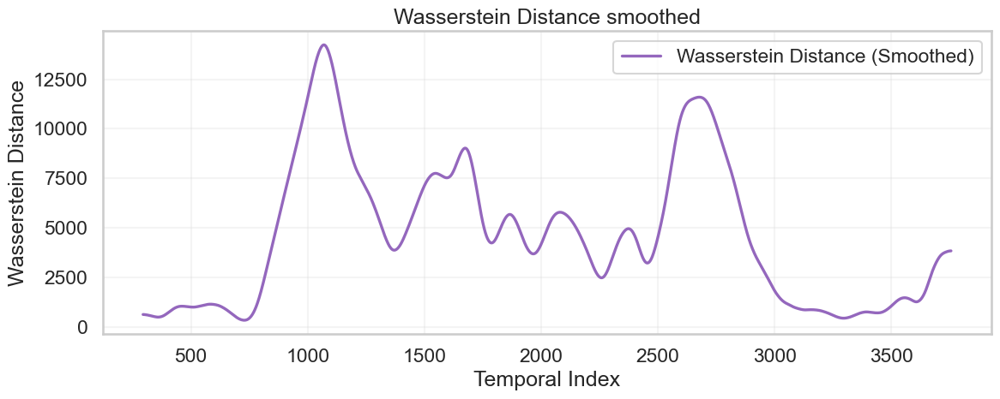

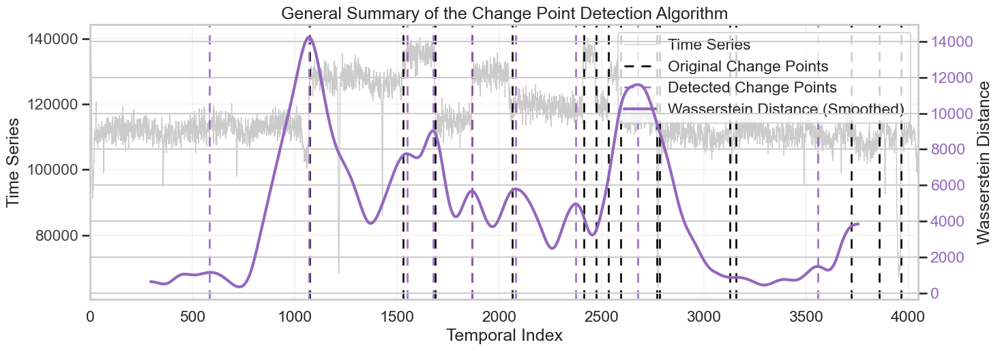

In [55]:
metrics_well_log_emp_opt = best_params_sh(
                                                                serie_well_log,
                                                                change_points_well_log,
                                                                penal=True,
                                                                path='',
                                                                name=f"Well_log",
                                                                modo="Empírico",
                                                                given=False,
                                                                thr_dist=30,
                                                                min_w = 50,
                                                                max_w = 300,
                                                                t_given=1,
                                                                smooth_distances=True,
                                                                save_fig=False,
                                                                visualization={
                                                                    "summary": True,
                                                                    "raw_distance": True,
                                                                    "smooth_distance": True,
                                                                    "cost": True,
                                                                    "slope": True,
                                                                },
                                                                temporal_comp=True,
                                                                max_bandwidth=True)[0]

In [50]:
puntos_cambio_roerich_well_log = detectar_cambios_roerich(
                                serie_well_log,
                                window_size=50,
                                seed=42,
                                periods=3
                            )

metrics_well_log_roerich = metrics(change_points_well_log, puntos_cambio_roerich_well_log, 30, len(serie_well_log))[0]

In [51]:
puntos_cambio_window_rbf_well_log = detectar_window_rbf(
                                serie_well_log,
                                window=50
                            )

metrics_well_log_window_rbf = metrics(change_points_well_log, puntos_cambio_window_rbf_well_log, 30, len(serie_well_log))[0]

In [52]:
w=50

cpd_gauss_well_log = CPD(serie_well_log, window=w, t=1, medias=True, smooth=True, temporal_comp=True)
distancias_well_log = cpd_gauss_well_log.distancias()
cps_detect_gauss_well_log_fw = detect(distancias_well_log, w)
metrics_well_log_gauss_fw = metrics(change_points_well_log, cps_detect_gauss_well_log_fw, 30, len(serie_well_log))[0]

w_gauss_opt = 40
cpd_gauss_well_log_opt = CPD(serie_well_log, window=w_gauss_opt, t=1, medias=True, smooth=True, temporal_comp=True)
distancias_well_log_opt = cpd_gauss_well_log_opt.distancias()
cps_detect_gauss_well_log_opt = detect(distancias_well_log_opt, w_gauss_opt)

In [53]:
cpd_emp_well_log = EmpiricalCPD(serie_well_log, window=w, smooth=True)
distancias_well_log_emp = cpd_emp_well_log.distancias()
cps_detect_emp_well_log_fw = detect(distancias_well_log_emp, w)
metrics_well_log_emp_fw = metrics(change_points_well_log, cps_detect_emp_well_log_fw, 30, len(serie_well_log))[0]

w_emp_opt = 295
cpd_emp_well_log_opt = EmpiricalCPD(serie_well_log, window=w_emp_opt, smooth=True)
distancias_well_log_emp_opt = cpd_emp_well_log_opt.distancias()
cps_detect_emp_well_log_opt = detect(distancias_well_log_emp_opt, w_emp_opt)

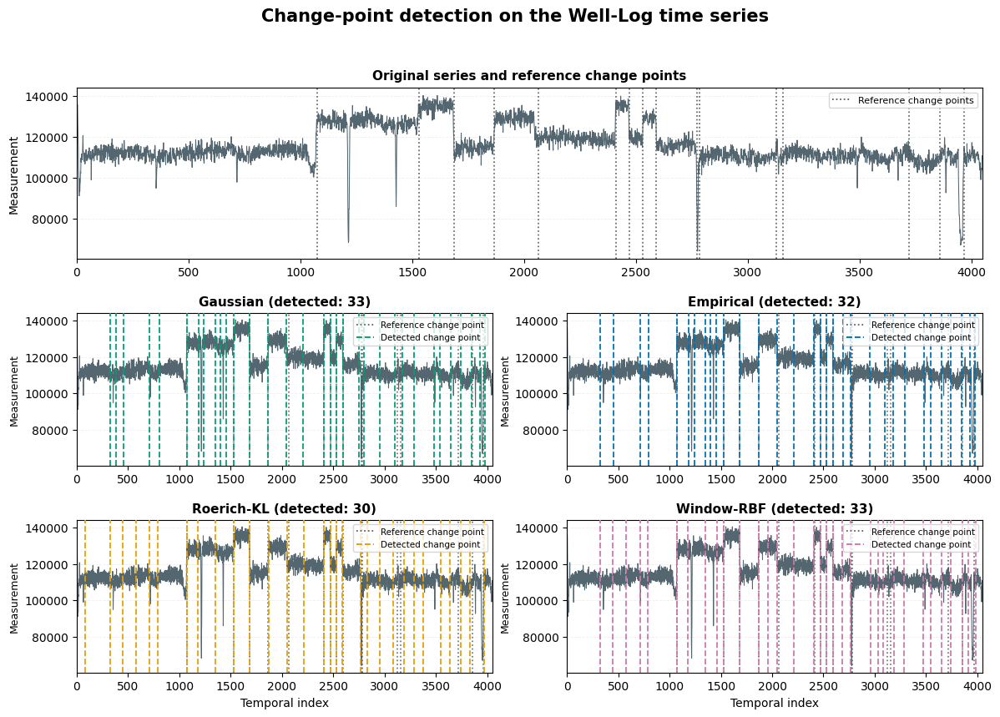

In [57]:
detected_cps = [
    cps_detect_gauss_well_log_fw,
    cps_detect_emp_well_log_fw,
    puntos_cambio_roerich_well_log,
    puntos_cambio_window_rbf_well_log
]

method_names = [
    "Gaussian",
    "Empirical",
    "Roerich-KL",
    "Window-RBF"
]

fig = plot_change_points_by_method(
    serie=serie_well_log,
    puntos_cambio_referencia=change_points_well_log,
    lista_puntos_detectados=detected_cps,
    nombres_metodos=method_names,
    titulo="Change-point detection on the Well-Log time series",
    ylabel="Measurement"
)



#### Tabla Promedios

In [63]:
avg_table = generar_tabla_desde_diccionarios(
                                            [[metrics_well_log_gauss_fw], [metrics_well_log_emp_fw], 
                                            [metrics_well_log_roerich], [metrics_well_log_window_rbf]],
                                            ["Gauss-FW", "Empirical-FW", 
                                            "Roerich-KL", "Window-RBF"],
                                            ["Precision", "Recall", "F1 Score", "Mean Location Error"]
                                        )

avg_table

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss-FW,0.484848,1.000,0.653061,10.312500
1,Empirical-FW,0.437500,0.875,0.583333,7.857143
2,Roerich-KL,0.451613,0.875,0.595745,8.714286
3,Window-RBF,0.424242,0.875,0.571429,7.714286


In [64]:
ruta_log_well = f"Resultados_Datos_Reales/Resultados_log_well/log_well_metrics.xlsx"

avg_table.to_excel(ruta_log_well, index=False)

## 7.3. HASC

### 7.3.1. Carga y Visualización

In [2]:
from pathlib import Path

import numpy as np
from scipy.io import loadmat


ruta_hasc = (
    Path("Real Data")
    / "HASC-PAC2016"
)

datos = []

for archivo in ruta_hasc.rglob("*.mat"):

    contenido = loadmat(
        archivo,
        variable_names=["Y", "L"]
    )

    # Serie tridimensional del acelerómetro.
    aceleracion = np.asarray(
        contenido["Y"],
        dtype=float
    )

    # Asegurar la forma (n_observaciones, 3).
    if aceleracion.shape[0] == 3:
        aceleracion = aceleracion.T

    # Conversión a serie univariada.
    serie = np.linalg.norm(
        aceleracion,
        axis=1
    )

    # Índices de los puntos de cambio verdaderos.
    puntos_cambio = np.flatnonzero(
        np.asarray(contenido["L"]).ravel() != 0
    ).astype(int)

    datos.append({
        "nombre": archivo.stem,
        "serie": serie,
        "puntos_cambio": puntos_cambio,
        "longitud": len(serie)
    })


# Ordenar todas las series de mayor a menor longitud.
datos.sort(
    key=lambda elemento: elemento["longitud"],
    reverse=True
)

# Conservar únicamente las 30 más largas.
datos = datos[:30]


# Lista de listas con las 30 series univariadas.
series_hasc = [
    elemento["serie"].tolist()
    for elemento in datos
]

# Lista de listas con sus respectivos puntos de cambio.
change_points_hasc = [
    elemento["puntos_cambio"].tolist()
    for elemento in datos
]

# Nombres correspondientes, en el mismo orden.
nombres_hasc = [
    elemento["nombre"]
    for elemento in datos
]

# Lista que mantiene cada serie junto a sus puntos de cambio.
datos_hasc = [
    [serie, puntos_cambio]
    for serie, puntos_cambio in zip(
        series_hasc,
        change_points_hasc
    )
]

In [5]:
import matplotlib.pyplot as plt


def graficar_hasc(
    serie,
    true_cps,
    detect_cps=None
):
    fig, ax = plt.subplots(
        figsize=(13, 4.5)
    )

    ax.plot(
        serie,
        color="#4B5563",
        linewidth=0.8,
        alpha=0.9,
        label="HASC time series"
    )

    for i, cp in enumerate(true_cps):
        ax.axvline(
            cp,
            color="#B91C1C",
            linestyle="--",
            linewidth=1.3,
            alpha=0.85,
            label=(
                "Reference change points"
                if i == 0
                else None
            )
        )

    if detect_cps is not None:
        for i, cp in enumerate(detect_cps):
            ax.axvline(
                cp,
                color="#2563EB",
                linestyle="--",
                linewidth=1.3,
                alpha=0.85,
                label=(
                    "Detected change points"
                    if i == 0
                    else None
                )
            )

    ax.set_xlabel("Temporal index")
    ax.set_ylabel("Acceleration magnitude")
    ax.set_title(
        "HASC time series and change points"
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.legend(
        frameon=False,
        loc="upper right"
    )

    # Solo cuadrícula horizontal para evitar confundirla
    # con las líneas de los puntos de cambio.
    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.2
    )

    plt.tight_layout()
    plt.show()

    return fig, ax

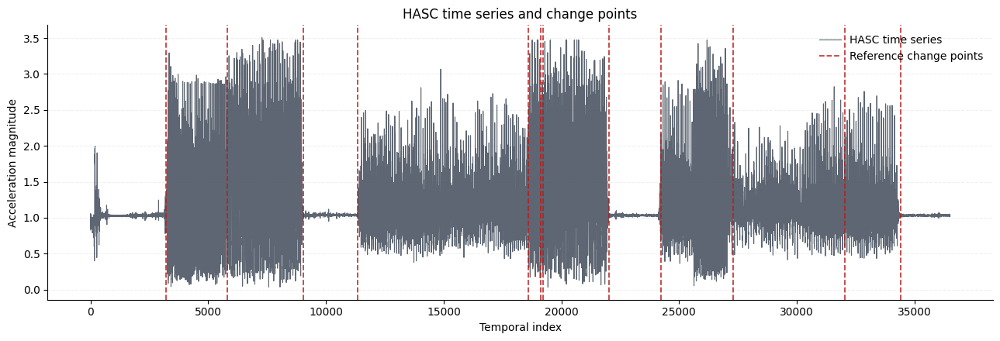

(<Figure size 1300x450 with 1 Axes>,
 <Axes: title={'center': 'HASC time series and change points'}, xlabel='Temporal index', ylabel='Acceleration magnitude'>)

In [6]:
graficar_hasc(
    series_hasc[2],
    change_points_hasc[2]
)

### 7.3.2.

In [10]:
w=500
delta = 250

metrics_hasc_emp = []
metrics_hasc_gauss = []
i = 0
for serie, cps_hasc in zip(series_hasc, change_points_hasc):
    i+=1
    print(i)
    cpd_emp_hasc = EmpiricalCPD(serie, window=w, smooth=True)
    distancias_hasc_emp = cpd_emp_hasc.distancias()
    cps_detect_emp_hasc = detect(distancias_hasc_emp, w)
    metrics_hasc_emp.append(metrics(cps_hasc, cps_detect_emp_hasc, delta, len(serie))[0])


    cpd_gauss_hasc = CPD(serie, window=w, t=1, medias=True, smooth=True, temporal_comp=True)
    distancias_hasc_gauss = cpd_gauss_hasc.distancias()
    cps_detect_gauss_hasc = detect(distancias_hasc_gauss, w)
    metrics_hasc_gauss.append(metrics(cps_hasc, cps_detect_gauss_hasc, delta, len(serie))[0])


1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30


In [ ]:
w=500
delta = 250

metrics_hasc_roerich = []
metrics_hasc_window_rbf = []
i = 0
for serie, cps_hasc in zip(series_hasc, change_points_hasc):
    i+=1
    print(i)

    puntos_cambio_window_rbf_hasc = detectar_window_rbf(
                                serie,
                                window=w
                            )
    
    metrics_hasc_window_rbf.append(metrics(cps_hasc, puntos_cambio_window_rbf_hasc, delta, len(serie))[0])

    puntos_cambio_roerich_hasc = detectar_cambios_roerich(
                                serie,
                                window_size=w,
                                seed=42,
                                periods=3
                            )

    metrics_hasc_roerich.append(metrics(cps_hasc, puntos_cambio_roerich_hasc, delta, len(serie))[0])

1


In [ ]:
generar_tabla_desde_diccionarios(
                                                        [metrics_hasc_gauss, metrics_hasc_emp, metrics_hasc_roerich, metrics_hasc_window_rbf],
                                                        ["Gauss", "Empirical", "Roerich-KL", "Window-RBF"],
                                                        ["Precision", "Recall", "F1 Score", "Mean Location Error"]
                                                        )

,Method,Precision,Recall,F1 Score,Mean Location Error
0,Gauss,0.632870,0.923395,0.742979,73.734209
1,Empirical,0.636597,0.900365,0.738836,88.281480
